In [ ]:

# Data Science Assignment 2
## Exploratory Data Analysis of Two Real-World Datasets

Roll Number: 23L-0977
Institution: FAST-NUCES Lahore

Netflix Dataset Source: https://www.kaggle.com/datasets/shivamb/netflix-shows

Published Cleaned Netflix Dataset: To be added after publication
Dataset Version: v1.0 (planned)

Published Cleaned Supermarket Dataset: To be added after publication
Dataset Version: v1.0 (planned)

---

# Part A: Netflix Movies and TV Shows

## A1. Dataset Understanding

### Introduction

In this part of the assignment, I will explore the Netflix Movies and TV Shows dataset to understand what kind of information it contains and identify any issues that might affect the analysis.

The dataset includes details about movies and TV shows, such as their titles, release years, countries, ratings, durations, and genres.

I will begin by examining the structure of the dataset, including the number of records, columns, and data types. After that, I will classify the variables based on their roles in the analysis.


In [1]:
# Import the libraries required for this assignment

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Set up the display
pd.set_option("display.max_columns", None)

# Load the Netflix dataset
netflix_df = pd.read_csv("netflix_titles.csv")

# Display dataset dimensions
print("Number of Rows:", netflix_df.shape[0])
print("Number of Columns:", netflix_df.shape[1])

# Display the first five records
print("\nFirst Five Records:")
display(netflix_df.head())

# Display data types
print("\nColumn Data Types:")
display(netflix_df.dtypes.to_frame("Data Type"))

Number of Rows: 8807
Number of Columns: 12

First Five Records:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



Column Data Types:


,Data Type
show_id,str
type,str
title,str
director,str
cast,str
country,str
date_added,str
release_year,int64
rating,str
duration,str


In [ ]:

### Interpretation

The Netflix dataset contains 8,807 rows and 12 columns. Each row represents one movie or TV show listed in the Netflix catalogue.

The dataset contains different types of information. For example, release_year is stored as an integer, while columns such as type, rating, and country contain categorical information.

Some columns need further processing before they can be analyzed properly. In particular, date_added is currently stored as a string, and duration contains both movie lengths in minutes and TV show lengths in seasons.

Understanding these differences will help me choose suitable cleaning methods and visualizations in the following sections.


In [ ]:

### Variable Role Classification

Before analyzing the data, I classified each column according to the type of information it contains.

This is useful because numerical, categorical, and text-based variables cannot always be analyzed using the same methods.

Some columns also contain multiple values in a single cell, such as countries, cast members, and genres. These will need additional processing in later sections.


In [2]:
# Define the type and purpose of each column

variable_roles = [
    ["show_id", "Identifier",
     "Unique ID assigned to each title"],

    ["type", "Categorical",
     "Identifies whether the title is a movie or TV show"],

    ["title", "Text",
     "Name of the movie or TV show"],

    ["director", "Multi-valued categorical",
     "Director or directors associated with the title"],

    ["cast", "Multi-valued categorical",
     "Actors and performers in the title"],

    ["country", "Multi-valued categorical",
     "Countries associated with the production"],

    ["date_added", "Date",
     "Date when the title was added to Netflix"],

    ["release_year", "Numerical (discrete)",
     "Year in which the title was originally released"],

    ["rating", "Categorical",
     "Audience maturity classification"],

    ["duration", "Mixed",
     "Movie length in minutes or TV show seasons"],

    ["listed_in", "Multi-valued categorical",
     "Genres and content categories"],

    ["description", "Text",
     "Short description of the title"]
]

role_table = pd.DataFrame(
    variable_roles,
    columns=["Column", "Variable Type", "Purpose"]
)

display(role_table)

,Column,Variable Type,Purpose
0,show_id,Identifier,Unique ID assigned to each title
1,type,Categorical,Identifies whether the title is a movie or TV ...
2,title,Text,Name of the movie or TV show
3,director,Multi-valued categorical,Director or directors associated with the title
4,cast,Multi-valued categorical,Actors and performers in the title
5,country,Multi-valued categorical,Countries associated with the production
6,date_added,Date,Date when the title was added to Netflix
7,release_year,Numerical (discrete),Year in which the title was originally released
8,rating,Categorical,Audience maturity classification
9,duration,Mixed,Movie length in minutes or TV show seasons


In [ ]:

### Interpretation

The variable classification shows that the Netflix dataset contains a mixture of numerical, categorical, date, and text-based information.

The show_id column is mainly useful for identifying records and checking for duplicates. It does not provide meaningful numerical information for statistical analysis.

The type and rating columns can be used to compare different categories of Netflix content, while release_year can help identify trends over time.

The director, cast, country, and listed_in columns may contain multiple values separated by commas. These will need to be handled carefully when counting individual categories.

The duration column also requires attention because movies are measured in minutes while TV shows are measured in seasons. Comparing these values directly would not be meaningful.

The description column contains text that could be useful for future text analysis, although it is not a main focus of this assignment.


In [ ]:

## A2. Data Quality Assessment

Before cleaning the Netflix dataset, I examined it to identify problems that could affect the analysis.

I checked for missing values, duplicate records, incorrect data types, inconsistent categorical values, suspicious entries, and outliers.

The purpose of these checks is to understand the problems in the original data before deciding how to handle them.


In [ ]:

### A2.1 Missing Values

I started by checking how many values are missing from each column.

Along with the number of missing values, I calculated their percentages to understand how much of the dataset is affected.

This will help me decide whether missing values should be replaced, left unchanged, or handled in another way during cleaning.


,Missing Count,Missing Percentage
show_id,0,0.00
type,0,0.00
title,0,0.00
director,2634,29.91
cast,825,9.37
country,831,9.44
date_added,10,0.11
release_year,0,0.00
rating,4,0.05
duration,3,0.03


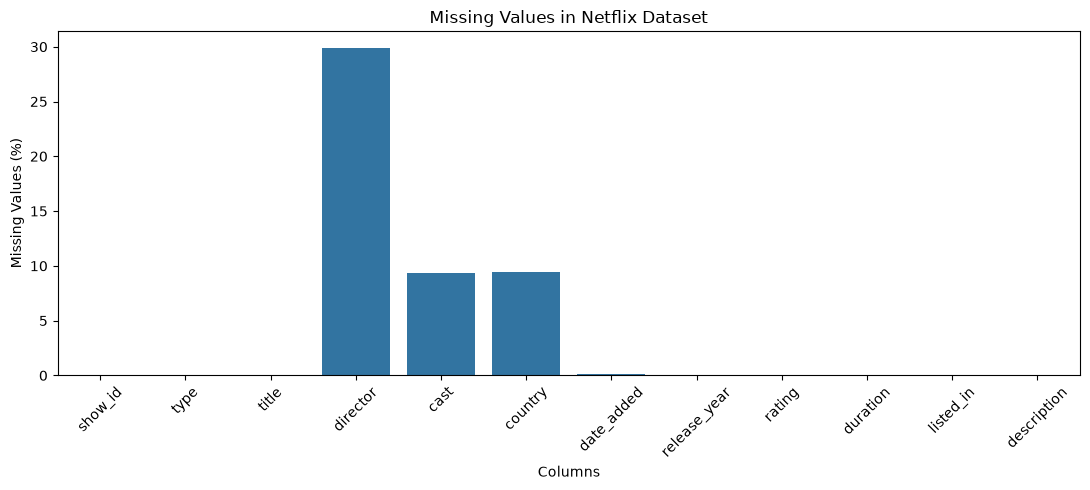

In [3]:
# Calculate missing values
missing_values = pd.DataFrame({
    "Missing Count": netflix_df.isnull().sum(),
    "Missing Percentage": (
        netflix_df.isnull().mean() * 100
    ).round(2)
})

display(missing_values)

# Plot missing-value percentages
plt.figure(figsize=(11, 5))

sns.barplot(
    x=missing_values.index,
    y=missing_values["Missing Percentage"]
)

plt.title("Missing Values in Netflix Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The dataset contains missing values in six columns.

The director column has the most missing values, with 2,634 records (29.91%). Country has 831 missing values (9.44%), while cast has 825 (9.37%).

The date_added column has 10 missing values, rating has 4, and duration has 3.

The remaining columns have no missing values.

The missing information in director, cast, and country may be related to how different titles were documented. However, the dataset does not provide enough information to confirm why these values are missing or whether they occurred randomly.

Removing all records containing missing values could result in losing useful information. For this reason, I will examine the importance of each column before deciding how to handle its missing values.


In [ ]:

### A2.2 Duplicate Records

I checked whether the dataset contains any repeated records.

Duplicate entries can affect the analysis because the same observation might be counted more than once.

I checked for completely identical rows, repeated show IDs, and repeated titles. The show_id column is especially important because it should uniquely identify each record.


In [4]:
print("Duplicate Rows:", netflix_df.duplicated().sum())

print(
    "Duplicate Show IDs:",
    netflix_df["show_id"].duplicated().sum()
)

print(
    "Duplicate Titles:",
    netflix_df["title"].duplicated().sum()
)

Duplicate Rows: 0
Duplicate Show IDs: 0
Duplicate Titles: 0


In [ ]:

### Interpretation

The duplicate checks found no repeated rows, show IDs, or titles.

This indicates that the dataset does not contain duplicate records according to these checks.

Since no duplicates were identified, I do not need to remove any records for duplication during data cleaning.


In [ ]:

### A2.3 Incorrect Data Types

I checked the data types to see whether each column is stored in a suitable format.

Some columns contain dates or numerical information but are initially stored as strings. These need to be identified before preprocessing.


In [5]:
print("Data Types:")
display(netflix_df.dtypes.to_frame("Data Type"))

print("\nDate Samples:")
display(netflix_df["date_added"].dropna().head())

print("\nMovie Duration Samples:")
display(
    netflix_df.loc[
        netflix_df["type"] == "Movie", "duration"
    ].dropna().head()
)

print("\nTV Show Duration Samples:")
display(
    netflix_df.loc[
        netflix_df["type"] == "TV Show", "duration"
    ].dropna().head()
)

Data Types:


,Data Type
show_id,str
type,str
title,str
director,str
cast,str
country,str
date_added,str
release_year,int64
rating,str
duration,str



Date Samples:


0    September 25, 2021
1    September 24, 2021
2    September 24, 2021
3    September 24, 2021
4    September 24, 2021
Name: date_added, dtype: str


Movie Duration Samples:


0      90 min
6      91 min
7     125 min
9     104 min
12    127 min
Name: duration, dtype: str


TV Show Duration Samples:


1    2 Seasons
2     1 Season
3     1 Season
4    2 Seasons
5     1 Season
Name: duration, dtype: str

In [ ]:

### Interpretation

The release_year column is already stored as an integer, which is suitable for numerical analysis.

However, date_added is stored as a string rather than a datetime value.

The duration column also contains text, with movie lengths recorded in minutes and TV show lengths recorded in seasons.

These two duration units cannot be directly compared.

During data cleaning, I will convert date_added into datetime format and extract separate numerical values for movie durations and TV show seasons.


In [ ]:

### A2.4 Categorical Consistency

I examined the categorical columns for possible inconsistencies, including extra spaces, differences in capitalization, and unusual labels.

I also checked whether some columns contain several values within a single entry.

This is important because inconsistent labels can cause the same category to be counted separately during analysis.


In [6]:
for column in ["type", "rating"]:
    print(f"\nCategories in {column}:")
    display(netflix_df[column].value_counts(dropna=False))

    values = netflix_df[column].dropna().astype(str)

    print(
        "Whitespace Issues:",
        (values != values.str.strip()).sum()
    )

    print(
        "Unique Categories Before Normalization:",
        values.nunique()
    )

    print(
        "Unique Categories After Normalization:",
        values.str.strip().str.casefold().nunique()
    )

# Check multi-valued attributes
for column in ["country", "cast", "listed_in"]:
    multiple = (
        netflix_df[column]
        .fillna("")
        .str.contains(",", regex=False)
        .sum()
    )

    print(f"{column} records with multiple values:", multiple)

# Inspect examples
display(
    netflix_df[
        ["country", "cast", "listed_in"]
    ].dropna().head()
)


Categories in type:


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Whitespace Issues: 0
Unique Categories Before Normalization: 2
Unique Categories After Normalization: 2

Categories in rating:


rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

Whitespace Issues: 0
Unique Categories Before Normalization: 17
Unique Categories After Normalization: 17
country records with multiple values: 1320
cast records with multiple values: 7101
listed_in records with multiple values: 6787


,country,cast,listed_in
1,South Africa,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...","International TV Shows, TV Dramas, TV Mysteries"
4,India,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...","International TV Shows, Romantic TV Shows, TV ..."
7,"United States, Ghana, Burkina Faso, United Kin...","Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","Dramas, Independent Movies, International Movies"
8,United Kingdom,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...","British TV Shows, Reality TV"
9,United States,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...","Comedies, Dramas"


In [ ]:

### Interpretation

The categorical consistency checks were used to examine capitalization, whitespace, and category labels.

The country, cast, and listed_in columns contain multiple values in some records.

These entries are not necessarily errors, but they require special handling. For example, a movie associated with two countries should be counted under each country rather than treating the complete string as a separate country.

The results of the whitespace and category normalization checks will determine whether any additional standardization is required.


In [ ]:

### A2.5 Suspicious and Invalid Values

I checked for values that appear unusual or have been entered in the wrong column.

The rating and duration attributes require particular attention because they contain different types of information.

I also checked the range of release years to identify potentially unrealistic values.


In [7]:
# Find ratings that look like movie durations
suspicious_ratings = netflix_df[
    netflix_df["rating"]
    .astype("string")
    .str.fullmatch(r"\d+\s*min", na=False)
]

print("Suspicious Rating Records:")
display(
    suspicious_ratings[
        ["show_id", "title", "rating", "duration"]
    ]
)

print("\nRecords with Missing Duration:")
display(
    netflix_df.loc[
        netflix_df["duration"].isna(),
        ["show_id", "title", "rating", "duration"]
    ]
)

print("\nRelease Year Range:")
print("Minimum:", netflix_df["release_year"].min())
print("Maximum:", netflix_df["release_year"].max())

print("\nUnexpected Content Types:")
display(netflix_df["type"].value_counts(dropna=False))

Suspicious Rating Records:


,show_id,title,rating,duration
5541,s5542,Louis C.K. 2017,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,66 min,NaN



Records with Missing Duration:


,show_id,title,rating,duration
5541,s5542,Louis C.K. 2017,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,66 min,NaN



Release Year Range:
Minimum: 1925
Maximum: 2021

Unexpected Content Types:


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [ ]:

### Interpretation

Three records have movie durations recorded in the rating column instead of the duration column.

The misplaced values are 74 minutes, 84 minutes, and 66 minutes.

These appear to be data-entry errors because the rating column should contain audience classifications rather than movie lengths.

The original release years range from 1925 to 2021. Although some titles are much older than others, an older release year does not automatically indicate an error.

The three misplaced duration values will be corrected during data cleaning. Their actual maturity ratings will remain unknown because the dataset does not provide enough information to determine them.


In [ ]:

### A2.6 Outlier Detection

I checked for outliers in movie durations to identify titles that are much shorter or longer than most movies in the dataset.

I used the Interquartile Range (IQR) method, which identifies values lying below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR.

Since movies are measured in minutes and TV shows are measured in seasons, I examined movie durations separately.

I also included the three misplaced duration values identified earlier so they would not be excluded from the analysis.

These values will only be flagged for investigation at this stage. They will not be removed automatically because an unusual duration does not necessarily mean the record is incorrect.


Q1: 87.0
Q3: 114.0
IQR: 27.0
Lower Bound: 46.5
Upper Bound: 154.5
Total Potential Outliers: 450

Longest Outlier Records:


,title,duration_minutes,release_year
4253,Black Mirror: Bandersnatch,312,2018
717,Headspace: Unwind Your Mind,273,2021
2491,The School of Mischief,253,1973
2487,No Longer kids,237,1979
2484,Lock Your Girls In,233,1982
2488,Raya and Sakina,230,1984
166,Once Upon a Time in America,229,1984
7932,Sangam,228,1964
1019,Lagaan,224,2001
4573,Jodhaa Akbar,214,2008


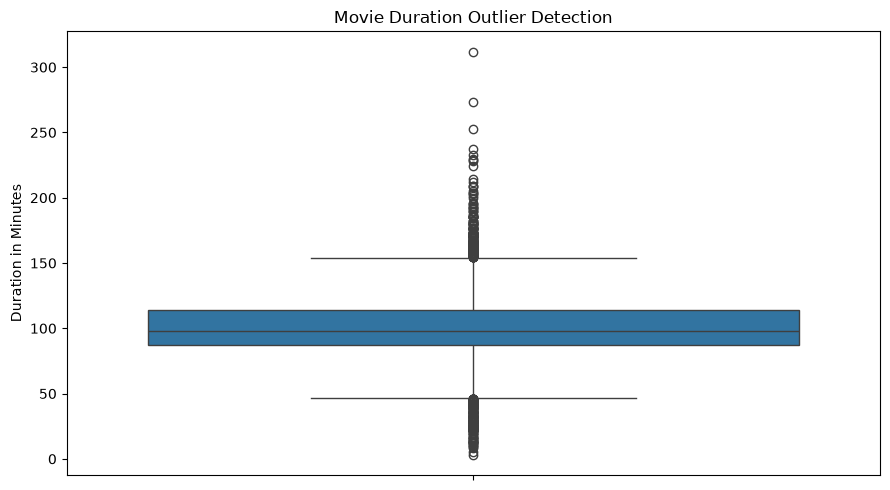

In [8]:
# Create a temporary copy of movie records
movie_quality = netflix_df[
    netflix_df["type"] == "Movie"
].copy()

# Correct misplaced durations in the temporary copy
mask = (
    movie_quality["duration"].isna()
    & movie_quality["rating"].astype("string")
      .str.fullmatch(r"\d+\s*min", na=False)
)

movie_quality.loc[mask, "duration"] = movie_quality.loc[
    mask, "rating"
]

# Extract numerical movie durations
movie_quality["duration_minutes"] = pd.to_numeric(
    movie_quality["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Calculate quartiles and IQR
Q1 = movie_quality["duration_minutes"].quantile(0.25)
Q3 = movie_quality["duration_minutes"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
movie_outliers = movie_quality[
    (movie_quality["duration_minutes"] < lower_bound)
    | (movie_quality["duration_minutes"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Potential Outliers:", len(movie_outliers))

print("\nLongest Outlier Records:")
display(
    movie_outliers[
        ["title", "duration_minutes", "release_year"]
    ].sort_values("duration_minutes", ascending=False).head(10)
)

# Visualization
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=movie_quality,
    y="duration_minutes"
)

plt.title("Movie Duration Outlier Detection")
plt.ylabel("Duration in Minutes")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The IQR method identified 450 potential outliers in movie durations.

The first quartile was 87 minutes and the third quartile was 114 minutes, giving an IQR of 27 minutes.

Based on these values, movie durations below 46.5 minutes or above 154.5 minutes were identified as potential outliers.

The longest recorded title was Black Mirror: Bandersnatch, with a listed duration of 312 minutes.

These unusual durations are not necessarily errors. Some titles may be short films, extended productions, or interactive content.

I decided not to remove these records because doing so could exclude valid titles and affect the overall duration distribution.


In [ ]:

## A3. Data Cleaning

After identifying the issues in the original dataset, I created a separate copy for cleaning.

This allows me to make changes without modifying the original data.

The main cleaning tasks include handling missing values, correcting misplaced durations, converting dates, and creating additional variables for analysis.

I chose to retain as many valid records as possible rather than removing rows simply because some information is missing.


In [9]:
# Create a copy of the original dataset

netflix_clean = netflix_df.copy()

print("Original Dataset:", netflix_df.shape)
print("Working Copy:", netflix_clean.shape)

Original Dataset: (8807, 12)
Working Copy: (8807, 12)


In [ ]:

### A3.1 Handling Missing Values

The director, cast, and country columns contain a considerable amount of missing information.

I replaced these missing values with Unknown so that the records could still be included in the analysis.

I also used Unknown for missing maturity ratings.

However, I decided to leave missing addition dates unchanged because assigning estimated dates could introduce incorrect information.

The missing duration values were handled separately because three records contained their actual durations in the rating column.


In [10]:
# Fill missing descriptive values with Unknown

columns_to_fill = [
    "director",
    "cast",
    "country",
    "rating"
]

for column in columns_to_fill:
    netflix_clean[column] = (
        netflix_clean[column].fillna("Unknown")
    )

print("Missing Values After Categorical Cleaning:")
display(netflix_clean.isnull().sum())

Missing Values After Categorical Cleaning:


show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64

In [ ]:

### A3.2 Correcting Misplaced Durations

During the data quality assessment, I found three movies where the duration was incorrectly stored in the rating column.

Since these values were clearly movie lengths, I transferred them to the duration column.

I replaced the corresponding rating values with Unknown because the actual maturity ratings were not available.

This correction preserves the duration information without making assumptions about missing ratings.


In [11]:
# Find records with misplaced duration values

mask = (
    netflix_clean["duration"].isna()
    & netflix_clean["rating"].str.fullmatch(
        r"\d+\s*min",
        na=False
    )
)

# Move duration values to the correct column
netflix_clean.loc[mask, "duration"] = (
    netflix_clean.loc[mask, "rating"]
)

# Replace invalid ratings
netflix_clean.loc[mask, "rating"] = "Unknown"

print("Corrected Records:", mask.sum())

display(
    netflix_clean.loc[
        mask,
        ["title", "rating", "duration"]
    ]
)

Corrected Records: 3


,title,rating,duration
5541,Louis C.K. 2017,Unknown,74 min
5794,Louis C.K.: Hilarious,Unknown,84 min
5813,Louis C.K.: Live at the Comedy Store,Unknown,66 min


In [ ]:

### A3.3 Date Conversion

The date_added column was originally stored as text.

I converted it into datetime format so that I could examine when titles were added to Netflix.

I also extracted the year and month into separate columns.

These new variables will make it easier to compare content additions across different years and months.

Records with missing dates were kept in the dataset, but they will be excluded from calculations that require a valid addition date.


In [12]:
# Convert date_added into datetime format

netflix_clean["date_added"] = pd.to_datetime(
    netflix_clean["date_added"].str.strip(),
    errors="coerce"
)

# Extract year and month
netflix_clean["year_added"] = (
    netflix_clean["date_added"].dt.year
)

netflix_clean["month_added"] = (
    netflix_clean["date_added"].dt.month
)

display(
    netflix_clean[
        ["title", "date_added", "year_added", "month_added"]
    ].head()
)

,title,date_added,year_added,month_added
0,Dick Johnson Is Dead,2021-09-25,2021.0,9.0
1,Blood & Water,2021-09-24,2021.0,9.0
2,Ganglands,2021-09-24,2021.0,9.0
3,Jailbirds New Orleans,2021-09-24,2021.0,9.0
4,Kota Factory,2021-09-24,2021.0,9.0


In [ ]:

### A3.4 Creating Numerical Duration Variables

The original duration column contains movie lengths in minutes and TV show lengths in seasons.

I extracted the numerical values and created separate columns for movie duration and TV show season counts.

This allows both types of content to be analyzed without mixing different measurement units.

I kept the original duration column as well so that the cleaned dataset still contains the source information.


In [13]:
# Extract numerical values from duration

netflix_clean["duration_value"] = pd.to_numeric(
    netflix_clean["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Store movie duration separately
netflix_clean["movie_minutes"] = (
    netflix_clean["duration_value"]
    .where(netflix_clean["type"] == "Movie")
)

# Store TV show season counts separately
netflix_clean["season_count"] = (
    netflix_clean["duration_value"]
    .where(netflix_clean["type"] == "TV Show")
)

display(
    netflix_clean[
        [
            "title",
            "type",
            "duration",
            "duration_value",
            "movie_minutes",
            "season_count"
        ]
    ].head(10)
)

,title,type,duration,duration_value,movie_minutes,season_count
0,Dick Johnson Is Dead,Movie,90 min,90,90.0,NaN
1,Blood & Water,TV Show,2 Seasons,2,NaN,2.0
2,Ganglands,TV Show,1 Season,1,NaN,1.0
3,Jailbirds New Orleans,TV Show,1 Season,1,NaN,1.0
4,Kota Factory,TV Show,2 Seasons,2,NaN,2.0
5,Midnight Mass,TV Show,1 Season,1,NaN,1.0
6,My Little Pony: A New Generation,Movie,91 min,91,91.0,NaN
7,Sankofa,Movie,125 min,125,125.0,NaN
8,The Great British Baking Show,TV Show,9 Seasons,9,NaN,9.0
9,The Starling,Movie,104 min,104,104.0,NaN


In [ ]:

### A3.5 Creating Additional Features

Some columns contain several values in a single cell, such as multiple production countries or content categories.

I created two additional variables to count how many countries and genres are associated with each title.

These features will be useful when exploring whether titles with multiple countries or genres show different patterns.

I kept the original country and listed_in columns unchanged so that their individual values can still be analyzed later.


In [14]:
# Function to count comma-separated values

def count_items(value):
    if pd.isna(value) or value == "Unknown":
        return 0

    return len([
        item.strip()
        for item in str(value).split(",")
        if item.strip()
    ])

# Count countries and genres
netflix_clean["num_countries"] = (
    netflix_clean["country"].apply(count_items)
)

netflix_clean["num_genres"] = (
    netflix_clean["listed_in"].apply(count_items)
)

display(
    netflix_clean[
        [
            "title",
            "country",
            "num_countries",
            "listed_in",
            "num_genres"
        ]
    ].head()
)

,title,country,num_countries,listed_in,num_genres
0,Dick Johnson Is Dead,United States,1,Documentaries,1
1,Blood & Water,South Africa,1,"International TV Shows, TV Dramas, TV Mysteries",3
2,Ganglands,Unknown,0,"Crime TV Shows, International TV Shows, TV Act...",3
3,Jailbirds New Orleans,Unknown,0,"Docuseries, Reality TV",2
4,Kota Factory,India,1,"International TV Shows, Romantic TV Shows, TV ...",3


In [15]:
# Function to count comma-separated values

def count_items(value):
    if pd.isna(value) or value == "Unknown":
        return 0

    return len([
        item.strip()
        for item in str(value).split(",")
        if item.strip()
    ])

# Count countries and genres
netflix_clean["num_countries"] = (
    netflix_clean["country"].apply(count_items)
)

netflix_clean["num_genres"] = (
    netflix_clean["listed_in"].apply(count_items)
)

display(
    netflix_clean[
        [
            "title",
            "country",
            "num_countries",
            "listed_in",
            "num_genres"
        ]
    ].head()
)

,title,country,num_countries,listed_in,num_genres
0,Dick Johnson Is Dead,United States,1,Documentaries,1
1,Blood & Water,South Africa,1,"International TV Shows, TV Dramas, TV Mysteries",3
2,Ganglands,Unknown,0,"Crime TV Shows, International TV Shows, TV Act...",3
3,Jailbirds New Orleans,Unknown,0,"Docuseries, Reality TV",2
4,Kota Factory,India,1,"International TV Shows, Romantic TV Shows, TV ...",3


In [ ]:

### A3.6 Release-to-Addition Gap

I created a variable called addition_gap to calculate the difference between a title's original release year and the year it was added to Netflix.

This will help me understand whether the dataset contains mainly recently released titles or older titles added much later.

A missing addition date will result in a missing gap value, which will be excluded from analyses that require this information.


In [16]:
# Calculate years between release and Netflix addition

netflix_clean["addition_gap"] = (
    netflix_clean["year_added"]
    - netflix_clean["release_year"]
)

display(
    netflix_clean[
        [
            "title",
            "release_year",
            "year_added",
            "addition_gap"
        ]
    ].head(10)
)

print(
    "Missing Addition Gap Values:",
    netflix_clean["addition_gap"].isna().sum()
)

,title,release_year,year_added,addition_gap
0,Dick Johnson Is Dead,2020,2021.0,1.0
1,Blood & Water,2021,2021.0,0.0
2,Ganglands,2021,2021.0,0.0
3,Jailbirds New Orleans,2021,2021.0,0.0
4,Kota Factory,2021,2021.0,0.0
5,Midnight Mass,2021,2021.0,0.0
6,My Little Pony: A New Generation,2021,2021.0,0.0
7,Sankofa,1993,2021.0,28.0
8,The Great British Baking Show,2021,2021.0,0.0
9,The Starling,2021,2021.0,0.0


Missing Addition Gap Values: 10


In [ ]:

### A3.7 Cleaning Decisions and Justifications

The following table summarizes the problems identified during the data quality assessment and explains how I handled them.

Each decision was made based on the nature of the variable and its importance for later analysis.

The aim was to improve the dataset while avoiding unnecessary deletion or modification of valid observations.


In [17]:
cleaning_decisions = [
    [
        "Missing director, cast and country",
        "Missing-value counts",
        "Replaced missing values with Unknown",
        "Preserves titles without inventing information"
    ],
    [
        "Missing maturity ratings",
        "Rating null-value inspection",
        "Replaced missing ratings with Unknown",
        "Actual rating information was unavailable"
    ],
    [
        "Missing addition dates",
        "10 records had no date_added",
        "Left dates missing",
        "Estimated dates could introduce false information"
    ],
    [
        "Misplaced movie durations",
        "Three duration values found in rating",
        "Transferred values into duration",
        "Corrects identifiable data-entry mistakes"
    ],
    [
        "Incorrect date data type",
        "date_added stored as string",
        "Converted to datetime",
        "Enables time-based analysis"
    ],
    [
        "Mixed duration measurements",
        "Minutes and seasons in one column",
        "Created separate numerical variables",
        "Prevents comparisons between different units"
    ],
    [
        "Multiple countries and genres",
        "Comma-separated entries",
        "Created count features",
        "Supports analysis of multi-valued attributes"
    ],
    [
        "Unusual movie durations",
        "450 outliers flagged using IQR",
        "Retained all observations",
        "Extreme durations may still be valid"
    ]
]

cleaning_table = pd.DataFrame(
    cleaning_decisions,
    columns=[
        "Problem",
        "Detection",
        "Decision",
        "Justification"
    ]
)

display(cleaning_table)

,Problem,Detection,Decision,Justification
0,"Missing director, cast and country",Missing-value counts,Replaced missing values with Unknown,Preserves titles without inventing information
1,Missing maturity ratings,Rating null-value inspection,Replaced missing ratings with Unknown,Actual rating information was unavailable
2,Missing addition dates,10 records had no date_added,Left dates missing,Estimated dates could introduce false information
3,Misplaced movie durations,Three duration values found in rating,Transferred values into duration,Corrects identifiable data-entry mistakes
4,Incorrect date data type,date_added stored as string,Converted to datetime,Enables time-based analysis
5,Mixed duration measurements,Minutes and seasons in one column,Created separate numerical variables,Prevents comparisons between different units
6,Multiple countries and genres,Comma-separated entries,Created count features,Supports analysis of multi-valued attributes
7,Unusual movie durations,450 outliers flagged using IQR,Retained all observations,Extreme durations may still be valid


In [18]:
cleaning_decisions = [
    [
        "Missing director, cast and country",
        "Missing-value counts",
        "Replaced missing values with Unknown",
        "Preserves titles without inventing information"
    ],
    [
        "Missing maturity ratings",
        "Rating null-value inspection",
        "Replaced missing ratings with Unknown",
        "Actual rating information was unavailable"
    ],
    [
        "Missing addition dates",
        "10 records had no date_added",
        "Left dates missing",
        "Estimated dates could introduce false information"
    ],
    [
        "Misplaced movie durations",
        "Three duration values found in rating",
        "Transferred values into duration",
        "Corrects identifiable data-entry mistakes"
    ],
    [
        "Incorrect date data type",
        "date_added stored as string",
        "Converted to datetime",
        "Enables time-based analysis"
    ],
    [
        "Mixed duration measurements",
        "Minutes and seasons in one column",
        "Created separate numerical variables",
        "Prevents comparisons between different units"
    ],
    [
        "Multiple countries and genres",
        "Comma-separated entries",
        "Created count features",
        "Supports analysis of multi-valued attributes"
    ],
    [
        "Unusual movie durations",
        "450 outliers flagged using IQR",
        "Retained all observations",
        "Extreme durations may still be valid"
    ]
]

cleaning_table = pd.DataFrame(
    cleaning_decisions,
    columns=[
        "Problem",
        "Detection",
        "Decision",
        "Justification"
    ]
)

display(cleaning_table)

,Problem,Detection,Decision,Justification
0,"Missing director, cast and country",Missing-value counts,Replaced missing values with Unknown,Preserves titles without inventing information
1,Missing maturity ratings,Rating null-value inspection,Replaced missing ratings with Unknown,Actual rating information was unavailable
2,Missing addition dates,10 records had no date_added,Left dates missing,Estimated dates could introduce false information
3,Misplaced movie durations,Three duration values found in rating,Transferred values into duration,Corrects identifiable data-entry mistakes
4,Incorrect date data type,date_added stored as string,Converted to datetime,Enables time-based analysis
5,Mixed duration measurements,Minutes and seasons in one column,Created separate numerical variables,Prevents comparisons between different units
6,Multiple countries and genres,Comma-separated entries,Created count features,Supports analysis of multi-valued attributes
7,Unusual movie durations,450 outliers flagged using IQR,Retained all observations,Extreme durations may still be valid


In [19]:
# Verify the cleaned dataset

print("Original Shape:", netflix_df.shape)
print("Cleaned Shape:", netflix_clean.shape)

print("\nRemaining Missing Values:")
display(netflix_clean.isnull().sum())

print("\nDuplicate Rows:")
print(netflix_clean.duplicated().sum())

print("\nCorrected Duration Records:")
print(mask.sum())

print("\nMovie Duration Statistics:")
display(
    netflix_clean.loc[
        netflix_clean["type"] == "Movie",
        "movie_minutes"
    ].describe()
)

# Save cleaned dataset for Assignment 3
netflix_clean.to_csv(
    "23L_0977_A2_netflix_cleaned.csv",
    index=False
)

print("\nCleaned Netflix CSV exported successfully.")

Original Shape: (8807, 12)
Cleaned Shape: (8807, 20)

Remaining Missing Values:


show_id              0
type                 0
title                0
director             0
cast                 0
country              0
date_added          10
release_year         0
rating               0
duration             0
listed_in            0
description          0
year_added          10
month_added         10
duration_value       0
movie_minutes     2676
season_count      6131
num_countries        0
num_genres           0
addition_gap        10
dtype: int64


Duplicate Rows:
0

Corrected Duration Records:
3

Movie Duration Statistics:


count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: movie_minutes, dtype: float64


Cleaned Netflix CSV exported successfully.


In [ ]:

### A3.8 Cleaning Summary

The original Netflix dataset contained 8,807 records and 12 columns.

I handled missing categorical information by replacing unavailable values with Unknown. Missing addition dates were left unchanged because there was no reliable way to determine the correct dates.

Three misplaced movie durations were corrected, and date_added was converted into datetime format.

I also created additional variables for movie durations, TV show seasons, number of countries, number of genres, and the gap between release and Netflix addition.

No records were removed during cleaning. Unusual movie durations were retained because the outlier checks did not establish that they were incorrect.

The cleaned dataset is now ready for exploratory analysis, and a copy has been exported for use in Assignment 3.


In [ ]:

## A4. Univariate Exploratory Data Analysis

In this section, I analyzed individual variables to understand how the values are distributed across the Netflix dataset.

For categorical variables, I used frequency tables and count plots to compare different categories.

For numerical variables, I calculated descriptive statistics such as the mean, median, standard deviation, quartiles, and skewness.

I also used histograms and box plots to understand the shape of numerical distributions and identify unusual observations.


In [ ]:

### A4.1 Distribution of Content Types

I first examined the number of movies and TV shows in the dataset.

Since type is a categorical variable, I used a frequency table and a bar chart to compare the two categories. I also calculated their percentages to understand their relative proportions.


,Count,Percentage
type,,
Movie,6131,69.62
TV Show,2676,30.38


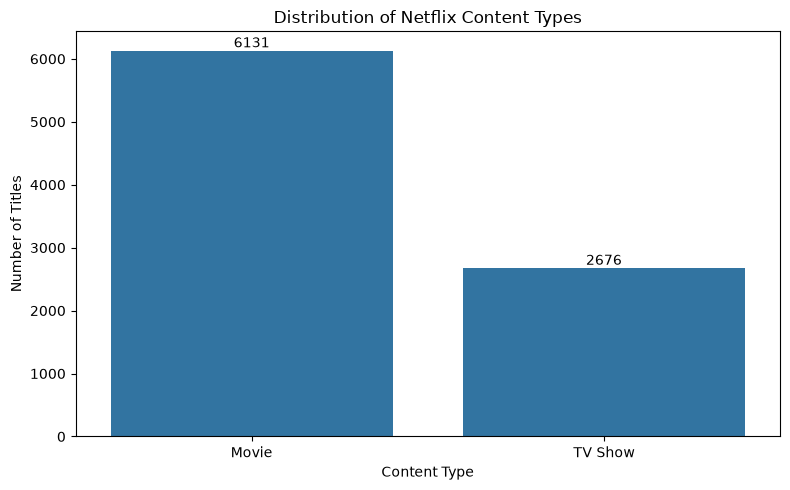

In [20]:
# Count movies and TV shows
content_counts = netflix_clean["type"].value_counts()

content_percentages = (
    netflix_clean["type"].value_counts(normalize=True) * 100
).round(2)

content_summary = pd.DataFrame({
    "Count": content_counts,
    "Percentage": content_percentages
})

display(content_summary)

# Visualize content distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=netflix_clean,
    x="type",
    order=content_counts.index
)

plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The dataset contains 6,131 movies and 2,676 TV shows.

Movies account for approximately 69.61% of the titles, while TV shows represent 30.39%.

This shows that movies make up a considerably larger portion of the dataset.

A bar chart was used because it makes the difference between the two categorical groups easy to compare.

These percentages describe the available dataset and should not be assumed to represent Netflix's current catalogue.


In [ ]:

### A4.2 Distribution of Release Years

Next, I examined the years in which the Netflix titles were originally released.

I used descriptive statistics to understand the central tendency and spread of release years.

A histogram was used to show how titles are distributed over time, while a box plot was used to identify older releases that appear unusual compared with the majority of titles.


Release Year Statistics:


count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

Median Release Year: 2017.0
Release Year Skewness: -3.447

Most Common Release Years:


release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64

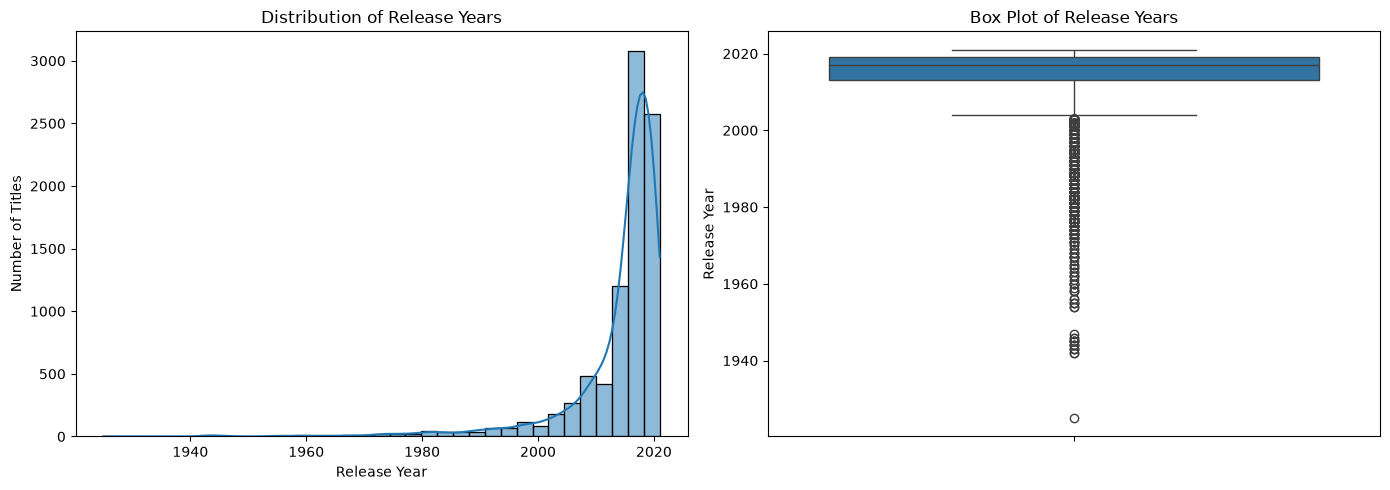

In [21]:
# Calculate release year statistics

release_stats = netflix_clean["release_year"].describe()

print("Release Year Statistics:")
display(release_stats)

print(
    "Median Release Year:",
    netflix_clean["release_year"].median()
)

print(
    "Release Year Skewness:",
    round(netflix_clean["release_year"].skew(), 3)
)

print("\nMost Common Release Years:")
display(
    netflix_clean["release_year"]
    .value_counts()
    .head(10)
)

# Plot histogram and box plot

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=netflix_clean,
    x="release_year",
    bins=35,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Release Years")
axes[0].set_xlabel("Release Year")
axes[0].set_ylabel("Number of Titles")

sns.boxplot(
    data=netflix_clean,
    y="release_year",
    ax=axes[1]
)

axes[1].set_title("Box Plot of Release Years")
axes[1].set_ylabel("Release Year")

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The release years in the dataset range from 1925 to 2021.

The highest number of titles was released in 2018, with 1,147 titles. This was followed by 2017 with 1,032 titles and 2019 with 1,030 titles.

The histogram shows that most titles were released in relatively recent years, while much older titles are less common.

This creates a longer tail toward earlier release years, indicating a negatively skewed distribution.

The box plot also highlights older releases that are far from the majority of observations. However, these are not necessarily errors because Netflix may include older movies and television content.

The older records have therefore been retained.


In [ ]:

### A4.3 Distribution of Maturity Ratings

I examined the rating column to identify which audience classifications appear most frequently.

Since ratings are categorical values, I used a frequency table and a bar chart.

The Unknown category was kept separate because the actual ratings of some titles were unavailable.


,Count,Percentage
rating,,
TV-MA,3207,36.41
TV-14,2160,24.53
TV-PG,863,9.80
R,799,9.07
PG-13,490,5.56
TV-Y7,334,3.79
TV-Y,307,3.49
PG,287,3.26
TV-G,220,2.50


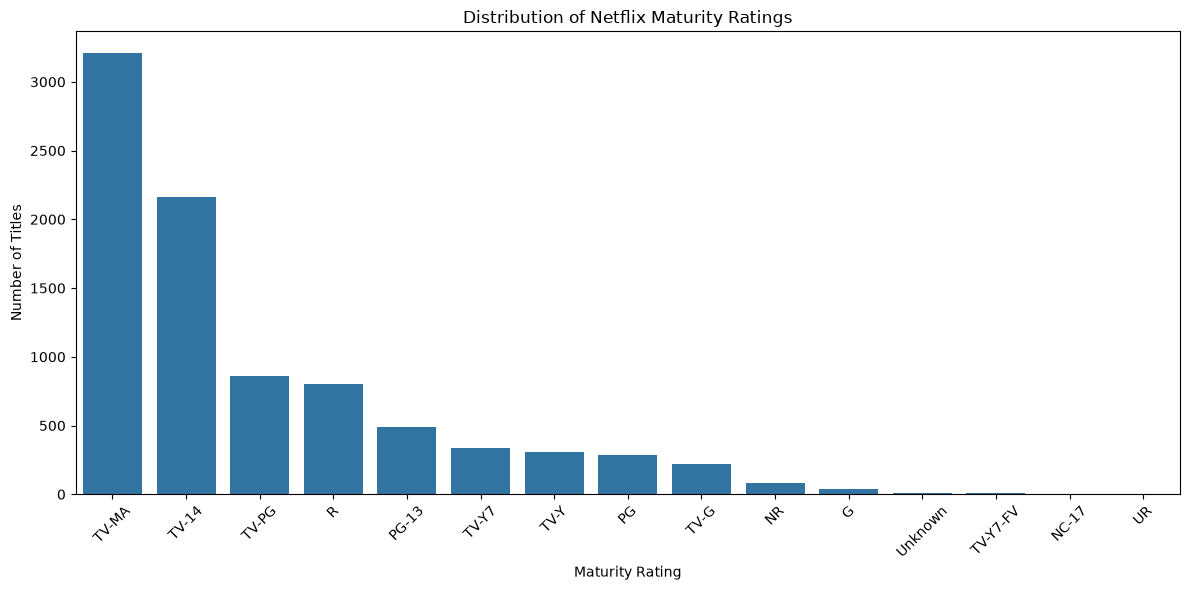

In [22]:
# Calculate rating frequencies

rating_counts = netflix_clean["rating"].value_counts()

rating_summary = pd.DataFrame({
    "Count": rating_counts,
    "Percentage": (
        rating_counts / len(netflix_clean) * 100
    ).round(2)
})

display(rating_summary)

# Plot rating distribution

plt.figure(figsize=(12, 6))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of Netflix Maturity Ratings")
plt.xlabel("Maturity Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

TV-MA is the most common rating in the dataset, appearing in 3,207 titles.

TV-14 is the second most common rating, with 2,160 titles, followed by TV-PG with 863 titles.

This indicates that a large portion of the dataset is classified under ratings commonly associated with mature or teenage audiences.

Ratings such as G and NC-17 appear much less frequently.

A bar chart is suitable for this analysis because ratings are categorical and their frequencies can be compared directly.

The Unknown category represents records where reliable rating information was not available.


In [ ]:

### A4.4 Movie Duration Analysis

I examined movie durations separately from TV show season counts because the two variables use different units.

For movies, duration is measured in minutes.

I calculated the mean, median, standard deviation, quartiles, and skewness to understand the distribution.

I used a histogram to examine the overall shape and a box plot to identify unusually short or long movies.


Movie Duration Statistics:


count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: movie_minutes, dtype: float64

Movie Duration Skewness: 0.203


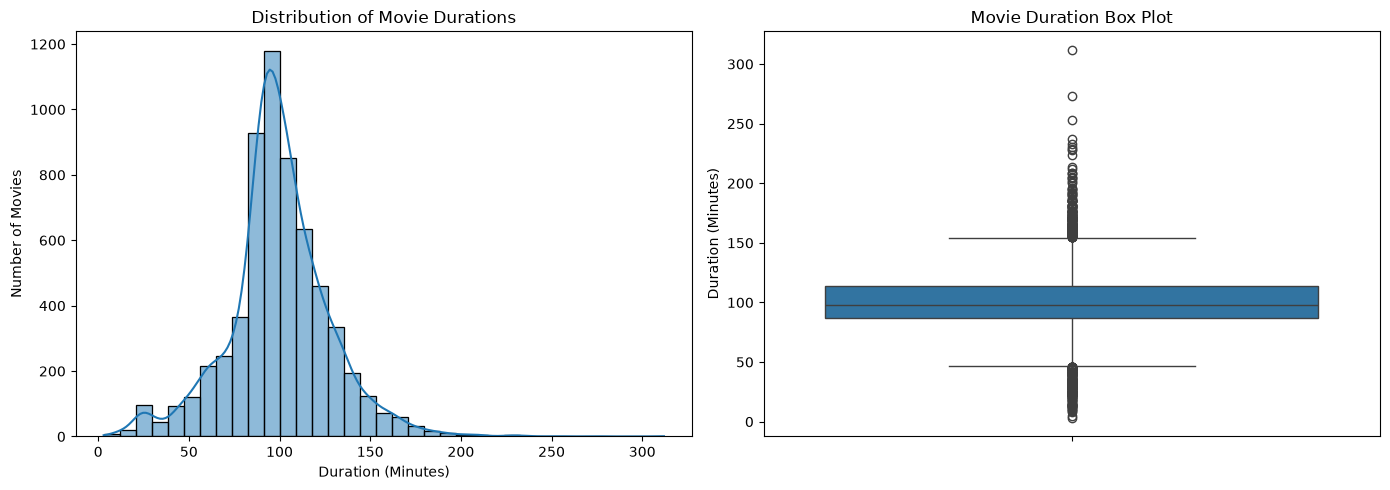

In [23]:
# Select movies only
movies = netflix_clean[
    netflix_clean["type"] == "Movie"
].copy()

# Descriptive statistics
print("Movie Duration Statistics:")
display(movies["movie_minutes"].describe())

print(
    "Movie Duration Skewness:",
    round(movies["movie_minutes"].skew(), 3)
)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=movies,
    x="movie_minutes",
    bins=35,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Movie Durations")
axes[0].set_xlabel("Duration (Minutes)")
axes[0].set_ylabel("Number of Movies")

sns.boxplot(
    data=movies,
    y="movie_minutes",
    ax=axes[1]
)

axes[1].set_title("Movie Duration Box Plot")
axes[1].set_ylabel("Duration (Minutes)")

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The dataset contains 6,131 movies with an average duration of approximately 99.56 minutes.

The median duration is 98 minutes, which is close to the mean.

The first quartile is 87 minutes, while the third quartile is 114 minutes. This means the middle 50% of movie durations fall between these values.

The shortest recorded movie duration is 3 minutes, while the longest is 312 minutes.

The histogram shows that many movies are concentrated around the typical feature-film length, although there are also unusually short and long titles.

The box plot highlights these extreme durations. The IQR method previously identified 450 potential outliers.

I retained these observations because unusually long or short durations can still represent valid content.


In [ ]:

### A4.5 TV Show Season Analysis

For TV shows, duration is recorded as the number of seasons rather than minutes.

I examined the number of seasons using descriptive statistics and a count plot.

This helps identify whether the dataset contains mostly short series or shows that have continued for several seasons.


TV Show Season Statistics:


count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: season_count, dtype: float64

TV Show Season Skewness: 3.419


,Number of Shows
season_count,
1.0,1793
2.0,425
3.0,199
4.0,95
5.0,65
6.0,33
7.0,23
8.0,17
9.0,9


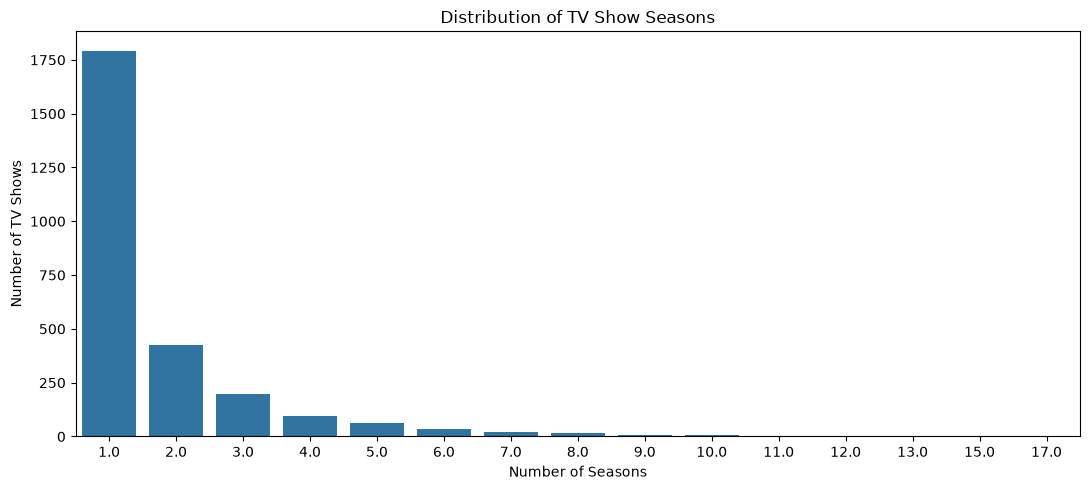

In [24]:
# Select TV shows
tv_shows = netflix_clean[
    netflix_clean["type"] == "TV Show"
].copy()

# Descriptive statistics
print("TV Show Season Statistics:")
display(tv_shows["season_count"].describe())

print(
    "TV Show Season Skewness:",
    round(tv_shows["season_count"].skew(), 3)
)

# Season frequencies
season_counts = (
    tv_shows["season_count"]
    .value_counts()
    .sort_index()
)

display(season_counts.to_frame("Number of Shows"))

# Count plot
plt.figure(figsize=(11, 5))

sns.countplot(
    data=tv_shows,
    x="season_count"
)

plt.title("Distribution of TV Show Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The dataset contains 2,676 TV shows.

The average number of seasons is approximately 1.76, while the median is one season.

The first quartile is one season and the third quartile is two seasons.

The maximum recorded number of seasons is 17.

These results show that most TV shows in the dataset have relatively few seasons, particularly one or two.

The distribution has a longer tail toward shows with more seasons, indicating positive skewness.

Shows with many seasons were retained because a high season count is not necessarily a data-quality problem.


In [ ]:

### A4.6 Number of Countries and Genres per Title

Some Netflix titles are associated with multiple production countries or content categories.

I used the derived num_countries and num_genres variables to examine how many countries and categories are associated with each title.

Count plots are suitable here because both variables contain small discrete numerical values.

These features help summarize multi-valued information without treating complete comma-separated strings as individual categories.


Number of Countries Statistics:


count    8807.000000
mean        1.136823
std         0.758338
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        12.000000
Name: num_countries, dtype: float64


Number of Genres Statistics:


count    8807.000000
mean        2.194050
std         0.784341
min         1.000000
25%         2.000000
50%         2.000000
75%         3.000000
max         3.000000
Name: num_genres, dtype: float64


Country Count Skewness: 2.89
Genre Count Skewness: -0.355


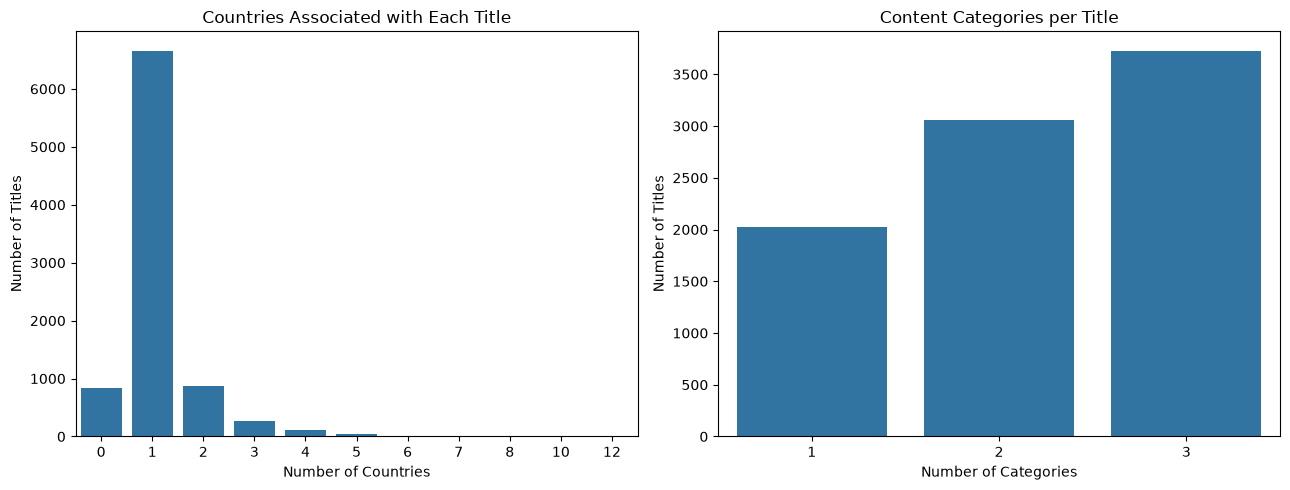

In [25]:
# Descriptive statistics

print("Number of Countries Statistics:")
display(netflix_clean["num_countries"].describe())

print("\nNumber of Genres Statistics:")
display(netflix_clean["num_genres"].describe())

print(
    "\nCountry Count Skewness:",
    round(netflix_clean["num_countries"].skew(), 3)
)

print(
    "Genre Count Skewness:",
    round(netflix_clean["num_genres"].skew(), 3)
)

# Visualizations

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=netflix_clean,
    x="num_countries",
    ax=axes[0]
)

axes[0].set_title("Countries Associated with Each Title")
axes[0].set_xlabel("Number of Countries")
axes[0].set_ylabel("Number of Titles")

sns.countplot(
    data=netflix_clean,
    x="num_genres",
    ax=axes[1]
)

axes[1].set_title("Content Categories per Title")
axes[1].set_xlabel("Number of Categories")
axes[1].set_ylabel("Number of Titles")

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The country and genre count variables show how multi-valued information is distributed across Netflix titles.

A value of zero in num_countries indicates that the country information was missing in the original dataset and was recorded as Unknown during cleaning.

The plots help distinguish titles associated with a single country or category from those linked to multiple countries or categories.

The descriptive statistics and skewness values can be used to determine whether the distributions are concentrated around smaller counts or contain longer tails.

These derived variables may also be useful in later bivariate and multivariate analyses.


In [ ]:

## A5. Bivariate Exploratory Data Analysis

In this section, I examined relationships between pairs of variables to understand how different characteristics of Netflix content are connected.

Unlike univariate analysis, which focuses on individual variables, bivariate analysis allows me to compare two variables and look for possible patterns.

I selected three types of relationships: numerical with numerical, numerical with categorical, and categorical with categorical.

I used correlation analysis, box plots, and grouped bar charts depending on the type of variables being compared.

The goal is to identify meaningful relationships without assuming that one variable directly causes changes in another.


In [ ]:

### A5.1 Relationship Between Release Year and Year Added

I wanted to see whether recently released titles were generally added to Netflix in more recent years.

For this analysis, I selected release_year and year_added because both variables represent years.

I used a scatter plot to visualize the relationship and Pearson's correlation coefficient to measure the strength and direction of their linear association.

Records with missing addition dates were excluded because they cannot be used in this comparison.


Correlation Matrix:


,release_year,year_added
release_year,1.000,0.112
year_added,0.112,1.000



Pearson Correlation: 0.1115


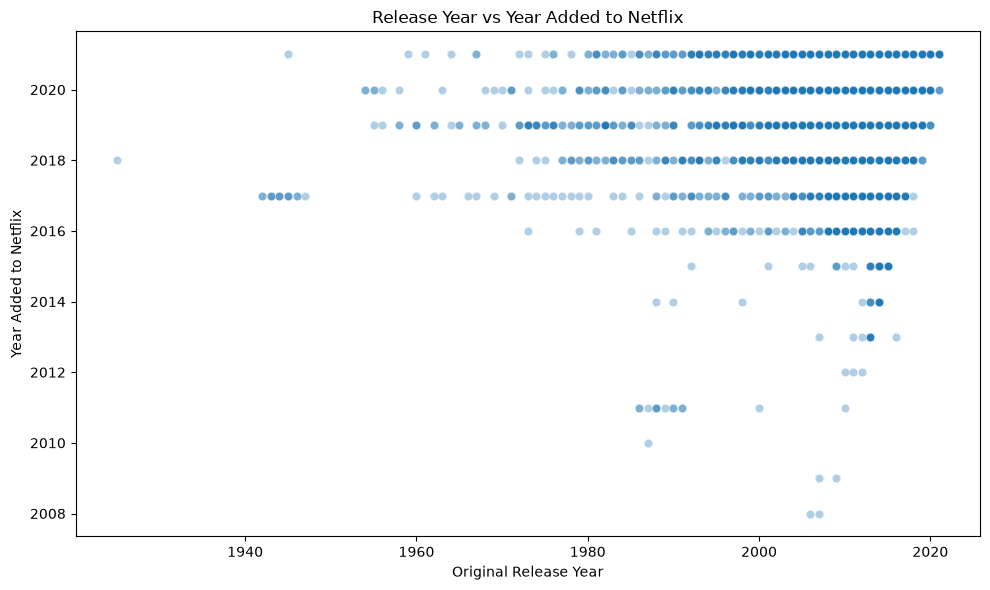

In [26]:
# Select records with valid years
year_data = netflix_clean.dropna(
    subset=["release_year", "year_added"]
).copy()

# Calculate Pearson correlation
pearson_corr = year_data[
    ["release_year", "year_added"]
].corr(method="pearson")

print("Correlation Matrix:")
display(pearson_corr.round(3))

print(
    "\nPearson Correlation:",
    round(
        year_data["release_year"].corr(
            year_data["year_added"]
        ),
        4
    )
)

# Scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=year_data,
    x="release_year",
    y="year_added",
    alpha=0.35
)

plt.title("Release Year vs Year Added to Netflix")
plt.xlabel("Original Release Year")
plt.ylabel("Year Added to Netflix")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The scatter plot compares the original release years of titles with the years in which they were added to Netflix.

The points show that titles from different release periods were added to the platform during the years covered by the dataset.

Many titles were originally released before the year they appeared on Netflix, showing that the catalogue contains both recently released and older content.

Pearson's correlation coefficient helps measure whether newer releases tend to have later addition dates.

A positive coefficient would indicate that more recently released titles are generally associated with later addition years, while a coefficient near zero would indicate a weak linear relationship.

However, the relationship should not be interpreted as evidence that release year directly determines when content is added to Netflix.


In [ ]:

### A5.2 Release Year by Content Type

For this comparison, I examined release_year as the numerical variable and type as the categorical variable.

I wanted to understand whether movies and TV shows in the dataset belong to similar release periods or whether one category contains relatively newer titles.

I calculated summary statistics for each content type and used a box plot to compare their distributions.

A box plot is suitable because it shows the median, quartiles, spread, and potential outliers for each group.


Release Year Statistics by Content Type:


,count,mean,median,std,min,max
type,,,,,,
Movie,6131,2013.12,2016.0,9.68,1942,2021
TV Show,2676,2016.61,2018.0,5.74,1925,2021


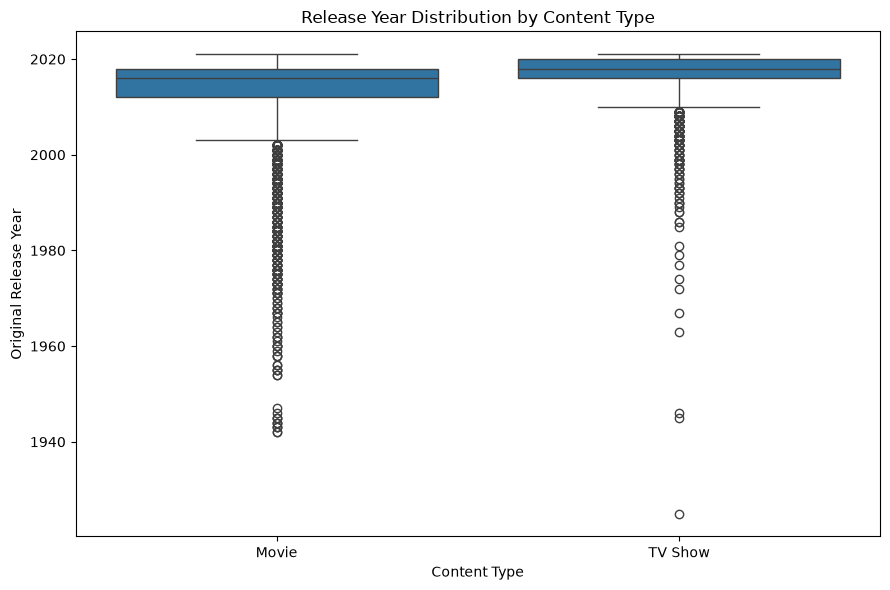

In [27]:
# Calculate release year statistics by content type

release_type_summary = (
    netflix_clean.groupby("type")["release_year"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

print("Release Year Statistics by Content Type:")
display(release_type_summary)

# Box plot
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=netflix_clean,
    x="type",
    y="release_year"
)

plt.title("Release Year Distribution by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Original Release Year")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The box plot allows me to compare release years for movies and TV shows.

The median and mean release years indicate which category contains relatively newer content.

The spread of each distribution also shows whether one type includes titles from a wider range of release years.

Older observations appearing outside the whiskers are potential outliers according to the box plot's IQR-based rule. However, these observations may represent valid older productions.

This comparison is useful because movies and TV shows may have different release-year patterns even though they are included in the same Netflix catalogue.


In [ ]:

### A5.3 Relationship Between Content Type and Maturity Rating

I examined the relationship between type and rating to understand whether movies and TV shows have different rating distributions.

Both variables are categorical, so I used a contingency table to compare the number of titles in each combination.

I also calculated percentages within each content type to make the comparison fair, since the dataset contains more movies than TV shows.

A grouped bar chart and a heatmap were used to visualize these differences.


Rating Counts by Content Type:


type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,733
TV-G,126,94
TV-MA,2062,1145



Rating Percentages by Content Type:


type,Movie,TV Show
rating,,
G,0.67,0.00
NC-17,0.05,0.00
NR,1.22,0.19
PG,4.68,0.00
PG-13,7.99,0.00
R,13.00,0.07
TV-14,23.28,27.39
TV-G,2.06,3.51
TV-MA,33.63,42.79


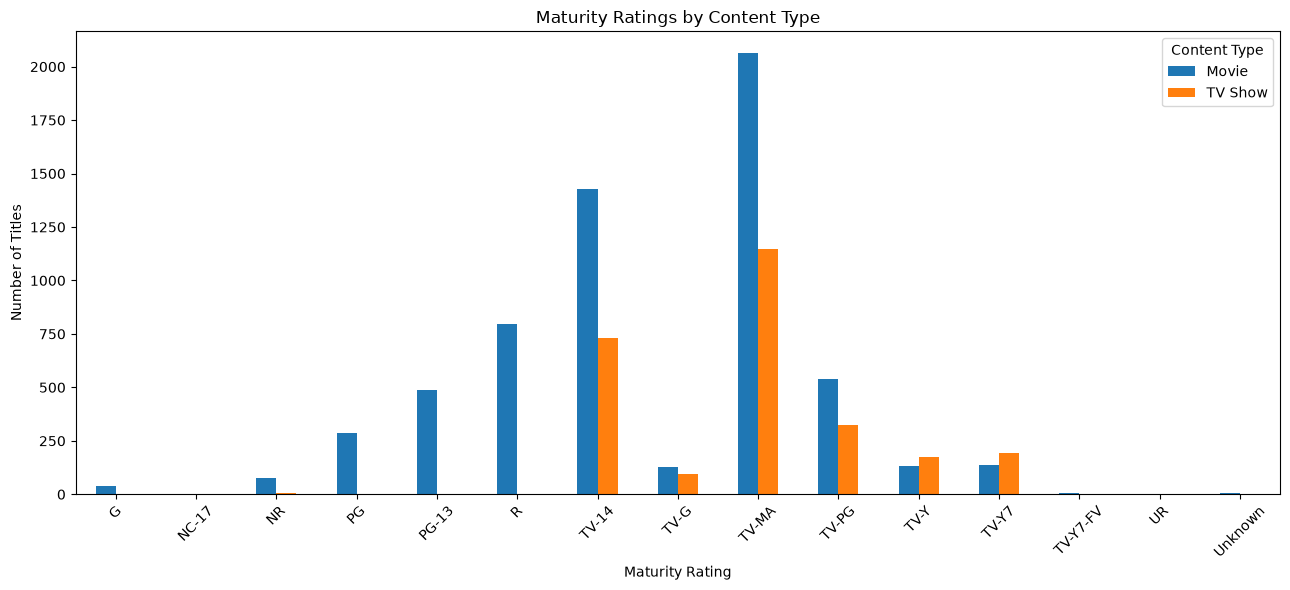

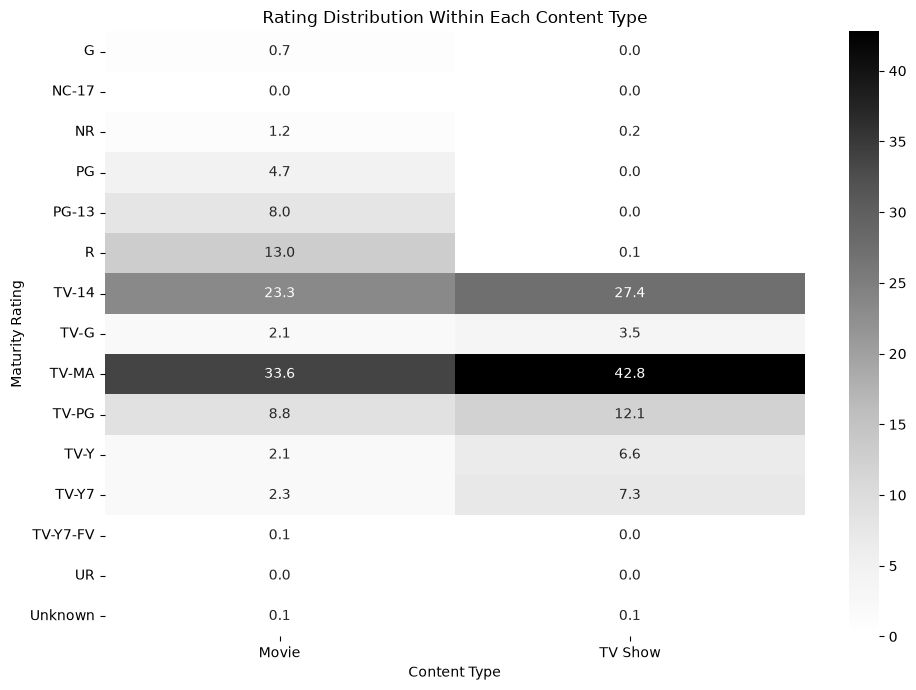

In [28]:
# Create contingency table
rating_type_table = pd.crosstab(
    netflix_clean["rating"],
    netflix_clean["type"]
)

print("Rating Counts by Content Type:")
display(rating_type_table)

# Calculate percentages within each content type
rating_type_percentage = pd.crosstab(
    netflix_clean["rating"],
    netflix_clean["type"],
    normalize="columns"
) * 100

print("\nRating Percentages by Content Type:")
display(rating_type_percentage.round(2))

# Grouped bar chart
rating_type_table.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Maturity Ratings by Content Type")
plt.xlabel("Maturity Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

# Heatmap of percentages
plt.figure(figsize=(10, 7))

sns.heatmap(
    rating_type_percentage,
    annot=True,
    fmt=".1f",
    cmap="Greys"
)

plt.title("Rating Distribution Within Each Content Type")
plt.xlabel("Content Type")
plt.ylabel("Maturity Rating")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The rating distribution differs between movies and TV shows.

TV-MA is the most common rating in both categories, appearing in 2,062 movies and 1,145 TV shows.

TV-14 is also common, with 1,427 movies and 733 TV shows.

Some ratings are mainly associated with movies. For example, PG-13 appears in 490 movies and no TV shows, while PG appears in 287 movies and no TV shows.

Similarly, TV-Y and TV-Y7 are more frequently represented among TV shows than movies.

The percentage heatmap helps account for the difference in the total number of movies and TV shows.

These results show that maturity rating distributions vary across content types. However, part of this difference is related to the rating classification systems used for movies and television programmes.


In [ ]:

### A5.4 Release-to-Addition Gap by Content Type

I also examined whether movies and TV shows differ in the time between their original release and their addition to Netflix.

The addition_gap variable was created during data cleaning by subtracting release_year from year_added.

I compared the mean and median gaps for movies and TV shows and used a box plot to examine their distributions.

This analysis helps identify whether one content type generally consists of older titles when added to Netflix.


Release-to-Addition Gap by Content Type:


,count,mean,median,std,min,max
type,,,,,,
Movie,6131,5.73,2.0,9.74,-1.0,75.0
TV Show,2666,2.30,0.0,5.32,-3.0,93.0



Negative Addition Gaps: 14


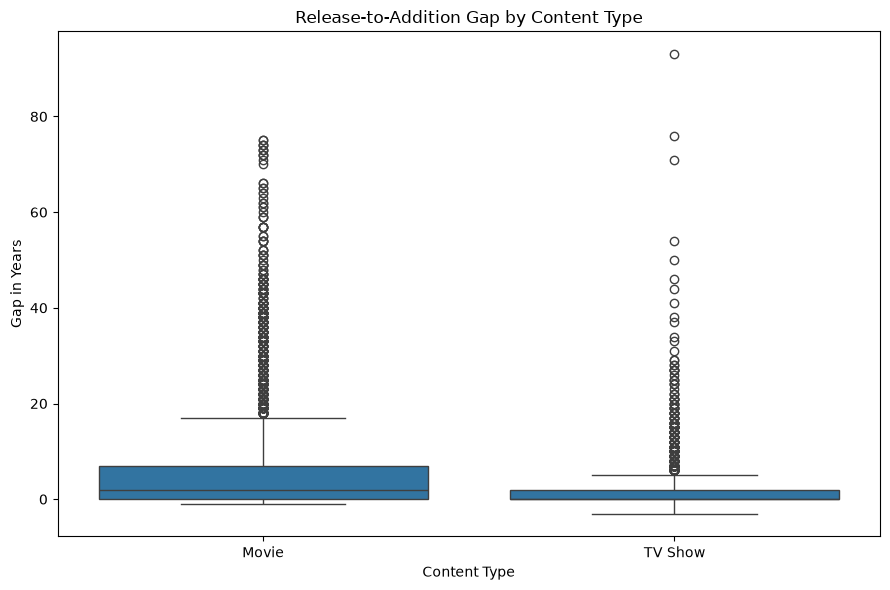

In [29]:
# Select records with valid addition gaps
gap_data = netflix_clean.dropna(
    subset=["addition_gap"]
).copy()

# Summary statistics by content type
gap_summary = (
    gap_data.groupby("type")["addition_gap"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

print("Release-to-Addition Gap by Content Type:")
display(gap_summary)

print(
    "\nNegative Addition Gaps:",
    (gap_data["addition_gap"] < 0).sum()
)

# Box plot
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=gap_data,
    x="type",
    y="addition_gap"
)

plt.title("Release-to-Addition Gap by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Gap in Years")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The addition_gap variable measures the number of calendar years between a title's original release and its addition to Netflix.

Comparing the mean and median gaps for movies and TV shows helps determine whether one category generally contains older content.

A larger average gap would indicate that titles in that category were typically added longer after their original release.

The box plot also helps identify titles with unusually large gaps.

A value of zero means that the release and addition occurred in the same calendar year. A negative value would require further investigation because it could indicate an unusual record or a data-quality issue.

The results describe differences in the available catalogue but do not explain Netflix's licensing or content acquisition decisions.


In [ ]:

## A6. Multivariate Exploratory Data Analysis

In this section, I looked at how three or more variables are related to each other.

In the previous section, I compared two variables at a time. Here, I wanted to see whether the patterns changed when another variable was considered.

I used grouped summaries, line charts, and heatmaps to make these comparisons.

This helps provide a better understanding of the dataset because a relationship that appears similar overall may look different when the data is divided into smaller groups.


In [ ]:

### A6.1 Content Type, Release Year and Addition Year

I first examined how the release years of movies and TV shows relate to the years they were added to Netflix.

The three variables used in this analysis are release_year, year_added, and type.

I divided the titles into groups based on their addition year and calculated the average original release year for each content type.

I used a line chart because it allows me to compare how the average release year changes across different addition years for movies and TV shows.


Release Year by Addition Year and Content Type:


,year_added,type,Average_Release_Year,Median_Release_Year,Number_of_Titles
0,2008.0,Movie,2006.00,2006.0,1
1,2008.0,TV Show,2007.00,2007.0,1
2,2009.0,Movie,2008.00,2008.0,2
3,2010.0,Movie,1987.00,1987.0,1
4,2011.0,Movie,1991.08,1989.0,13
5,2012.0,Movie,2011.00,2011.0,3
6,2013.0,Movie,2012.67,2013.0,6
7,2013.0,TV Show,2012.20,2013.0,5
8,2014.0,Movie,2012.47,2014.0,19
9,2014.0,TV Show,2005.40,2012.0,5


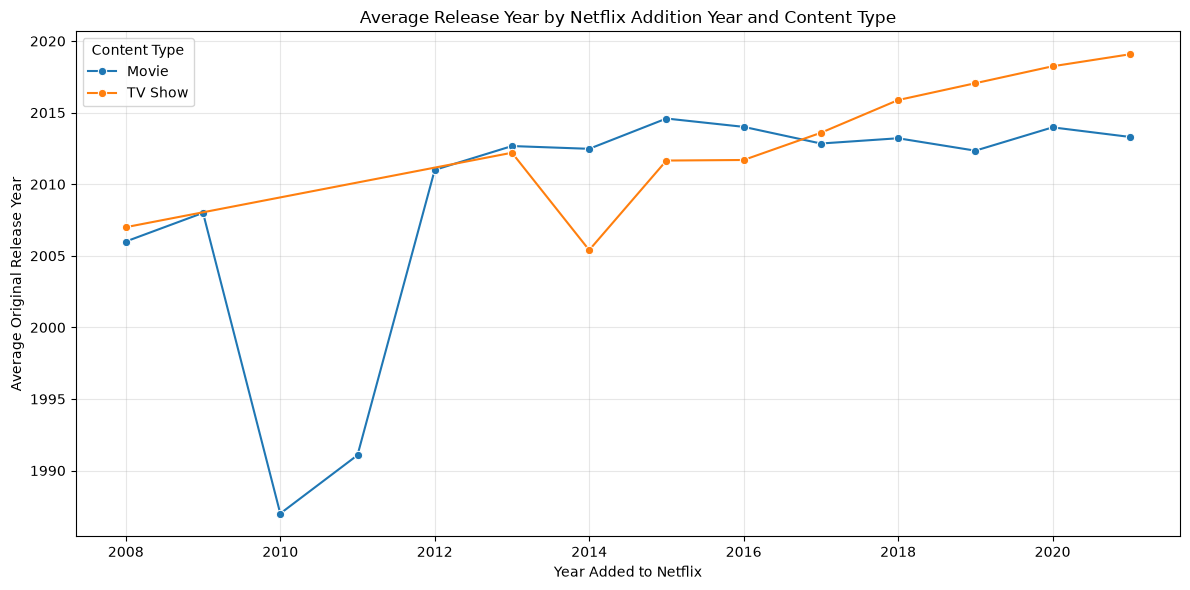


Overall Mean Release Year by Content Type:


type
Movie      2013.12
TV Show    2016.61
Name: release_year, dtype: float64

In [30]:
# Select records with valid addition years
multi_year_data = netflix_clean.dropna(
    subset=["year_added"]
).copy()

# Calculate mean release year by addition year and content type
release_added_summary = (
    multi_year_data
    .groupby(["year_added", "type"])
    .agg(
        Average_Release_Year=("release_year", "mean"),
        Median_Release_Year=("release_year", "median"),
        Number_of_Titles=("show_id", "count")
    )
    .reset_index()
)

print("Release Year by Addition Year and Content Type:")
display(release_added_summary.round(2))

# Visualize the relationship
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=release_added_summary,
    x="year_added",
    y="Average_Release_Year",
    hue="type",
    marker="o"
)

plt.title(
    "Average Release Year by Netflix Addition Year and Content Type"
)
plt.xlabel("Year Added to Netflix")
plt.ylabel("Average Original Release Year")
plt.legend(title="Content Type")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Compare overall release years against grouped release years
print("\nOverall Mean Release Year by Content Type:")
display(
    netflix_clean.groupby("type")["release_year"]
    .mean()
    .round(2)
)

In [ ]:

### Interpretation

This analysis compares the average release year of movies and TV shows across different Netflix addition years.

Separating titles by content type makes it possible to see whether both categories follow similar patterns.

The grouped results also help determine whether movies and TV shows added during the same year were originally released around the same period.

If the average release year increases across addition years, this would indicate that newer additions generally contain more recently released titles.

However, the number of titles added varies considerably between years, so patterns in years with very few records should be interpreted carefully.

This analysis is useful because it considers content type alongside two time-related variables instead of examining release years alone.


In [ ]:

### A6.2 Maturity Ratings Across Content Types and Addition Years

Next, I examined whether maturity rating patterns changed over time for movies and TV shows.

The three variables used are rating, type, and year_added.

I selected the four most common ratings and compared how their proportions changed in different addition years.

Rather than comparing only the number of titles, I calculated percentages within each content type and addition year.

This makes the comparison more meaningful because movies and TV shows have different total counts.


,year_added,type,rating,Rating_Count,Total_Titles,Percentage
0,2016.0,Movie,TV-MA,114.0,253,45.06
1,2016.0,Movie,TV-14,40.0,253,15.81
2,2016.0,Movie,TV-PG,25.0,253,9.88
3,2016.0,Movie,R,13.0,253,5.14
4,2016.0,TV Show,TV-MA,48.0,176,27.27
5,2016.0,TV Show,TV-14,58.0,176,32.95
6,2016.0,TV Show,TV-PG,25.0,176,14.20
7,2016.0,TV Show,R,1.0,176,0.57
8,2017.0,Movie,TV-MA,353.0,839,42.07
9,2017.0,Movie,TV-14,188.0,839,22.41


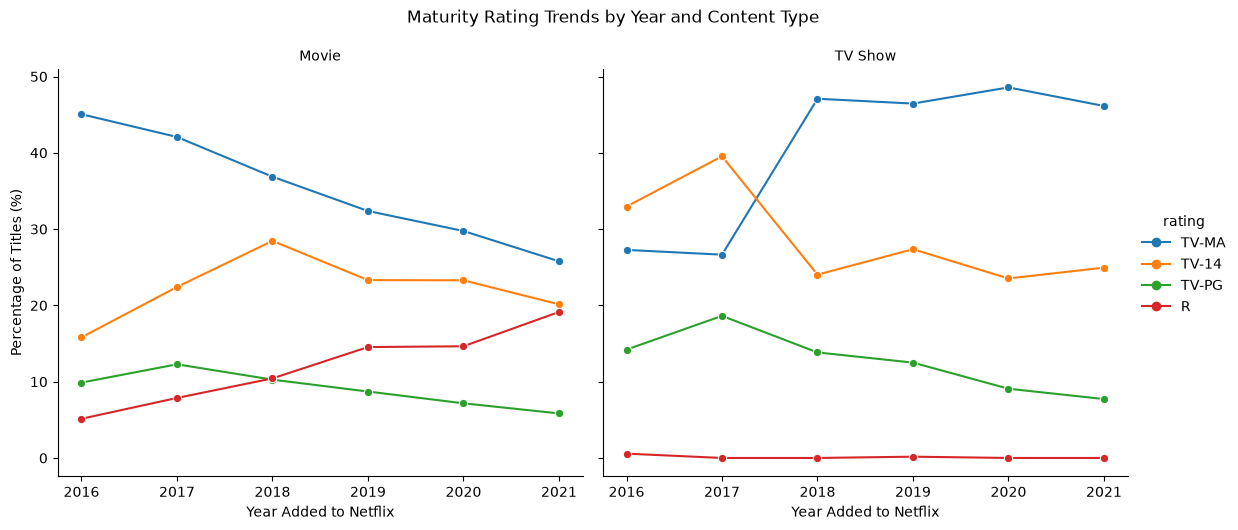

In [31]:
# Select the four most common ratings
top_ratings = (
    netflix_clean["rating"]
    .value_counts()
    .head(4)
    .index
    .tolist()
)

# Remove records with missing addition years
rating_multi = netflix_clean.dropna(
    subset=["year_added"]
).copy()

# Focus on years with substantial catalogue additions
rating_multi = rating_multi[
    rating_multi["year_added"].between(2016, 2021)
]

# Calculate total titles within each year and content type
group_totals = (
    rating_multi
    .groupby(["year_added", "type"])
    .size()
    .reset_index(name="Total_Titles")
)

# Count titles by year, type, and rating
rating_summary = (
    rating_multi[
        rating_multi["rating"].isin(top_ratings)
    ]
    .groupby(["year_added", "type", "rating"])
    .size()
    .reset_index(name="Rating_Count")
)

# Include all combinations, including zero counts
years = sorted(rating_multi["year_added"].unique())
types = sorted(rating_multi["type"].unique())

all_groups = pd.MultiIndex.from_product(
    [years, types, top_ratings],
    names=["year_added", "type", "rating"]
).to_frame(index=False)

rating_summary = all_groups.merge(
    rating_summary,
    on=["year_added", "type", "rating"],
    how="left"
)

rating_summary["Rating_Count"] = (
    rating_summary["Rating_Count"].fillna(0)
)

rating_summary = rating_summary.merge(
    group_totals,
    on=["year_added", "type"],
    how="left"
)

rating_summary["Percentage"] = (
    rating_summary["Rating_Count"]
    / rating_summary["Total_Titles"] * 100
)

display(rating_summary.round(2))

# Plot separate panels for movies and TV shows
g = sns.relplot(
    data=rating_summary,
    x="year_added",
    y="Percentage",
    hue="rating",
    col="type",
    kind="line",
    marker="o",
    height=5,
    aspect=1.15
)

g.set_axis_labels(
    "Year Added to Netflix",
    "Percentage of Titles (%)"
)

g.set_titles("{col_name}")
g.figure.suptitle(
    "Maturity Rating Trends by Year and Content Type",
    y=1.05
)

plt.show()

In [ ]:

### Interpretation

This analysis shows how the proportions of common maturity ratings changed across Netflix addition years for movies and TV shows.

Using separate panels makes it easier to compare the patterns within each content type.

The percentages are calculated using the total number of titles added in each year and category, which helps avoid misleading comparisons caused by differences in group sizes.

The results can show whether a particular rating became more or less common over time and whether the change was similar for movies and TV shows.

However, ratings are classification labels, and differences may partly reflect the different rating systems used for movies and television content.

These patterns describe the available Netflix dataset and do not necessarily represent changes in Netflix's current content policies.


In [ ]:

### A6.3 Country, Genre and Content Type

I also examined whether the most common content categories differ between major production countries and content types.

The variables used are country, listed_in, and type.

Since country and listed_in may contain several values in a single record, I separated their comma-separated entries before counting them.

I selected the five most frequently represented countries and compared their content categories separately for movies and TV shows.

A heatmap was used because it allows several countries and content categories to be compared at the same time.


Country, Content Type and Genre Summary:


,country,type,listed_in,Titles,Total_Titles,Percentage
0,Canada,Movie,Action & Adventure,44,319,13.79
1,Canada,Movie,Children & Family Movies,80,319,25.08
2,Canada,Movie,Comedies,94,319,29.47
3,Canada,Movie,Documentaries,42,319,13.17
4,Canada,Movie,Dramas,82,319,25.71
5,Canada,Movie,Independent Movies,44,319,13.79
6,Canada,Movie,International Movies,60,319,18.81
7,Canada,Movie,Thrillers,49,319,15.36
8,France,Movie,Action & Adventure,37,303,12.21
9,France,Movie,Children & Family Movies,23,303,7.59


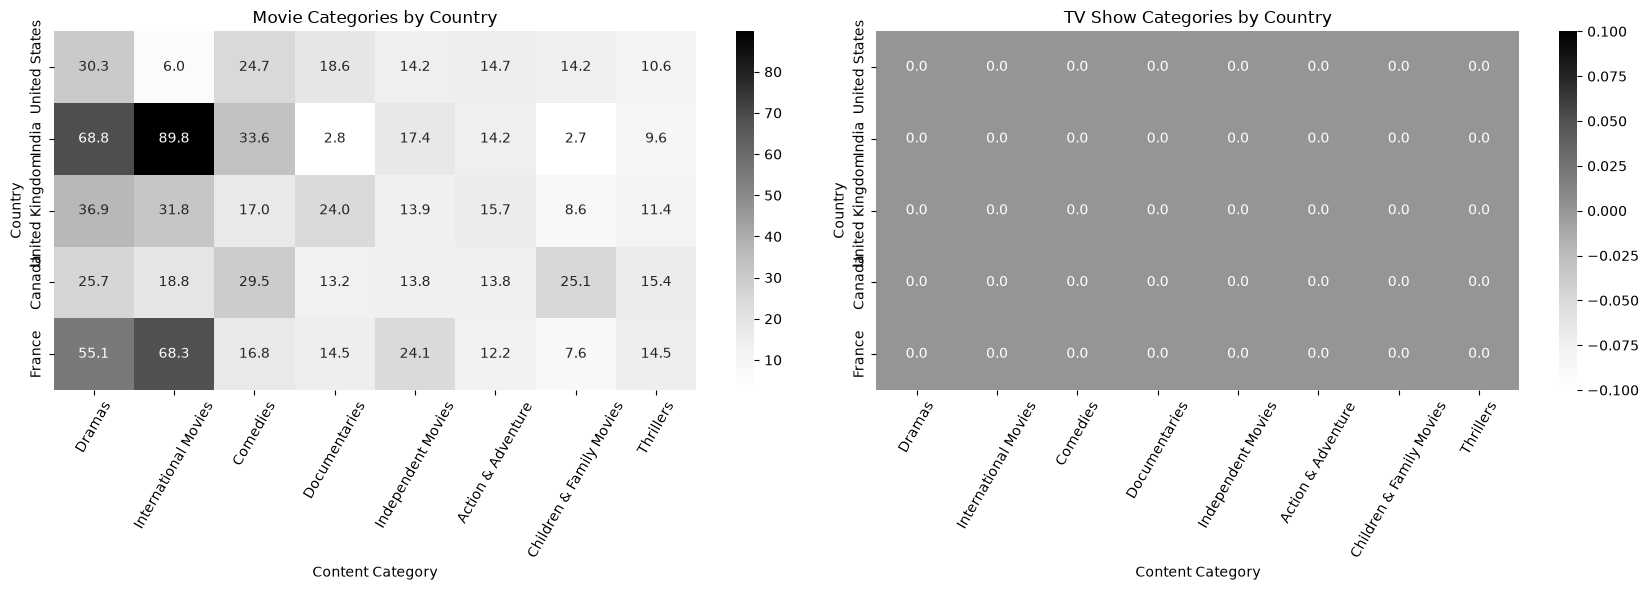

In [32]:
# Create a working copy for country and genre analysis
country_genre_data = netflix_clean[
    netflix_clean["country"] != "Unknown"
].copy()

# Separate multiple countries
country_genre_data["country"] = (
    country_genre_data["country"].str.split(",")
)

country_genre_data = country_genre_data.explode("country")

country_genre_data["country"] = (
    country_genre_data["country"].str.strip()
)

# Select the five most represented countries
top_five_countries = (
    country_genre_data["country"]
    .value_counts()
    .head(5)
    .index
    .tolist()
)

country_genre_data = country_genre_data[
    country_genre_data["country"].isin(top_five_countries)
].copy()

# Count unique titles per country and content type
country_type_totals = (
    country_genre_data
    .groupby(["country", "type"])["show_id"]
    .nunique()
    .rename("Total_Titles")
)

# Separate multiple genres
country_genre_data["listed_in"] = (
    country_genre_data["listed_in"].str.split(",")
)

country_genre_data = country_genre_data.explode("listed_in")

country_genre_data["listed_in"] = (
    country_genre_data["listed_in"].str.strip()
)

# Select common categories within the five countries
common_genres = (
    country_genre_data["listed_in"]
    .value_counts()
    .head(8)
    .index
    .tolist()
)

# Count categories by country and content type
genre_country_counts = (
    country_genre_data[
        country_genre_data["listed_in"].isin(common_genres)
    ]
    .groupby(["country", "type", "listed_in"])["show_id"]
    .nunique()
    .reset_index(name="Titles")
)

# Calculate percentages relative to each country/type group
genre_country_counts = genre_country_counts.merge(
    country_type_totals.reset_index(),
    on=["country", "type"],
    how="left"
)

genre_country_counts["Percentage"] = (
    genre_country_counts["Titles"]
    / genre_country_counts["Total_Titles"] * 100
)

print("Country, Content Type and Genre Summary:")
display(genre_country_counts.round(2))

# Create separate heatmaps for movies and TV shows
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for ax, content_type in zip(axes, ["Movie", "TV Show"]):

    subset = genre_country_counts[
        genre_country_counts["type"] == content_type
    ]

    pivot_table = subset.pivot(
        index="country",
        columns="listed_in",
        values="Percentage"
    )

    pivot_table = pivot_table.reindex(
        index=top_five_countries,
        columns=common_genres
    ).fillna(0)

    sns.heatmap(
        pivot_table,
        annot=True,
        fmt=".1f",
        cmap="Greys",
        ax=ax
    )

    ax.set_title(f"{content_type} Categories by Country")
    ax.set_xlabel("Content Category")
    ax.set_ylabel("Country")
    ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

This analysis compares the content categories associated with major production countries while separating movies and TV shows.

The heatmaps make it possible to see whether the same countries have similar category distributions across both content types.

Using percentages rather than only raw counts is important because the total number of titles differs between countries.

A category may account for a large proportion of one country's titles even when that country has fewer titles overall.

The results also show why country and genre information should be separated into individual values before analysis.

Since a title may belong to multiple categories or involve several countries, these percentages are not mutually exclusive and do not necessarily add up to 100%.

The comparison helps identify differences in the recorded catalogue, but it does not establish why particular countries are associated with particular genres.


In [ ]:

### A6 Summary

The multivariate analysis allowed me to examine relationships that were not fully visible when comparing only two variables.

The first analysis considered content type alongside release year and Netflix addition year.

The second examined how maturity rating proportions changed across addition years for movies and TV shows.

The third compared content categories across major production countries while separating movies from TV shows.

These analyses show how an additional variable can change the way a pattern is interpreted.

They also highlight the importance of using appropriate group sizes and percentages when comparing categories with different numbers of records.


In [ ]:

## A7. Netflix-Specific Analytical Questions

In this section, I focused on five questions about the Netflix dataset.

I examined how the balance between movies and TV shows changed over time, how long after their original release titles were added to Netflix, and which countries and genres were most common.

I also compared maturity ratings across content types and examined unusual movie durations and TV show season counts.

Some of these relationships were explored in previous sections. Here, I have brought the main results together to answer each question directly.


In [ ]:

### A7.1 Changes in Movies and TV Shows Over Time

I wanted to see whether the proportion of movies and TV shows changed across different years.

For this analysis, I used both release_year and year_added.

I calculated the percentage of movies and TV shows in each year rather than comparing only their counts. This is useful because the total number of titles differs from year to year.

I used line charts to make it easier to identify changes in the balance between the two content types.


Content Mix by Release Year:


type,Movie,TV Show
release_year,,
2010,79.38,20.62
2011,78.38,21.62
2012,73.00,27.00
2013,78.12,21.88
2014,75.00,25.00
2015,71.07,28.93
2016,72.95,27.05
2017,74.32,25.68
2018,66.87,33.13


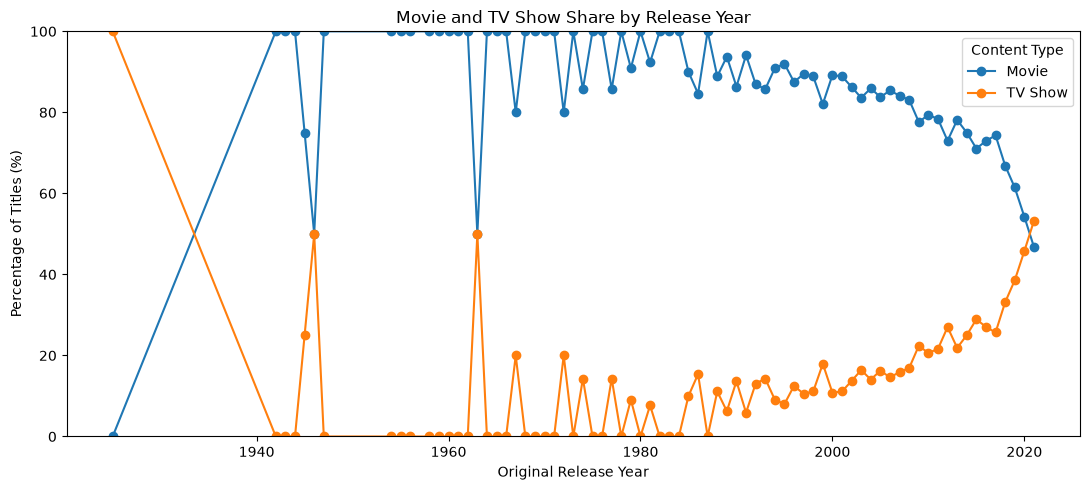


Content Mix by Netflix Addition Year:


type,Movie,TV Show
year_added,,
2008.0,50.00,50.00
2009.0,100.00,0.00
2010.0,100.00,0.00
2011.0,100.00,0.00
2012.0,100.00,0.00
2013.0,54.55,45.45
2014.0,79.17,20.83
2015.0,68.29,31.71
2016.0,58.97,41.03


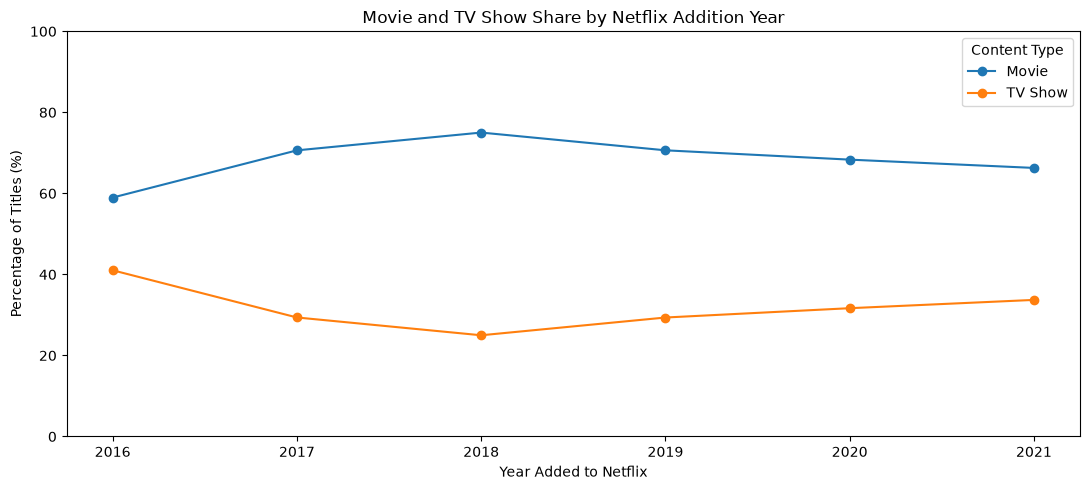

In [33]:
# Compare content types by original release year

release_mix = pd.crosstab(
    netflix_clean["release_year"],
    netflix_clean["type"],
    normalize="index"
) * 100

print("Content Mix by Release Year:")
display(release_mix.round(2).tail(12))

plt.figure(figsize=(11, 5))

for content_type in ["Movie", "TV Show"]:
    plt.plot(
        release_mix.index,
        release_mix[content_type],
        marker="o",
        label=content_type
    )

plt.title("Movie and TV Show Share by Release Year")
plt.xlabel("Original Release Year")
plt.ylabel("Percentage of Titles (%)")
plt.ylim(0, 100)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


# Compare content types by Netflix addition year

addition_mix = pd.crosstab(
    netflix_clean["year_added"],
    netflix_clean["type"],
    normalize="index"
) * 100

print("\nContent Mix by Netflix Addition Year:")
display(addition_mix.round(2))

# Focus on years with substantial numbers of additions
recent_addition_mix = addition_mix.loc[
    addition_mix.index >= 2016
]

plt.figure(figsize=(11, 5))

for content_type in ["Movie", "TV Show"]:
    plt.plot(
        recent_addition_mix.index,
        recent_addition_mix[content_type],
        marker="o",
        label=content_type
    )

plt.title("Movie and TV Show Share by Netflix Addition Year")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Percentage of Titles (%)")
plt.ylim(0, 100)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The Netflix dataset contains more movies than TV shows overall, with movies accounting for approximately 69.6% of titles.

The yearly percentage tables show how this balance changes depending on whether the original release year or the Netflix addition year is considered.

Looking at percentages is more useful than comparing raw counts because the number of titles varies considerably between years.

The release-year analysis describes the types of content produced in different years, while the addition-year analysis describes the composition of titles added to Netflix during those years.

These patterns should be interpreted carefully because the dataset does not cover every year equally, and the final year may be incomplete.


In [ ]:

### A7.2 Gap Between Release Year and Netflix Addition Year

I examined how many years passed between a title's original release and the year it was added to Netflix.

I calculated this using the addition_gap variable created during data cleaning.

I then compared the gaps for movies and TV shows to see whether one content type generally contained older releases.

A histogram was used to show the overall distribution, while a box plot was used to compare both content types.


Overall Addition Gap Statistics:


count    8797.000000
mean        4.688417
std         8.786998
min        -3.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: addition_gap, dtype: float64


Addition Gap by Content Type:


,count,mean,median,std,min,max
type,,,,,,
Movie,6131,5.73,2.0,9.74,-1.0,75.0
TV Show,2666,2.30,0.0,5.32,-3.0,93.0



Negative Addition Gaps: 14


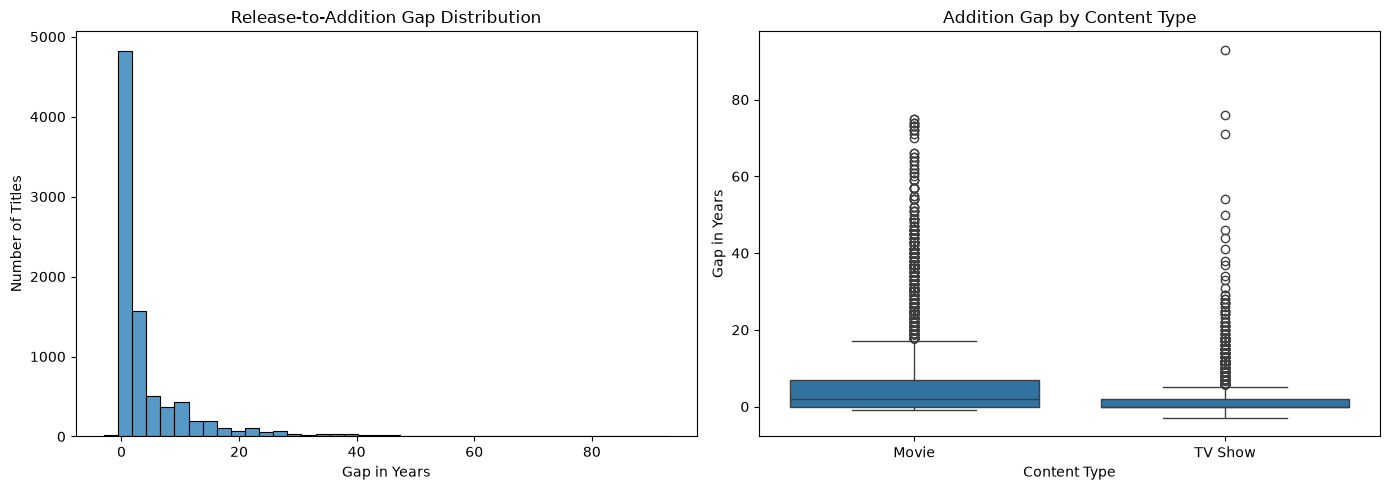

In [34]:
gap_data = netflix_clean.dropna(
    subset=["addition_gap"]
).copy()

print("Overall Addition Gap Statistics:")
display(gap_data["addition_gap"].describe())

print("\nAddition Gap by Content Type:")
gap_summary = (
    gap_data.groupby("type")["addition_gap"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(gap_summary)

print(
    "\nNegative Addition Gaps:",
    (gap_data["addition_gap"] < 0).sum()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=gap_data,
    x="addition_gap",
    bins=40,
    ax=axes[0]
)

axes[0].set_title("Release-to-Addition Gap Distribution")
axes[0].set_xlabel("Gap in Years")
axes[0].set_ylabel("Number of Titles")

sns.boxplot(
    data=gap_data,
    x="type",
    y="addition_gap",
    ax=axes[1]
)

axes[1].set_title("Addition Gap by Content Type")
axes[1].set_xlabel("Content Type")
axes[1].set_ylabel("Gap in Years")

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The release-to-addition gap shows how long after their original release titles were added to Netflix.

A small gap means that a title was added relatively soon after its release, while a larger gap means it was added several years later.

Comparing movies and TV shows helps determine whether the catalogue contains different proportions of older content in the two categories.

Titles with unusually large gaps may represent older productions that became available on Netflix much later.

However, this analysis cannot explain why a title was added at a particular time. Licensing arrangements, availability, or other factors may play a role, but these cannot be confirmed from the dataset.

Records with missing addition dates were excluded from this comparison.


In [ ]:

### A7.3 Most Common Countries and Genres

I examined the countries and content categories most frequently associated with Netflix titles.

Both country and listed_in can contain multiple values in one record, so I separated the entries before counting them.

I also compared genre profiles across the three most represented countries to see whether the same categories are equally common in each country.

I used bar charts for the overall rankings and a heatmap for the country-level comparison.


Top 10 Countries:


country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


Top 10 Content Categories:


listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

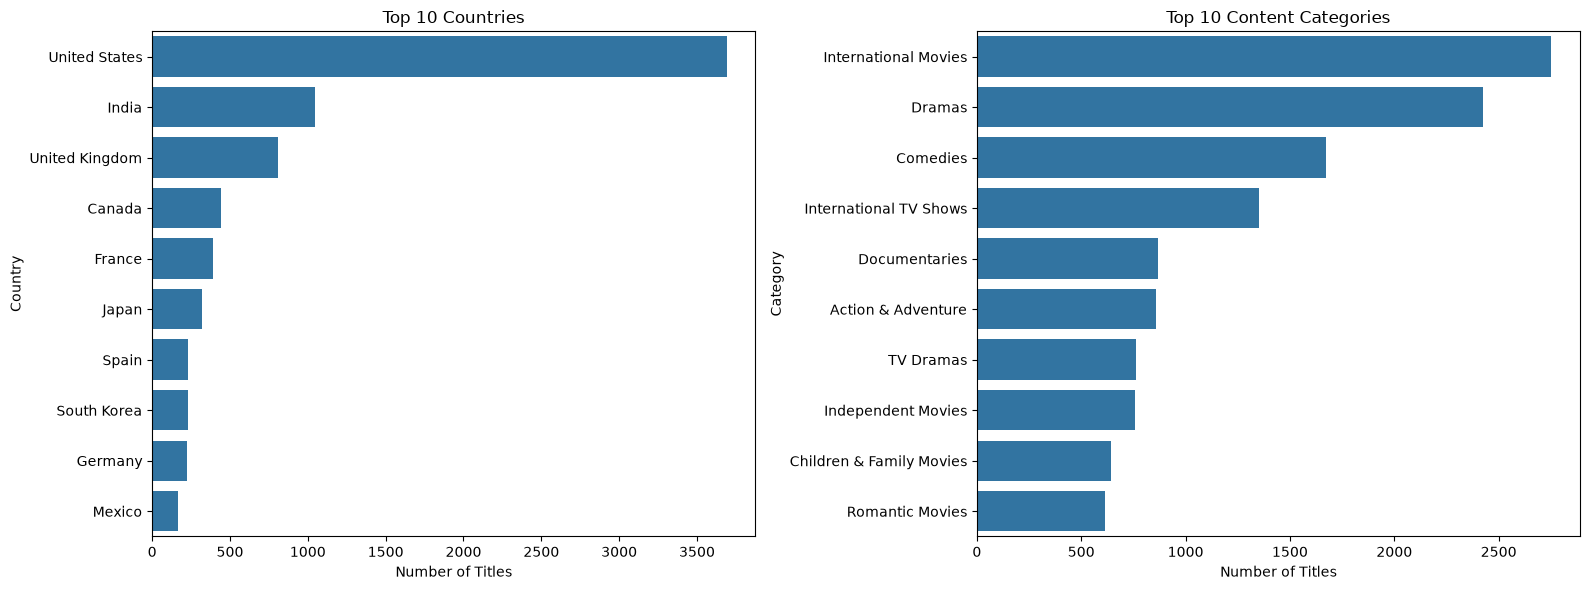

ValueError: cannot reindex on an axis with duplicate labels

In [35]:
# Separate countries

country_data = netflix_clean[
    netflix_clean["country"] != "Unknown"
].copy()

country_data["country"] = (
    country_data["country"].str.split(",")
)

country_data = country_data.explode("country")
country_data["country"] = country_data["country"].str.strip()

top_countries = country_data["country"].value_counts().head(10)

print("Top 10 Countries:")
display(top_countries)


# Separate content categories

genre_data = netflix_clean.copy()

genre_data["listed_in"] = (
    genre_data["listed_in"].str.split(",")
)

genre_data = genre_data.explode("listed_in")
genre_data["listed_in"] = genre_data["listed_in"].str.strip()

top_genres = genre_data["listed_in"].value_counts().head(10)

print("\nTop 10 Content Categories:")
display(top_genres)


# Visualizations

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    ax=axes[0]
)

axes[0].set_title("Top 10 Countries")
axes[0].set_xlabel("Number of Titles")
axes[0].set_ylabel("Country")

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    ax=axes[1]
)

axes[1].set_title("Top 10 Content Categories")
axes[1].set_xlabel("Number of Titles")
axes[1].set_ylabel("Category")

plt.tight_layout()
plt.show()


# Compare categories across top three countries

top_three = top_countries.head(3).index.tolist()

country_genre = country_data[
    country_data["country"].isin(top_three)
].copy()

country_totals = (
    country_genre.groupby("country")["show_id"]
    .nunique()
)

country_genre["listed_in"] = (
    country_genre["listed_in"].str.split(",")
)

country_genre = country_genre.explode("listed_in")
country_genre["listed_in"] = (
    country_genre["listed_in"].str.strip()
)

profile = pd.crosstab(
    country_genre["country"],
    country_genre["listed_in"]
)

profile_percent = profile.div(
    country_totals,
    axis=0
) * 100

common_categories = (
    country_genre["listed_in"]
    .value_counts()
    .head(8)
    .index
)

print("\nGenre Profiles (% of Country Titles):")
display(profile_percent[common_categories].round(2))

plt.figure(figsize=(12, 5))

sns.heatmap(
    profile_percent[common_categories],
    annot=True,
    fmt=".1f",
    cmap="Greys"
)

plt.title("Genre Profiles Across Top Three Countries")
plt.xlabel("Content Category")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The United States is the most frequently represented country, appearing in 3,690 titles.

India ranks second with 1,046 titles, followed by the United Kingdom with 806 titles.

For content categories, International Movies is the most common with 2,752 titles, followed by Dramas with 2,427 and Comedies with 1,674.

The country-level genre comparison helps show whether these categories are equally prominent across the leading production countries.

Since a title may involve several countries and belong to multiple categories, the counts are not mutually exclusive.

The percentages in the heatmap represent the share of titles associated with each category within a country. They do not need to add up to 100%.

These results describe country and genre representation in the available Netflix catalogue rather than the total film and television production of each country.


In [ ]:

### A7.4 Maturity Ratings by Content Type and Time

I examined how maturity ratings are distributed across movies and TV shows and whether their proportions changed over time.

I first compared the most common ratings for the two content types.

I then focused on recent Netflix addition years to see whether the proportion of titles with particular ratings changed.

Percentages were used because the total number of movies and TV shows differs between years.


Rating Counts by Content Type:


type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,733
TV-G,126,94
TV-MA,2062,1145



Rating Percentages:


type,Movie,TV Show
rating,,
G,0.67,0.00
NC-17,0.05,0.00
NR,1.22,0.19
PG,4.68,0.00
PG-13,7.99,0.00
R,13.00,0.07
TV-14,23.28,27.39
TV-G,2.06,3.51
TV-MA,33.63,42.79


,year_added,type,rating,Count,Total,Percentage
0,2016.0,Movie,R,13,253,5.14
1,2016.0,Movie,TV-14,40,253,15.81
2,2016.0,Movie,TV-MA,114,253,45.06
3,2016.0,Movie,TV-PG,25,253,9.88
4,2016.0,TV Show,R,1,176,0.57
5,2016.0,TV Show,TV-14,58,176,32.95
6,2016.0,TV Show,TV-MA,48,176,27.27
7,2016.0,TV Show,TV-PG,25,176,14.20
8,2017.0,Movie,R,66,839,7.87
9,2017.0,Movie,TV-14,188,839,22.41


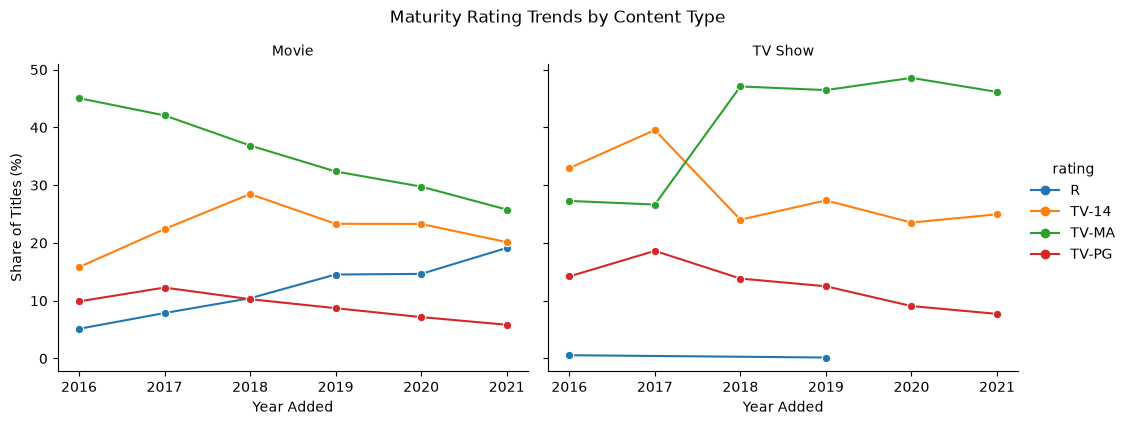

In [36]:
# Ratings by content type

rating_type = pd.crosstab(
    netflix_clean["rating"],
    netflix_clean["type"]
)

print("Rating Counts by Content Type:")
display(rating_type)

rating_percentage = pd.crosstab(
    netflix_clean["rating"],
    netflix_clean["type"],
    normalize="columns"
) * 100

print("\nRating Percentages:")
display(rating_percentage.round(2))


# Rating trends over time

rating_recent = netflix_clean[
    netflix_clean["year_added"].between(2016, 2021)
].copy()

top_ratings = (
    netflix_clean["rating"]
    .value_counts()
    .head(4)
    .index
    .tolist()
)

# Denominator includes all ratings, not just top four
totals = (
    rating_recent.groupby(["year_added", "type"])
    .size()
    .rename("Total")
    .reset_index()
)

rating_trends = (
    rating_recent[
        rating_recent["rating"].isin(top_ratings)
    ]
    .groupby(["year_added", "type", "rating"])
    .size()
    .rename("Count")
    .reset_index()
)

rating_trends = rating_trends.merge(
    totals,
    on=["year_added", "type"],
    how="left"
)

rating_trends["Percentage"] = (
    rating_trends["Count"] /
    rating_trends["Total"] * 100
)

display(rating_trends.round(2))

g = sns.relplot(
    data=rating_trends,
    x="year_added",
    y="Percentage",
    hue="rating",
    col="type",
    kind="line",
    marker="o",
    height=4,
    aspect=1.3
)

g.set_axis_labels(
    "Year Added",
    "Share of Titles (%)"
)

g.set_titles("{col_name}")
g.figure.suptitle(
    "Maturity Rating Trends by Content Type",
    y=1.05
)

plt.show()

In [37]:

### Interpretation

TV-MA is the most frequently recorded maturity rating in the Netflix dataset, with 3,207 titles.

TV-14 is the second most common rating, appearing in 2,160 titles.

The distribution differs between movies and TV shows. For example, PG and PG-13 are associated with movies, while categories such as TV-Y and TV-Y7 are more common among TV shows.

The yearly comparison shows how the proportions of common ratings change over the period covered by the dataset.

These differences may reflect changes in the composition of titles added over time, although the dataset does not explain why these changes occurred.

The results should also be interpreted with the understanding that movie and television rating classifications are not always directly comparable.


SyntaxError: invalid syntax (137812632.py, line 3)

In [ ]:

### A7.5 Movie Durations, TV Show Seasons and Unusual Cases

Finally, I examined the distribution of movie durations and TV show season counts.

I analyzed both variables separately because movies are measured in minutes while TV shows are measured in seasons.

I used descriptive statistics, histograms, and box plots to understand their distributions.

I also considered the outliers identified earlier and explained why they were retained instead of being removed.


Movie Duration Statistics:


count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: movie_minutes, dtype: float64


TV Show Season Statistics:


count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: season_count, dtype: float64


Movie Duration IQR: 27.0
Lower Bound: 46.5
Upper Bound: 154.5
Potential Outliers: 450

Longest Movies:


,title,movie_minutes
4253,Black Mirror: Bandersnatch,312.0
717,Headspace: Unwind Your Mind,273.0
2491,The School of Mischief,253.0
2487,No Longer kids,237.0
2484,Lock Your Girls In,233.0
2488,Raya and Sakina,230.0
166,Once Upon a Time in America,229.0
7932,Sangam,228.0
1019,Lagaan,224.0
4573,Jodhaa Akbar,214.0


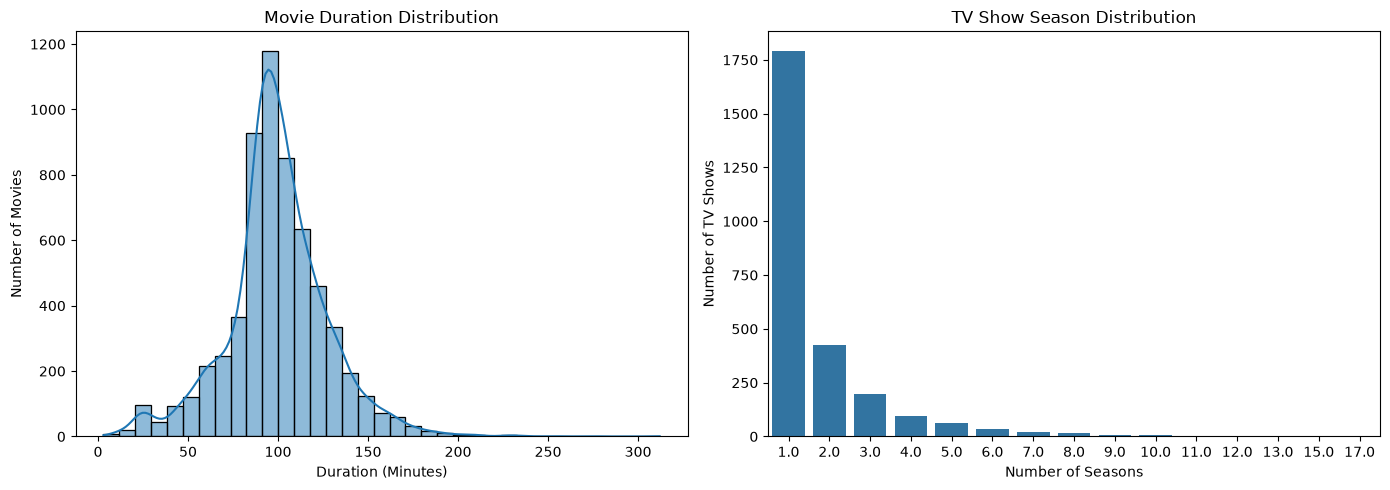

In [38]:
movies = netflix_clean[
    netflix_clean["type"] == "Movie"
].copy()

tv_shows = netflix_clean[
    netflix_clean["type"] == "TV Show"
].copy()

print("Movie Duration Statistics:")
display(movies["movie_minutes"].describe())

print("\nTV Show Season Statistics:")
display(tv_shows["season_count"].describe())


# IQR outlier detection for movies

Q1 = movies["movie_minutes"].quantile(0.25)
Q3 = movies["movie_minutes"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = movies[
    (movies["movie_minutes"] < lower_bound) |
    (movies["movie_minutes"] > upper_bound)
]

print("\nMovie Duration IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Potential Outliers:", len(outliers))

print("\nLongest Movies:")
display(
    movies[
        ["title", "movie_minutes"]
    ].sort_values(
        "movie_minutes",
        ascending=False
    ).head(10)
)


# Visualizations

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=movies,
    x="movie_minutes",
    bins=35,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Movie Duration Distribution")
axes[0].set_xlabel("Duration (Minutes)")
axes[0].set_ylabel("Number of Movies")

sns.countplot(
    data=tv_shows,
    x="season_count",
    ax=axes[1]
)

axes[1].set_title("TV Show Season Distribution")
axes[1].set_xlabel("Number of Seasons")
axes[1].set_ylabel("Number of TV Shows")

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The average movie duration is approximately 99.56 minutes, while the median is 98 minutes.

The middle 50% of movie durations lie between 87 and 114 minutes.

The IQR method identified 450 potential movie duration outliers, with thresholds of 46.5 and 154.5 minutes.

The longest recorded title was Black Mirror: Bandersnatch, with a listed duration of 312 minutes.

TV shows have an average of approximately 1.76 seasons and a median of one season. The highest recorded season count is 17.

These results indicate that most movies have durations close to typical feature-film lengths, while most TV shows have relatively few seasons.

Unusually short or long movies were retained because they may represent valid content. The three misplaced duration values identified during data cleaning were corrected rather than removed.

This approach preserves the available information without making unsupported assumptions about unusual observations.


In [ ]:

## A8. Netflix Insights and Assignment 3 Handoff

After completing the exploratory analysis, I selected five findings that help explain the main characteristics of the Netflix dataset.

Each insight includes an observation supported by the results, followed by an interpretation of what it suggests.

I have avoided making claims about the reasons behind these patterns because the dataset does not contain enough information to establish them.


In [39]:
# Summary statistics for final Netflix insights

total_titles = len(netflix_clean)

movie_count = (netflix_clean["type"] == "Movie").sum()
tv_count = (netflix_clean["type"] == "TV Show").sum()

movie_percentage = movie_count / total_titles * 100
tv_percentage = tv_count / total_titles * 100

top_release_year = (
    netflix_clean["release_year"].value_counts().idxmax()
)

top_release_count = (
    netflix_clean["release_year"].value_counts().max()
)

average_movie_duration = (
    netflix_clean.loc[
        netflix_clean["type"] == "Movie",
        "movie_minutes"
    ].mean()
)

median_movie_duration = (
    netflix_clean.loc[
        netflix_clean["type"] == "Movie",
        "movie_minutes"
    ].median()
)

average_tv_seasons = (
    netflix_clean.loc[
        netflix_clean["type"] == "TV Show",
        "season_count"
    ].mean()
)

print("Total Titles:", total_titles)
print(f"Movies: {movie_count} ({movie_percentage:.2f}%)")
print(f"TV Shows: {tv_count} ({tv_percentage:.2f}%)")

print(
    f"Most Common Release Year: "
    f"{top_release_year} ({top_release_count} titles)"
)

print(
    f"Average Movie Duration: "
    f"{average_movie_duration:.2f} minutes"
)

print(
    f"Median Movie Duration: "
    f"{median_movie_duration:.2f} minutes"
)

print(
    f"Average TV Show Seasons: "
    f"{average_tv_seasons:.2f}"
)

print("\nTop Countries:")
display(top_countries.head(5))

print("\nTop Content Categories:")
display(top_genres.head(5))

Total Titles: 8807
Movies: 6131 (69.62%)
TV Shows: 2676 (30.38%)
Most Common Release Year: 2018 (1147 titles)
Average Movie Duration: 99.56 minutes
Median Movie Duration: 98.00 minutes
Average TV Show Seasons: 1.76

Top Countries:


country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Name: count, dtype: int64


Top Content Categories:


listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

In [ ]:

### A8.1 Five Key Insights

#### Insight 1: Movies make up most of the Netflix catalogue

Observation:

The dataset contains 6,131 movies (69.61%) and 2,676 TV shows (30.39%).

Interpretation:

Movies account for more than two-thirds of the titles in the dataset. This shows that movies are more heavily represented than TV shows in the available catalogue.

The difference is quite large, with approximately 2.29 movies for every TV show.

This describes the composition of the dataset rather than Netflix's current catalogue.

#### Insight 2: Most titles were released in relatively recent years

Observation:

The release years range from 1925 to 2021. The most common release year is 2018, with 1,147 titles, followed by 2017 with 1,032 and 2019 with 1,030.

Interpretation:

Although the dataset includes older productions, titles released in more recent years make up a large portion of the catalogue.

The distribution suggests that relatively recent content is more heavily represented than older releases.

However, the dataset does not explain why particular release years contain more titles.

#### Insight 3: The United States has the highest country representation

Observation:

The United States is associated with 3,690 titles, followed by India with 1,046 and the United Kingdom with 806.

Interpretation:

The United States has the largest representation among the countries recorded in the dataset.

India and the United Kingdom also account for a substantial number of titles.

Since some productions involve multiple countries, one title may contribute to the counts of several countries.

These counts represent country associations rather than exclusive national production totals.

#### Insight 4: International content and dramas are common categories

Observation:

International Movies appears in 2,752 titles, followed by Dramas with 2,427 and Comedies with 1,674.

Interpretation:

International Movies and Dramas are among the most frequently recorded content categories.

This indicates that international productions and drama-related content are well represented in the dataset.

Because titles can belong to multiple categories, these counts overlap and should not be added together to calculate the number of unique titles.

#### Insight 5: Most movies and TV shows have relatively short recorded durations

Observation:

Movies have an average duration of approximately 99.56 minutes and a median of 98 minutes.

TV shows have an average of approximately 1.76 seasons and a median of one season.

The IQR method identified 450 potential movie-duration outliers.

Interpretation:

Most movies have durations close to the typical feature-film range, while many TV shows have only one or two seasons recorded.

The presence of unusually short and long movies shows that the catalogue contains a variety of content formats.

These outliers were retained because unusual durations do not necessarily indicate incorrect data.


In [ ]:

### A8.2 Handoff Note for Assignment 3

The cleaned Netflix dataset contains useful variables such as content type, release year, year added, maturity rating, production country, content categories, and duration.

The derived variables addition_gap, num_countries, and num_genres may also be useful for further analysis.

The show_id column should be treated as an identifier rather than a numerical feature. The country, cast, director, and listed_in columns contain multiple values and may require additional encoding.

Movie durations and TV show season counts should remain separate because they use different units.

Missing descriptive values were labelled Unknown, while missing addition dates were retained as null values. These decisions should be considered when filtering records or building models.

Several financial-style numerical relationships are not relevant to this dataset, so future analysis should focus on content characteristics and temporal patterns.


In [ ]:

### A8.3 Cleaned Dataset Publication

Original Dataset Source:
https://www.kaggle.com/datasets/shivamb/netflix-shows

Cleaned Dataset Filename:
23L_0977_A2_netflix_cleaned.csv

Published Dataset Link:
To be added after GitHub or Kaggle publication.

Dataset Version:
v1.0 (planned)

Cleaning Summary:

The cleaned dataset retains all 8,807 original titles. Missing descriptive information was labelled Unknown, misplaced durations were corrected, and date values were converted into a suitable format.

Additional features were created for temporal analysis, movie durations, TV show seasons, country counts, genre counts, and release-to-addition gaps.

The cleaned file will be published as a versioned dataset so the same data can be reused in Assignment 3.


In [40]:
# Export final cleaned Netflix dataset

netflix_clean.to_csv(
    "23L_0977_A2_netflix_cleaned.csv",
    index=False
)

# Read exported CSV for verification
netflix_verified = pd.read_csv(
    "23L_0977_A2_netflix_cleaned.csv"
)

print("Exported Dataset Shape:", netflix_verified.shape)

print("\nOriginal Records:", len(netflix_df))
print("Exported Records:", len(netflix_verified))

print("\nDuplicate Show IDs:",
      netflix_verified["show_id"].duplicated().sum())

print("\nFinal Columns:")
display(netflix_verified.columns.tolist())

print("\nCSV Export Completed Successfully.")

Exported Dataset Shape: (8807, 20)

Original Records: 8807
Exported Records: 8807

Duplicate Show IDs: 0

Final Columns:


['show_id',
 'type',
 'title',
 'director',
 'cast',
 'country',
 'date_added',
 'release_year',
 'rating',
 'duration',
 'listed_in',
 'description',
 'year_added',
 'month_added',
 'duration_value',
 'movie_minutes',
 'season_count',
 'num_countries',
 'num_genres',
 'addition_gap']


CSV Export Completed Successfully.


In [ ]:

## Part A Conclusion

The Netflix exploratory data analysis helped me understand the structure, quality, and main characteristics of the dataset.

I began by examining the variables and identifying missing information, duplicate records, inconsistent formats, and unusual values.

During cleaning, I corrected misplaced movie durations, handled missing categorical information, converted dates, and created additional numerical features.

The univariate analysis showed that movies are more common than TV shows and that many titles were released in relatively recent years.

The bivariate and multivariate analyses helped me compare content characteristics across different categories and time periods.

I also examined production countries, content categories, maturity ratings, release-to-addition gaps, and duration distributions.

Overall, the analysis provided a clearer understanding of the Netflix catalogue and prepared a cleaned dataset that can be reused in Assignment 3.


In [41]:

---

# Part B: Supermarket Sales Dataset

## B1. Dataset Understanding

### Introduction

In this part of the assignment, I will analyze the Supermarket Sales dataset to understand sales patterns, customer behaviour, and differences between supermarket branches.

The dataset contains information about transactions made at three supermarket branches. It includes details such as product categories, customer types, payment methods, quantities purchased, sales totals, and customer ratings.

I will start by examining the dataset's structure, including the number of records, columns, and data types.

After that, I will classify the variables according to their roles in the analysis. This will help me decide which methods to use for data cleaning and exploratory analysis.


SyntaxError: unterminated string literal (detected at line 13) (1048017522.py, line 13)

In [42]:
# Load the instructor-provided Supermarket Sales dataset

sales_df = pd.read_csv("supermarket_Sales.csv")

# Display dimensions
print("Number of Rows:", sales_df.shape[0])
print("Number of Columns:", sales_df.shape[1])

# Display sample records
print("\nFirst Five Records:")
display(sales_df.head())

# Display column data types
print("\nColumn Data Types:")
display(sales_df.dtypes.to_frame("Data Type"))

# Display general dataset information
print("\nDataset Information:")
sales_df.info()

Number of Rows: 1000
Number of Columns: 17

First Five Records:


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3



Column Data Types:


,Data Type
Invoice ID,str
Branch,str
City,str
Customer type,str
Gender,str
Product line,str
Unit price,float64
Quantity,int64
Tax 5%,float64
Total,float64



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Invoice ID                      1000 non-null   str    
 1   Branch                          1000 non-null   str    
 2   City                            1000 non-null   str    
 3   Customer type                   1000 non-null   str    
 4   Gender                          1000 non-null   str    
 5   Product line                    1000 non-null   str    
 6   Unit price                      1000 non-null   float64
 7   Quantity                        1000 non-null   int64  
 8   Tax 5%                          1000 non-null   float64
 9   Total                           1000 non-null   float64
 10  Date                            1000 non-null   str    
 11  Time                            1000 non-null   str    
 12  Payment                 

In [ ]:

### Interpretation

The Supermarket Sales dataset contains 1,000 records and 17 columns.

Each row represents a single supermarket sales transaction, including information about the products purchased, the amount paid, the customer category, and the branch where the transaction took place.

The dataset contains both numerical and categorical variables.

Numerical columns such as Unit price, Quantity, and Total can be used to study spending patterns and sales performance.

Categorical columns such as Branch, Product line, Customer type, and Payment can be used to compare different groups of transactions.

The Date and Time columns are initially stored as strings, so they will need to be converted before carrying out time-based analysis.


In [ ]:

### B1.2 Variable Role Classification

I classified each column based on the kind of information it contains and how it can be used in the analysis.

This is important because different types of variables require different statistical methods and visualizations.

For example, numerical variables can be summarized using averages and standard deviations, while categorical variables are better examined using frequencies and group comparisons.

Some variables are also mathematically related, so I will consider these relationships when analyzing the dataset.


In [43]:
# Define variable types and their purposes

sales_variable_roles = [
    [
        "Invoice ID",
        "Identifier",
        "Unique identifier for each sales transaction"
    ],
    [
        "Branch",
        "Categorical",
        "Identifies the supermarket branch"
    ],
    [
        "City",
        "Categorical",
        "City where the transaction took place"
    ],
    [
        "Customer type",
        "Categorical",
        "Identifies Member or Normal customers"
    ],
    [
        "Gender",
        "Categorical",
        "Recorded gender of the customer"
    ],
    [
        "Product line",
        "Categorical",
        "Category of products purchased"
    ],
    [
        "Unit price",
        "Numerical (Continuous)",
        "Price per unit of the product"
    ],
    [
        "Quantity",
        "Numerical (Discrete)",
        "Number of units purchased"
    ],
    [
        "Tax 5%",
        "Numerical (Continuous)",
        "Tax calculated on the transaction"
    ],
    [
        "Total",
        "Numerical (Continuous)",
        "Total transaction value including tax"
    ],
    [
        "Date",
        "Date",
        "Date on which the transaction occurred"
    ],
    [
        "Time",
        "Time",
        "Time at which the transaction occurred"
    ],
    [
        "Payment",
        "Categorical",
        "Payment method used by the customer"
    ],
    [
        "Cost of goods sold",
        "Numerical (Continuous)",
        "Recorded transaction value before tax"
    ],
    [
        "Gross margin percentage",
        "Numerical (Continuous)",
        "Gross margin percentage recorded in the dataset"
    ],
    [
        "Gross income",
        "Numerical (Continuous)",
        "Recorded gross income for the transaction"
    ],
    [
        "Customer stratification rating",
        "Numerical (Continuous)",
        "Customer rating recorded for the transaction"
    ]
]

sales_role_table = pd.DataFrame(
    sales_variable_roles,
    columns=[
        "Column",
        "Variable Type",
        "Purpose"
    ]
)

display(sales_role_table)

,Column,Variable Type,Purpose
0,Invoice ID,Identifier,Unique identifier for each sales transaction
1,Branch,Categorical,Identifies the supermarket branch
2,City,Categorical,City where the transaction took place
3,Customer type,Categorical,Identifies Member or Normal customers
4,Gender,Categorical,Recorded gender of the customer
5,Product line,Categorical,Category of products purchased
6,Unit price,Numerical (Continuous),Price per unit of the product
7,Quantity,Numerical (Discrete),Number of units purchased
8,Tax 5%,Numerical (Continuous),Tax calculated on the transaction
9,Total,Numerical (Continuous),Total transaction value including tax


In [44]:

### Interpretation

The variable role table shows that the dataset contains several different types of information.

Invoice ID is an identifier rather than a numerical variable. It is useful for tracking transactions and checking for duplicate records.

Branch, City, Customer type, Gender, Product line, and Payment are categorical variables. These can be used to compare transaction patterns across different groups.

Unit price, Quantity, and Total are important numerical variables for understanding sales performance.

Customer stratification rating is also numerical and can be used to examine differences in customer ratings across product categories and branches.

The Date and Time columns will be useful for identifying monthly, daily, and hourly sales patterns after conversion.

Some numerical columns, including Tax 5%, Total, Cost of goods sold, and Gross income, may be mathematically related. These relationships will be investigated during the data quality assessment to avoid treating calculated values as independent information.


SyntaxError: invalid syntax (1853056263.py, line 3)

In [ ]:

### B1.3 Initial Descriptive Statistics

After identifying the variables, I examined their basic descriptive statistics.

For numerical columns, I looked at values such as the mean, standard deviation, minimum, maximum, and quartiles.

For categorical columns, I examined the number of unique categories and their frequencies.

This provides an initial understanding of the data before checking for quality issues and carrying out detailed analysis.


In [45]:
# Numerical descriptive statistics

print("Numerical Summary Statistics:")
display(sales_df.describe().round(2))

# Categorical descriptive statistics

print("\nCategorical Summary Statistics:")
display(sales_df.describe(include=["object", "str"]))

# Examine main categorical variables

categorical_columns = [
    "Branch",
    "City",
    "Customer type",
    "Gender",
    "Product line",
    "Payment"
]

for column in categorical_columns:
    print(f"\n{column} Distribution:")
    display(sales_df[column].value_counts())

Numerical Summary Statistics:


,Unit price,Quantity,Tax 5%,Total,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,55.67,5.51,15.38,322.97,307.59,4.76,15.38,6.97
std,26.49,2.92,11.71,245.89,234.18,0.00,11.71,1.72
min,10.08,1.00,0.51,10.68,10.17,4.76,0.51,4.00
25%,32.88,3.00,5.92,124.42,118.50,4.76,5.92,5.50
50%,55.23,5.00,12.09,253.85,241.76,4.76,12.09,7.00
75%,77.94,8.00,22.45,471.35,448.90,4.76,22.45,8.50
max,99.96,10.00,49.65,1042.65,993.00,4.76,49.65,10.00



Categorical Summary Statistics:


,Invoice ID,Branch,City,Customer type,Gender,Product line,Date,Time,Payment
count,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,1000,3,3,2,2,6,89,506,3
top,750-67-8428,A,Yangon,Member,Female,Fashion accessories,2/7/2019,19:48,Ewallet
freq,1,340,340,501,501,178,20,7,345



Branch Distribution:


...

Gender
Female    501
Male      499
Name: count, dtype: int64


Product line Distribution:


Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64


Payment Distribution:


Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64

In [46]:

### Interpretation

The dataset contains transactions from three branches located in Yangon, Mandalay, and Naypyitaw.

There are two customer types, Member and Normal, and six product categories.

The average unit price is approximately 55.67, while the average quantity purchased per transaction is 5.51 units.

The average transaction total is approximately 322.97, with individual transaction values ranging from 10.68 to 1,042.65.

The average customer rating is approximately 6.97, with recorded ratings ranging from 4 to 10.

The dataset also contains three payment methods: Cash, Credit card, and Ewallet.

These statistics provide an initial picture of supermarket transactions. However, more detailed analysis is needed to understand how sales and customer ratings differ between branches and product categories.


SyntaxError: invalid syntax (3557094852.py, line 3)

In [ ]:

### Interpretation

The dataset contains transactions from three branches located in Yangon, Mandalay, and Naypyitaw.

There are two customer types, Member and Normal, and six product categories.

The average unit price is approximately 55.67, while the average quantity purchased per transaction is 5.51 units.

The average transaction total is approximately 322.97, with individual transaction values ranging from 10.68 to 1,042.65.

The average customer rating is approximately 6.97, with recorded ratings ranging from 4 to 10.

The dataset also contains three payment methods: Cash, Credit card, and Ewallet.

These statistics provide an initial picture of supermarket transactions. However, more detailed analysis is needed to understand how sales and customer ratings differ between branches and product categories.


In [ ]:

### B2.1 Missing Values

I started by checking for missing values in all 17 columns.

I calculated both the number and percentage of missing values in each column.

Missing data can affect calculations and comparisons, so identifying it is an important part of the data quality assessment.


,Missing Count,Missing Percentage
Invoice ID,0,0.0
Branch,0,0.0
City,0,0.0
Customer type,0,0.0
Gender,0,0.0
Product line,0,0.0
Unit price,0,0.0
Quantity,0,0.0
Tax 5%,0,0.0
Total,0,0.0


Total Missing Values: 0


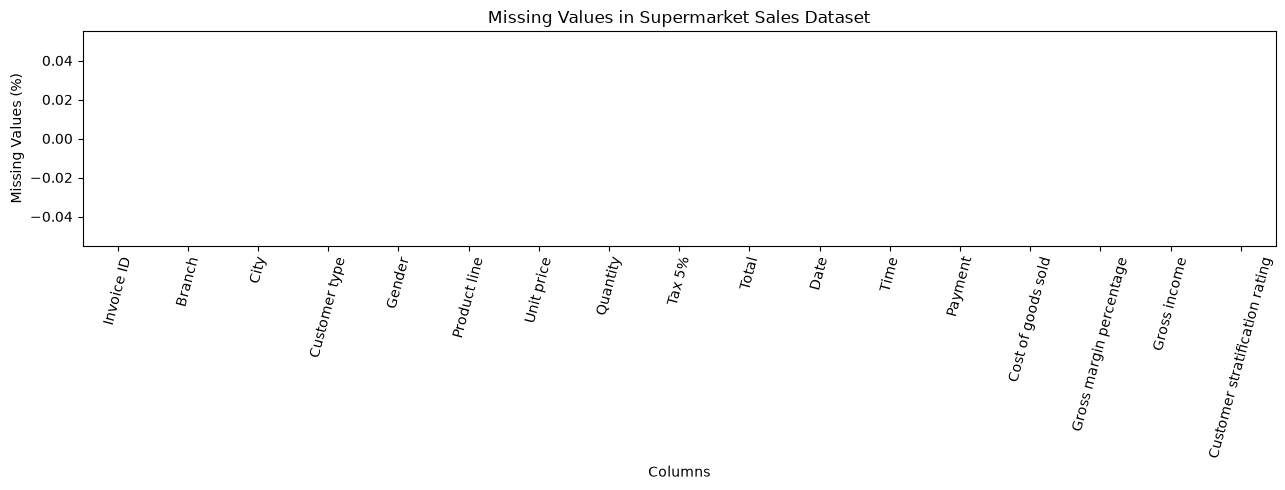

In [47]:
# Count missing values in each column

sales_missing = pd.DataFrame({
    "Missing Count": sales_df.isnull().sum(),
    "Missing Percentage": (
        sales_df.isnull().mean() * 100
    ).round(2)
})

display(sales_missing)

# Check total missing values
print(
    "Total Missing Values:",
    sales_df.isnull().sum().sum()
)

# Visualize missing values
plt.figure(figsize=(13, 5))

sns.barplot(
    x=sales_missing.index,
    y=sales_missing["Missing Percentage"]
)

plt.title("Missing Values in Supermarket Sales Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The missing-value check showed that all 17 columns contain complete information.

There are no missing values in the dataset.

This means no records need to be removed or filled because of missing information.

The result is useful because it allows me to work with the complete dataset without introducing estimated values.


In [ ]:

### B2.2 Duplicate Records

I checked for duplicate transactions because repeated records could cause sales totals and transaction counts to be calculated incorrectly.

I first checked for completely identical rows.

I then checked whether any Invoice IDs were repeated, since each transaction is expected to have its own identifier.


In [48]:

### B2.2 Duplicate Records

I checked for duplicate transactions because repeated records could cause sales totals and transaction counts to be calculated incorrectly.

I first checked for completely identical rows.

I then checked whether any Invoice IDs were repeated, since each transaction is expected to have its own identifier.


SyntaxError: invalid syntax (3977424634.py, line 3)

In [49]:
# Check duplicate rows

print(
    "Duplicate Rows:",
    sales_df.duplicated().sum()
)

# Check duplicate invoice identifiers

print(
    "Duplicate Invoice IDs:",
    sales_df["Invoice ID"].duplicated().sum()
)

# Display duplicates if any exist

duplicate_records = sales_df[
    sales_df.duplicated(keep=False)
]

display(duplicate_records)

Duplicate Rows: 0
Duplicate Invoice IDs: 0


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating


In [ ]:

### Interpretation

The duplicate checks returned zero duplicate rows and zero repeated Invoice IDs.

This indicates that each transaction is uniquely represented in the dataset according to these checks.

Since no duplicates were found, there is no need to remove any records for duplication.


In [ ]:

### B2.3 Data Type Inspection

I examined the data types to check whether each variable was stored in a suitable format.

The numerical columns should be stored as integers or floating-point values.

The Date and Time columns also need to be checked because they are required for analyzing sales patterns across months, weekdays, and hours.


In [50]:

### B2.3 Data Type Inspection

I examined the data types to check whether each variable was stored in a suitable format.

The numerical columns should be stored as integers or floating-point values.

The Date and Time columns also need to be checked because they are required for analyzing sales patterns across months, weekdays, and hours.


SyntaxError: invalid syntax (757128496.py, line 3)

In [51]:
# Display data types

print("Column Data Types:")
display(sales_df.dtypes.to_frame("Data Type"))

# Inspect dates and times

print("\nDate Samples:")
display(sales_df["Date"].head(10))

print("\nTime Samples:")
display(sales_df["Time"].head(10))

# Check numerical columns

numerical_columns = [
    "Unit price",
    "Quantity",
    "Tax 5%",
    "Total",
    "Cost of goods sold",
    "Gross margin percentage",
    "Gross income",
    "Customer stratification rating"
]

print("\nNumerical Column Data Types:")
display(sales_df[numerical_columns].dtypes)

Column Data Types:


,Data Type
Invoice ID,str
Branch,str
City,str
Customer type,str
Gender,str
Product line,str
Unit price,float64
Quantity,int64
Tax 5%,float64
Total,float64



Date Samples:


0     1/5/2019
1     3/8/2019
2     3/3/2019
3    1/27/2019
4     2/8/2019
5    3/25/2019
6    2/25/2019
7    2/24/2019
8    1/10/2019
9    2/20/2019
Name: Date, dtype: str


Time Samples:


0    13:08
1    10:29
2    13:23
3    20:33
4    10:37
5    18:30
6    14:36
7    11:38
8    17:15
9    13:27
Name: Time, dtype: str


Numerical Column Data Types:


Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Cost of goods sold                float64
Gross margin percentage           float64
Gross income                      float64
Customer stratification rating    float64
dtype: object

In [ ]:

### Interpretation

The main numerical columns are already stored using appropriate numerical data types.

For example, Quantity is stored as an integer, while Unit price, Total, Gross income, and Customer stratification rating are stored as floating-point values.

However, the Date and Time columns are initially stored as strings.

These will need to be converted into suitable datetime formats before analyzing monthly, daily, and hourly sales patterns.

The other column data types appear suitable for their intended purposes.


In [ ]:

### B2.4 Categorical Consistency

I checked the categorical columns for possible differences in spelling, capitalization, and whitespace.

Such inconsistencies can cause the same category to appear as multiple separate groups during analysis.

I examined Branch, City, Customer type, Gender, Product line, and Payment.

I also checked the relationship between Branch and City to see whether each branch was consistently associated with the same location.


In [52]:
# Columns containing categorical values

categorical_columns = [
    "Branch",
    "City",
    "Customer type",
    "Gender",
    "Product line",
    "Payment"
]

# Check categorical values and consistency

for column in categorical_columns:

    print(f"\nColumn: {column}")

    display(
        sales_df[column].value_counts(dropna=False)
    )

    values = sales_df[column].dropna().astype(str)

    whitespace_issues = (
        values != values.str.strip()
    ).sum()

    original_unique = values.nunique()

    normalized_unique = (
        values.str.strip()
        .str.casefold()
        .nunique()
    )

    print("Whitespace Issues:", whitespace_issues)
    print("Original Unique Categories:", original_unique)
    print("Normalized Unique Categories:", normalized_unique)


Column: Branch


Branch
A    340
B    332
C    328
Name: count, dtype: int64

Whitespace Issues: 0
Original Unique Categories: 3
Normalized Unique Categories: 3

Column: City


City
Yangon       340
Mandalay     332
Naypyitaw    328
Name: count, dtype: int64

Whitespace Issues: 0
Original Unique Categories: 3
Normalized Unique Categories: 3

Column: Customer type


...

Whitespace Issues: 0
Original Unique Categories: 2
Normalized Unique Categories: 2

Column: Product line


Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64

Whitespace Issues: 0
Original Unique Categories: 6
Normalized Unique Categories: 6

Column: Payment


Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64

Whitespace Issues: 0
Original Unique Categories: 3
Normalized Unique Categories: 3


In [53]:
# Check which cities belong to each branch

branch_city_table = pd.crosstab(
    sales_df["Branch"],
    sales_df["City"]
)

print("Branch and City Cross-tabulation:")
display(branch_city_table)

# Check number of unique cities per branch

city_per_branch = (
    sales_df.groupby("Branch")["City"].nunique()
)

print("\nUnique Cities per Branch:")
display(city_per_branch)

# Identify inconsistent branch-city relationships

inconsistent_branches = city_per_branch[
    city_per_branch > 1
]

print(
    "\nBranches Associated with Multiple Cities:",
    len(inconsistent_branches)
)

Branch and City Cross-tabulation:


City,Mandalay,Naypyitaw,Yangon
Branch,,,
A,0,0,340
B,332,0,0
C,0,328,0



Unique Cities per Branch:


Branch
A    1
B    1
C    1
Name: City, dtype: int64


Branches Associated with Multiple Cities: 0


In [ ]:

### Interpretation

The categorical consistency checks were used to identify possible differences in spelling, capitalization, and whitespace.

The dataset contains three branches, three cities, two customer types, two recorded gender categories, six product lines, and three payment methods.

The Branch and City relationship was also examined to determine whether the locations were recorded consistently.

If each branch is associated with only one city and the normalization checks do not reveal additional categories, no categorical correction is needed.

This is important because unnecessary changes to already consistent values would not improve the quality of the dataset.


In [ ]:

### B2.5 Suspicious and Invalid Numerical Values

I checked the numerical variables for values that would not make sense in a supermarket transaction.

For example, unit prices and quantities should be positive, and customer ratings should fall within the expected range.

I also checked for negative sales totals, tax amounts, and gross income values.

These checks help determine whether the numerical data contains obvious recording errors.


In [ ]:
# Examine numerical summary statistics

print("Numerical Summary Statistics:")
display(sales_df[numerical_columns].describe().round(2))

# Check invalid numerical values

invalid_checks = {
    "Non-positive Unit Prices":
        (sales_df["Unit price"] <= 0).sum(),

    "Non-positive Quantities":
        (sales_df["Quantity"] <= 0).sum(),

    "Negative Sales Totals":
        (sales_df["Total"] < 0).sum(),

    "Negative Tax Values":
        (sales_df["Tax 5%"] < 0).sum(),

    "Negative Gross Income":
        (sales_df["Gross income"] < 0).sum(),

    "Ratings Outside 0 to 10":
        (
            ~sales_df[
                "Customer stratification rating"
            ].between(0, 10)
        ).sum()
}

invalid_summary = pd.DataFrame(
    invalid_checks.items(),
    columns=["Check", "Invalid Records"]
)

display(invalid_summary)

In [ ]:

### Interpretation

The numerical checks did not identify any non-positive unit prices or quantities.

All customer ratings were within the expected range of 0 to 10.

The recorded unit prices range from 10.08 to 99.96, while transaction quantities range from 1 to 10 units.

Customer ratings range from 4.0 to 10.0.

These ranges appear reasonable for the variables being recorded.

The data does not appear to contain obvious invalid numerical entries based on the checks performed.


In [ ]:

### B2.6 Financial Consistency Checks

I examined whether the financial columns were consistent with the calculations used in the dataset.

The Cost of goods sold column should match Unit price multiplied by Quantity.

The Tax 5% column should represent five percent of the cost of goods sold, while Total should include both the original amount and tax.

I also checked whether Gross income matches the recorded tax amount.

These relationships are important because some financial variables may be calculated directly from others rather than providing independent information.


In [54]:
# Calculate expected financial values

expected_cogs = (
    sales_df["Unit price"] * sales_df["Quantity"]
)

expected_tax = expected_cogs * 0.05

expected_total = expected_cogs + expected_tax

# Use np.isclose for floating-point comparison

financial_checks = {
    "COGS Inconsistencies":
        (~np.isclose(
            sales_df["Cost of goods sold"],
            expected_cogs
        )).sum(),

    "Tax Inconsistencies":
        (~np.isclose(
            sales_df["Tax 5%"],
            expected_tax
        )).sum(),

    "Total Inconsistencies":
        (~np.isclose(
            sales_df["Total"],
            expected_total
        )).sum(),

    "Gross Income Inconsistencies":
        (~np.isclose(
            sales_df["Gross income"],
            sales_df["Tax 5%"]
        )).sum()
}

financial_summary = pd.DataFrame(
    financial_checks.items(),
    columns=["Financial Check", "Inconsistent Records"]
)

display(financial_summary)

# Check gross margin percentage

print("\nGross Margin Percentage Statistics:")
display(sales_df["Gross margin percentage"].describe())

print(
    "\nUnique Gross Margin Percentage Values:",
    sales_df["Gross margin percentage"].nunique()
)

,Financial Check,Inconsistent Records
0,COGS Inconsistencies,0
1,Tax Inconsistencies,0
2,Total Inconsistencies,0
3,Gross Income Inconsistencies,0



Gross Margin Percentage Statistics:


count    1000.000000
mean        4.761905
std         0.000000
min         4.761905
25%         4.761905
50%         4.761905
75%         4.761905
max         4.761905
Name: Gross margin percentage, dtype: float64


Unique Gross Margin Percentage Values: 1


In [ ]:

### Interpretation

The financial consistency checks returned zero inconsistencies for Cost of goods sold, Tax 5%, Total, and Gross income.

This confirms that the recorded values follow the expected financial calculations within numerical tolerance.

The Gross margin percentage column also contains a constant value of approximately 4.761905 across all transactions.

These findings show that several financial columns are mathematically related.

This relationship will be important during correlation analysis because the variables may show perfect correlations simply due to how they are calculated.

Such correlations should not be interpreted as independent relationships between different business factors.


In [ ]:

### B2.7 Outlier Detection

I used the Interquartile Range method to identify unusual values in Unit price, Quantity, Total, and Customer stratification rating.

The IQR is the difference between the third and first quartiles.

Values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR are treated as potential outliers.

I used box plots to visualize the distributions and identify observations that lie outside the usual range.

These values will not be removed automatically because large purchases or unusually high transaction totals may be valid.


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,Unit price,32.88,77.94,45.06,-34.72,145.52,0
1,Quantity,3.00,8.00,5.00,-4.50,15.50,0
2,Total,124.42,471.35,346.93,-395.97,991.74,9
3,Customer stratification rating,5.50,8.50,3.00,1.00,13.00,0


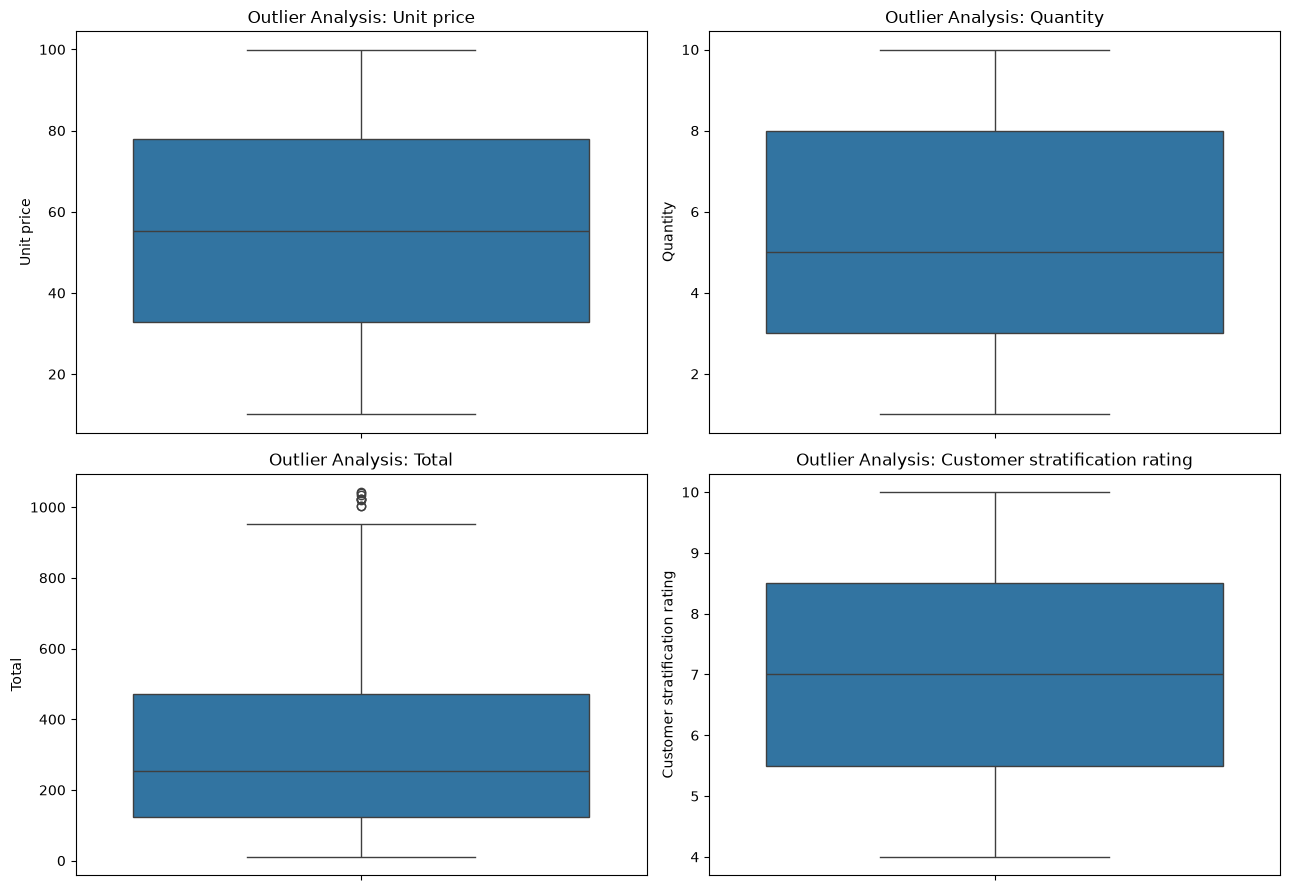

In [55]:
# Select numerical variables for outlier analysis

outlier_columns = [
    "Unit price",
    "Quantity",
    "Total",
    "Customer stratification rating"
]

outlier_results = []

for column in outlier_columns:

    Q1 = sales_df[column].quantile(0.25)
    Q3 = sales_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (sales_df[column] < lower_bound)
        | (sales_df[column] > upper_bound)
    ).sum()

    outlier_results.append([
        column,
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        outlier_count
    ])

outlier_summary = pd.DataFrame(
    outlier_results,
    columns=[
        "Variable",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Outlier Count"
    ]
)

display(outlier_summary.round(2))

# Box plots

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, column in zip(axes.flat, outlier_columns):

    sns.boxplot(
        data=sales_df,
        y=column,
        ax=ax
    )

    ax.set_title(f"Outlier Analysis: {column}")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The IQR method was used to examine unusual values in unit prices, quantities, transaction totals, and customer ratings.

The results help distinguish values that fall within the usual range from observations that are relatively extreme.

A large transaction total does not necessarily indicate an error because customers may purchase several products or more expensive items.

Similarly, a rating near the upper or lower end of the recorded range is not automatically invalid.

I will retain valid observations and only correct or remove values if there is evidence that they were recorded incorrectly.

This avoids changing the dataset simply to produce a more uniform distribution.


In [ ]:

### B2.8 Data Quality Summary

The data quality assessment showed that the Supermarket Sales dataset is generally well structured.

There were no missing values or duplicate transactions. The main numerical variables were stored using appropriate data types, although Date and Time require conversion.

The categorical variables were checked for inconsistent formatting, and the relationship between Branch and City was examined.

The numerical validation checks did not identify invalid prices, quantities, or customer ratings.

The financial consistency checks confirmed that Cost of goods sold, Tax 5%, Total, and Gross income follow the expected calculations.

Potential numerical outliers were examined separately and will be retained unless there is evidence that they are incorrect.

Overall, the dataset requires relatively little corrective cleaning. Most of the preprocessing will focus on date conversion and creating useful variables for further analysis.


In [ ]:

## B3. Data Cleaning and Preprocessing

After checking the quality of the Supermarket Sales dataset, I prepared it for further analysis.

The initial inspection showed that the dataset was already fairly clean, with no missing values or duplicate transactions.

Because of this, I did not remove any records or replace any values unnecessarily.

The main preprocessing steps involved converting the Date and Time columns into suitable formats and creating additional variables for analyzing sales across different months, weekdays, and hours.

I also checked that the changes did not affect the original records.


In [ ]:

### B3.1 Creating a Working Copy

I created a separate copy of the original dataset before making any changes.

This allows me to carry out preprocessing while keeping the original data unchanged.

It also makes it easier to compare the original and cleaned datasets if any problems are identified later.


In [56]:

### B3.1 Creating a Working Copy

I created a separate copy of the original dataset before making any changes.

This allows me to carry out preprocessing while keeping the original data unchanged.

It also makes it easier to compare the original and cleaned datasets if any problems are identified later.


SyntaxError: invalid syntax (245455494.py, line 3)

In [57]:
# Create a copy of the original dataset
sales_clean = sales_df.copy()

# Compare dataset dimensions
print("Original Dataset Shape:", sales_df.shape)
print("Working Copy Shape:", sales_clean.shape)

# Display sample records
display(sales_clean.head())

Original Dataset Shape: (1000, 17)
Working Copy Shape: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [58]:

### Interpretation

The working copy contains the same 1,000 records and 17 columns as the original dataset.

This confirms that no records or attributes were changed when the copy was created.

All further preprocessing will be carried out on sales_clean, while sales_df will remain unchanged.


SyntaxError: invalid syntax (204481524.py, line 3)

In [59]:

### B3.2 Date and Time Conversion

The Date and Time columns were originally stored as strings.

I converted Date into datetime format using the month/day/year format found in the dataset.

For Time, I converted the recorded values into Python time objects.

This makes it possible to extract useful information such as the month, weekday, and hour of each transaction.

I used explicit formats to avoid incorrectly interpreting the dates.


SyntaxError: invalid syntax (1379298106.py, line 3)

In [60]:
# Convert Date into datetime format
sales_clean["Date"] = pd.to_datetime(
    sales_clean["Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Convert Time into time objects
sales_clean["Time"] = pd.to_datetime(
    sales_clean["Time"],
    format="%H:%M",
    errors="coerce"
).dt.time

# Check conversions
print("Date Data Type:", sales_clean["Date"].dtype)
print("Time Example:", sales_clean["Time"].iloc[0])

print("\nConverted Date and Time:")
display(
    sales_clean[
        ["Invoice ID", "Date", "Time"]
    ].head(10)
)

# Check unsuccessful conversions
print(
    "\nMissing or Invalid Dates:",
    sales_clean["Date"].isna().sum()
)

print(
    "Missing or Invalid Times:",
    sales_clean["Time"].isna().sum()
)

Date Data Type: datetime64[us]
Time Example: 13:08:00

Converted Date and Time:


,Invoice ID,Date,Time
0,750-67-8428,2019-01-05,13:08:00
1,226-31-3081,2019-03-08,10:29:00
2,631-41-3108,2019-03-03,13:23:00
3,123-19-1176,2019-01-27,20:33:00
4,373-73-7910,2019-02-08,10:37:00
5,699-14-3026,2019-03-25,18:30:00
6,355-53-5943,2019-02-25,14:36:00
7,315-22-5665,2019-02-24,11:38:00
8,665-32-9167,2019-01-10,17:15:00
9,692-92-5582,2019-02-20,13:27:00



Missing or Invalid Dates: 0
Missing or Invalid Times: 0


In [61]:

### Interpretation

The Date column was converted into datetime format, while the Time column was converted into time objects.

This allows the original transaction dates and times to be used in later analysis.

The conversion also avoids attaching an artificial date to the recorded transaction times.

I checked for missing values after conversion to make sure that valid records had not been lost.

These conversions are useful for examining how supermarket sales vary during different periods.


SyntaxError: invalid syntax (2176283111.py, line 3)

In [ ]:

### Interpretation

The Date column was converted into datetime format, while the Time column was converted into time objects.

This allows the original transaction dates and times to be used in later analysis.

The conversion also avoids attaching an artificial date to the recorded transaction times.

I checked for missing values after conversion to make sure that valid records had not been lost.

These conversions are useful for examining how supermarket sales vary during different periods.


In [ ]:

### B3.3 Creating Month, Weekday and Hour Variables

I created additional variables from the transaction dates and times.

The Month variable identifies the month in which each transaction occurred.

The Weekday variable identifies the day of the week, while Hour represents the hour of the transaction.

These features will make it easier to examine monthly sales, compare weekday activity, and identify busy shopping hours.

I kept the original Date and Time columns so that the detailed transaction information would remain available.


In [62]:
# Extract month number
sales_clean["Month"] = sales_clean["Date"].dt.month

# Extract month name
sales_clean["Month_Name"] = sales_clean["Date"].dt.month_name()

# Extract weekday name
sales_clean["Weekday"] = sales_clean["Date"].dt.day_name()

# Extract hour from Time
sales_clean["Hour"] = sales_clean["Time"].apply(
    lambda t: t.hour if pd.notna(t) else np.nan
)

# Display derived variables
display(
    sales_clean[
        [
            "Invoice ID",
            "Date",
            "Time",
            "Month",
            "Month_Name",
            "Weekday",
            "Hour"
        ]
    ].head(10)
)

print("\nDataset Shape After Feature Creation:")
print(sales_clean.shape)

,Invoice ID,Date,Time,Month,Month_Name,Weekday,Hour
0,750-67-8428,2019-01-05,13:08:00,1,January,Saturday,13
1,226-31-3081,2019-03-08,10:29:00,3,March,Friday,10
2,631-41-3108,2019-03-03,13:23:00,3,March,Sunday,13
3,123-19-1176,2019-01-27,20:33:00,1,January,Sunday,20
4,373-73-7910,2019-02-08,10:37:00,2,February,Friday,10
5,699-14-3026,2019-03-25,18:30:00,3,March,Monday,18
6,355-53-5943,2019-02-25,14:36:00,2,February,Monday,14
7,315-22-5665,2019-02-24,11:38:00,2,February,Sunday,11
8,665-32-9167,2019-01-10,17:15:00,1,January,Thursday,17
9,692-92-5582,2019-02-20,13:27:00,2,February,Wednesday,13



Dataset Shape After Feature Creation:
(1000, 21)


In [ ]:

### Interpretation

Four additional variables were created from the original date and time information.

Month and Month_Name can be used to compare sales across January, February, and March.

Weekday allows transactions to be grouped by day of the week, while Hour can be used to identify periods with higher or lower sales activity.

The new variables provide information that was already present in the original dates and times, but in a format that is easier to analyze.

No original transaction information was removed during this process.


In [ ]:

### B3.4 Categorical Consistency

Before finalizing the cleaned dataset, I checked whether the categorical columns contained unnecessary whitespace or inconsistent capitalization.

I also checked whether each branch was associated with a single city.

I did not want to change category labels without evidence of an actual inconsistency.

If the categories are already consistent, they can be kept in their original form.


In [63]:
categorical_columns = [
    "Branch",
    "City",
    "Customer type",
    "Gender",
    "Product line",
    "Payment"
]

consistency_results = []

for column in categorical_columns:
    values = sales_clean[column].dropna().astype(str)

    whitespace_count = (
        values != values.str.strip()
    ).sum()

    original_unique = values.nunique()

    normalized_unique = (
        values.str.strip().str.casefold().nunique()
    )

    consistency_results.append([
        column,
        whitespace_count,
        original_unique,
        normalized_unique
    ])

consistency_table = pd.DataFrame(
    consistency_results,
    columns=[
        "Column",
        "Whitespace Issues",
        "Original Categories",
        "Normalized Categories"
    ]
)

display(consistency_table)

# Verify the Branch and City relationship
branch_city_check = pd.crosstab(
    sales_clean["Branch"],
    sales_clean["City"]
)

print("\nBranch and City Relationship:")
display(branch_city_check)

print("\nNumber of Cities per Branch:")
display(
    sales_clean.groupby("Branch")["City"].nunique()
)

,Column,Whitespace Issues,Original Categories,Normalized Categories
0,Branch,0,3,3
1,City,0,3,3
2,Customer type,0,2,2
3,Gender,0,2,2
4,Product line,0,6,6
5,Payment,0,3,3



Branch and City Relationship:


City,Mandalay,Naypyitaw,Yangon
Branch,,,
A,0,0,340
B,332,0,0
C,0,328,0



Number of Cities per Branch:


Branch
A    1
B    1
C    1
Name: City, dtype: int64

In [ ]:

### Interpretation

I checked the categorical variables before deciding whether any standardization was necessary.

The checks compared the original category counts with those obtained after removing extra spaces and ignoring differences in capitalization.

I also examined whether each branch was consistently associated with one city.

When categories are already consistent, keeping their original values avoids unnecessary modifications to the dataset.

The results of these checks are used to support the decision to retain the existing category labels.


In [ ]:

### B3.5 Handling Potential Outliers

The earlier data quality assessment used the IQR method to identify unusual numerical values.

However, an unusually large transaction does not necessarily indicate a data-entry error.

A customer may spend more because of a higher quantity purchased or more expensive products.

For this reason, I decided to retain the numerical observations unless there was evidence that they were invalid.

The outliers will remain available for analysis, and their possible influence will be considered when interpreting summary statistics.


In [64]:
# Recalculate outlier counts without modifying the data

columns_to_check = [
    "Unit price",
    "Quantity",
    "Total",
    "Customer stratification rating"
]

outlier_summary = []

for column in columns_to_check:

    Q1 = sales_clean[column].quantile(0.25)
    Q3 = sales_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (sales_clean[column] < lower_bound)
        | (sales_clean[column] > upper_bound)
    ).sum()

    outlier_summary.append([
        column,
        lower_bound,
        upper_bound,
        outlier_count
    ])

outlier_table = pd.DataFrame(
    outlier_summary,
    columns=[
        "Variable",
        "Lower Bound",
        "Upper Bound",
        "Potential Outliers"
    ]
)

display(outlier_table.round(2))

print("\nRecords Before Cleaning:", len(sales_df))
print("Records After Cleaning:", len(sales_clean))

,Variable,Lower Bound,Upper Bound,Potential Outliers
0,Unit price,-34.72,145.52,0
1,Quantity,-4.50,15.50,0
2,Total,-395.97,991.74,9
3,Customer stratification rating,1.00,13.00,0



Records Before Cleaning: 1000
Records After Cleaning: 1000


In [ ]:

### Interpretation

The outlier checks identified observations that fall outside the usual range according to the IQR method.

However, these values were retained because the earlier validation checks did not establish that they were incorrect.

Removing high-value transactions simply because they are unusual could affect the total revenue and average transaction value.

I therefore kept the original numerical values and will consider their effect when interpreting the distributions in the next section.

The dataset still contains all 1,000 transactions.


In [ ]:


### B3.6 Cleaning Decisions and Justifications

The following table summarizes the findings from the data quality assessment and the decisions made during preprocessing.

Since the dataset did not contain missing values, duplicate transactions, or obvious financial inconsistencies, many of the original values were retained.

The main changes involved converting dates and times and creating derived features for later analysis.



In [65]:
# Create the cleaning decision table

cleaning_decisions = [
    [
        "Missing values",
        "Checked null counts across all columns",
        "No changes required",
        "No missing values were found"
    ],
    [
        "Duplicate records",
        "Checked duplicate rows and Invoice IDs",
        "Retained all transactions",
        "No duplicate records were found"
    ],
    [
        "Date stored as text",
        "Inspected original data types",
        "Converted to datetime",
        "Required for date-based analysis"
    ],
    [
        "Time stored as text",
        "Inspected original data types",
        "Converted to time objects",
        "Required for hourly analysis"
    ],
    [
        "Categorical formatting",
        "Checked whitespace and category counts",
        "Retained consistent labels",
        "No unsupported changes were necessary"
    ],
    [
        "Branch and City relationship",
        "Checked branch-city cross-tabulation",
        "Retained original values",
        "Branch locations were checked for consistency"
    ],
    [
        "Financial calculations",
        "Recalculated tax, COGS and totals",
        "Retained original values",
        "No calculation inconsistencies were found"
    ],
    [
        "Potential numerical outliers",
        "Applied the IQR method",
        "Retained observations",
        "Unusual purchases may still be valid"
    ],
    [
        "Date and time analysis",
        "Identified useful temporal information",
        "Created four derived variables",
        "Supports monthly, weekday and hourly comparisons"
    ]
]

sales_cleaning_table = pd.DataFrame(
    cleaning_decisions,
    columns=[
        "Problem",
        "Detection",
        "Decision",
        "Justification"
    ]
)

display(sales_cleaning_table)

,Problem,Detection,Decision,Justification
0,Missing values,Checked null counts across all columns,No changes required,No missing values were found
1,Duplicate records,Checked duplicate rows and Invoice IDs,Retained all transactions,No duplicate records were found
2,Date stored as text,Inspected original data types,Converted to datetime,Required for date-based analysis
3,Time stored as text,Inspected original data types,Converted to time objects,Required for hourly analysis
4,Categorical formatting,Checked whitespace and category counts,Retained consistent labels,No unsupported changes were necessary
5,Branch and City relationship,Checked branch-city cross-tabulation,Retained original values,Branch locations were checked for consistency
6,Financial calculations,"Recalculated tax, COGS and totals",Retained original values,No calculation inconsistencies were found
7,Potential numerical outliers,Applied the IQR method,Retained observations,Unusual purchases may still be valid
8,Date and time analysis,Identified useful temporal information,Created four derived variables,"Supports monthly, weekday and hourly comparisons"


In [66]:
# Compare original and cleaned datasets

print("Original Dataset Shape:", sales_df.shape)
print("Cleaned Dataset Shape:", sales_clean.shape)

# Check missing values
print("\nMissing Values:")
display(sales_clean.isnull().sum())

# Check duplicates
print("\nDuplicate Rows:", sales_clean.duplicated().sum())

print(
    "Duplicate Invoice IDs:",
    sales_clean["Invoice ID"].duplicated().sum()
)

# Check data types
print("\nFinal Data Types:")
display(sales_clean.dtypes.to_frame("Data Type"))

# Ensure no original transactions were lost
assert len(sales_clean) == len(sales_df), (
    "The number of transactions has changed."
)

assert sales_clean["Invoice ID"].is_unique, (
    "Duplicate Invoice IDs were found."
)

assert sales_clean["Date"].notna().all(), (
    "Some dates could not be converted."
)

assert sales_clean["Time"].notna().all(), (
    "Some times could not be converted."
)

# Export cleaned dataset
sales_clean.to_csv(
    "23L_0977_A2_supermarket_cleaned.csv",
    index=False
)

print("\nCleaned Supermarket CSV exported successfully.")

Original Dataset Shape: (1000, 17)
Cleaned Dataset Shape: (1000, 21)

Missing Values:


Invoice ID                        0
Branch                            0
City                              0
Customer type                     0
Gender                            0
Product line                      0
Unit price                        0
Quantity                          0
Tax 5%                            0
Total                             0
Date                              0
Time                              0
Payment                           0
Cost of goods sold                0
Gross margin percentage           0
Gross income                      0
Customer stratification rating    0
Month                             0
Month_Name                        0
Weekday                           0
Hour                              0
dtype: int64


Duplicate Rows: 0
Duplicate Invoice IDs: 0

Final Data Types:


,Data Type
Invoice ID,str
Branch,str
City,str
Customer type,str
Gender,str
Product line,str
Unit price,float64
Quantity,int64
Tax 5%,float64
Total,float64



Cleaned Supermarket CSV exported successfully.


In [ ]:

### B3.8 Data Cleaning Summary

The original Supermarket Sales dataset contained 1,000 records and 17 columns.

The data quality assessment found no missing values, duplicate transactions, or inconsistencies in the main financial calculations.

The Date and Time columns were converted into suitable formats, and four additional variables were created to support temporal analysis.

I also checked the categorical values and the relationship between branches and cities.

Potential numerical outliers were retained because there was no clear evidence that they were incorrect.

No transactions were removed during cleaning.

The final dataset contains 1,000 records and 21 columns, including the four derived temporal variables.

The cleaned dataset was saved as a CSV file for use in Assignment 3.


In [ ]:

## B4. Univariate Exploratory Data Analysis

In this section, I examined individual variables to understand how supermarket transactions are distributed.

For numerical variables, I calculated the mean, median, standard deviation, quartiles, and skewness. I also used histograms and box plots to examine their distributions and identify unusual values.

For categorical variables, I used frequency tables and bar charts to compare the number of transactions in different groups.

The aim was to understand the characteristics of the dataset before examining relationships between variables.


In [ ]:

### B4.1 Unit Price Distribution

I started by examining the Unit price column to understand the prices of products recorded in the transactions.

I calculated descriptive statistics to identify the average price, median, spread, and minimum and maximum values.

I used a histogram to examine the overall distribution and a box plot to check for unusually low or high prices.


Unit Price Statistics:


count    1000.000000
mean       55.672130
std        26.494628
min        10.080000
25%        32.875000
50%        55.230000
75%        77.935000
max        99.960000
Name: Unit price, dtype: float64

Unit Price Skewness: 0.007


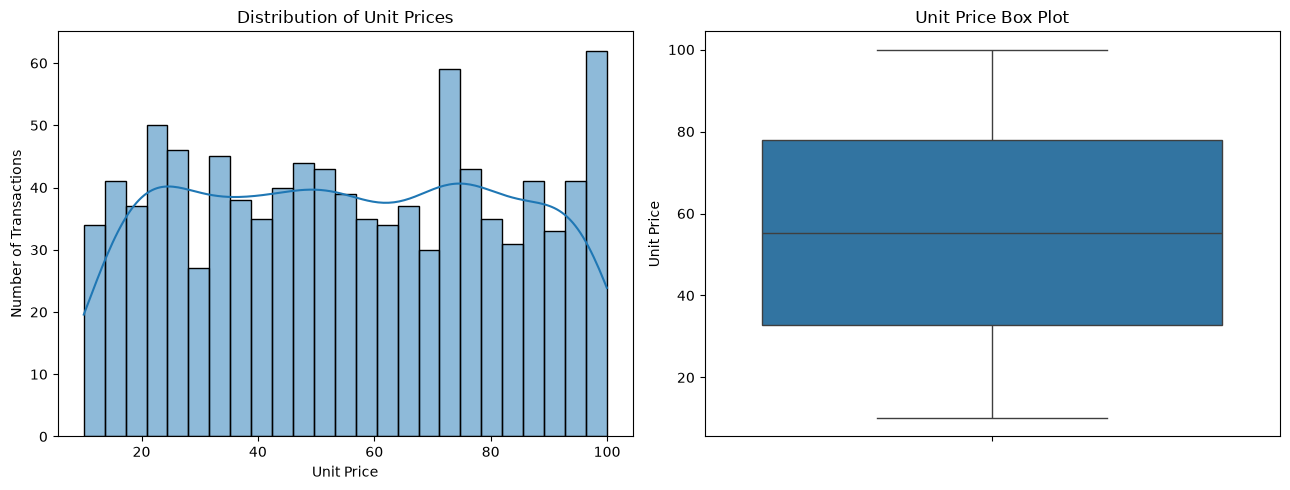

In [67]:
# Calculate unit price statistics

print("Unit Price Statistics:")
display(sales_clean["Unit price"].describe())

print(
    "Unit Price Skewness:",
    round(sales_clean["Unit price"].skew(), 3)
)

# Visualize the distribution

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=sales_clean,
    x="Unit price",
    bins=25,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Unit Prices")
axes[0].set_xlabel("Unit Price")
axes[0].set_ylabel("Number of Transactions")

sns.boxplot(
    data=sales_clean,
    y="Unit price",
    ax=axes[1]
)

axes[1].set_title("Unit Price Box Plot")
axes[1].set_ylabel("Unit Price")

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The average unit price is approximately 55.67, while the median is 55.23.

The minimum recorded unit price is 10.08, and the maximum is 99.96.

The first quartile is 32.88, while the third quartile is 77.94. This shows that the middle 50% of unit prices fall within this range.

The mean and median are very close, suggesting that the distribution is reasonably balanced around its centre.

The histogram and box plot help show how prices are spread across the recorded transactions.

There is no indication of invalid prices based on the earlier data quality checks.


In [ ]:

### B4.2 Quantity Distribution

Next, I examined the Quantity column to understand how many units were purchased in each transaction.

Since Quantity is a discrete numerical variable, I used a frequency table and count plot.

I also calculated descriptive statistics to understand the typical quantity purchased and how much it varies between transactions.


Quantity Statistics:


count    1000.000000
mean        5.510000
std         2.923431
min         1.000000
25%         3.000000
50%         5.000000
75%         8.000000
max        10.000000
Name: Quantity, dtype: float64

Quantity Skewness: 0.013

Quantity Frequencies:


Quantity
1     112
2      91
3      90
4     109
5     102
6      98
7     102
8      85
9      92
10    119
Name: count, dtype: int64

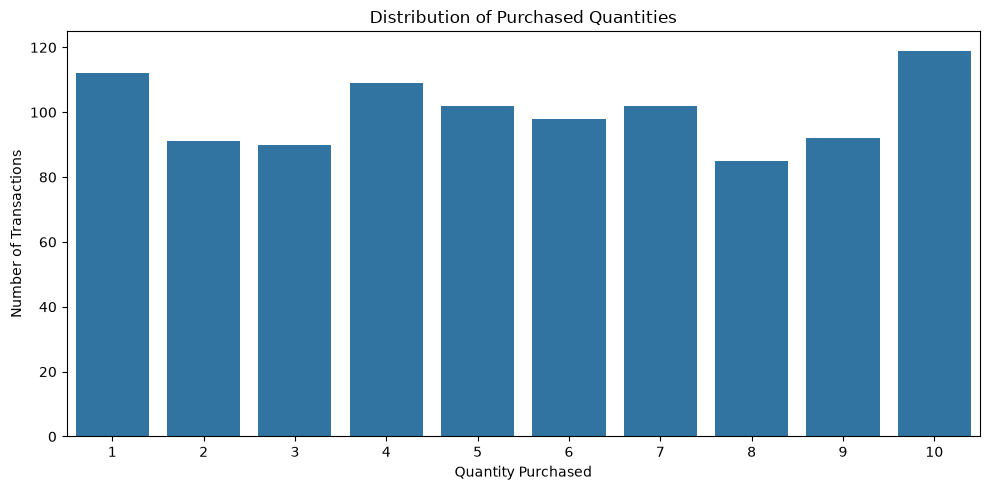

In [68]:
# Calculate quantity statistics

print("Quantity Statistics:")
display(sales_clean["Quantity"].describe())

print(
    "Quantity Skewness:",
    round(sales_clean["Quantity"].skew(), 3)
)

print("\nQuantity Frequencies:")
display(
    sales_clean["Quantity"]
    .value_counts()
    .sort_index()
)

# Visualize quantity distribution

plt.figure(figsize=(10, 5))

sns.countplot(
    data=sales_clean,
    x="Quantity"
)

plt.title("Distribution of Purchased Quantities")
plt.xlabel("Quantity Purchased")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The average quantity purchased per transaction is 5.51 units, while the median is 5 units.

The recorded quantities range from 1 to 10 units.

The first quartile is 3 units, and the third quartile is 8 units, showing that the middle 50% of transactions contain between 3 and 8 units.

The standard deviation is approximately 2.92 units, indicating variation in the number of units purchased.

The count plot makes it easier to compare the frequency of each quantity.

Since all quantities are positive and fall within the recorded range, there is no evidence of invalid quantity values.


In [ ]:

### B4.3 Total Transaction Value Distribution

I examined the Total column to understand how much customers spent per transaction.

This variable is important because it represents the transaction amount including tax.

I calculated descriptive statistics and skewness to understand the distribution.

I also used a histogram and box plot to identify whether a small number of high-value transactions affect the overall pattern.


Total Transaction Statistics:


count    1000.000000
mean      322.966749
std       245.885335
min        10.678500
25%       124.422375
50%       253.848000
75%       471.350250
max      1042.650000
Name: Total, dtype: float64

Total Transaction Skewness: 0.893

Lower Outlier Bound: -395.97
Upper Outlier Bound: 991.74
Potential Outliers: 9


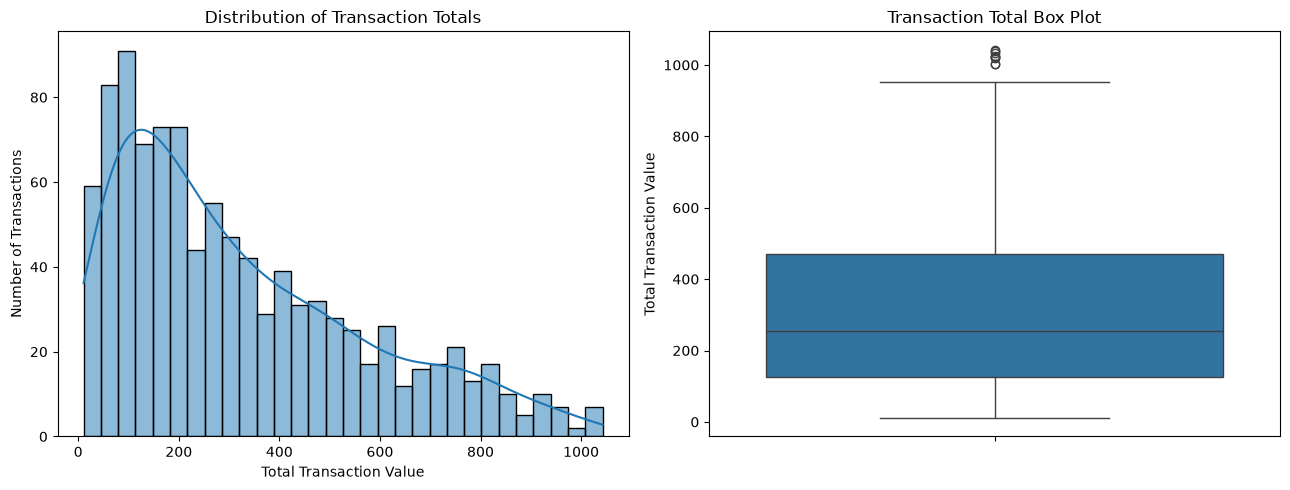

In [69]:
# Calculate transaction value statistics

print("Total Transaction Statistics:")
display(sales_clean["Total"].describe())

print(
    "Total Transaction Skewness:",
    round(sales_clean["Total"].skew(), 3)
)

# IQR outlier calculation

Q1 = sales_clean["Total"].quantile(0.25)
Q3 = sales_clean["Total"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

total_outliers = sales_clean[
    (sales_clean["Total"] < lower_bound)
    | (sales_clean["Total"] > upper_bound)
]

print("\nLower Outlier Bound:", round(lower_bound, 2))
print("Upper Outlier Bound:", round(upper_bound, 2))
print("Potential Outliers:", len(total_outliers))

# Visualize transaction values

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=sales_clean,
    x="Total",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Transaction Totals")
axes[0].set_xlabel("Total Transaction Value")
axes[0].set_ylabel("Number of Transactions")

sns.boxplot(
    data=sales_clean,
    y="Total",
    ax=axes[1]
)

axes[1].set_title("Transaction Total Box Plot")
axes[1].set_ylabel("Total Transaction Value")

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The average transaction value is approximately 322.97, while the median is 253.85.

The minimum transaction value is 10.68, and the maximum is 1,042.65.

The first and third quartiles are approximately 124.42 and 471.35.

The mean is noticeably higher than the median, suggesting that the distribution is positively skewed.

This means that relatively expensive transactions may be increasing the average.

The histogram and box plot help identify unusually high transaction values.

These observations should not be removed automatically because customers may spend more by purchasing larger quantities or more expensive products.


In [ ]:

### B4.4 Customer Rating Distribution

I examined Customer stratification rating to understand how customers rated their shopping experiences.

I calculated the mean, median, standard deviation, and skewness.

A histogram was used to examine how the ratings are distributed, while a box plot was used to identify unusually high or low ratings.


Customer Rating Statistics:


count    1000.00000
mean        6.97270
std         1.71858
min         4.00000
25%         5.50000
50%         7.00000
75%         8.50000
max        10.00000
Name: Customer stratification rating, dtype: float64

Customer Rating Skewness: 0.009


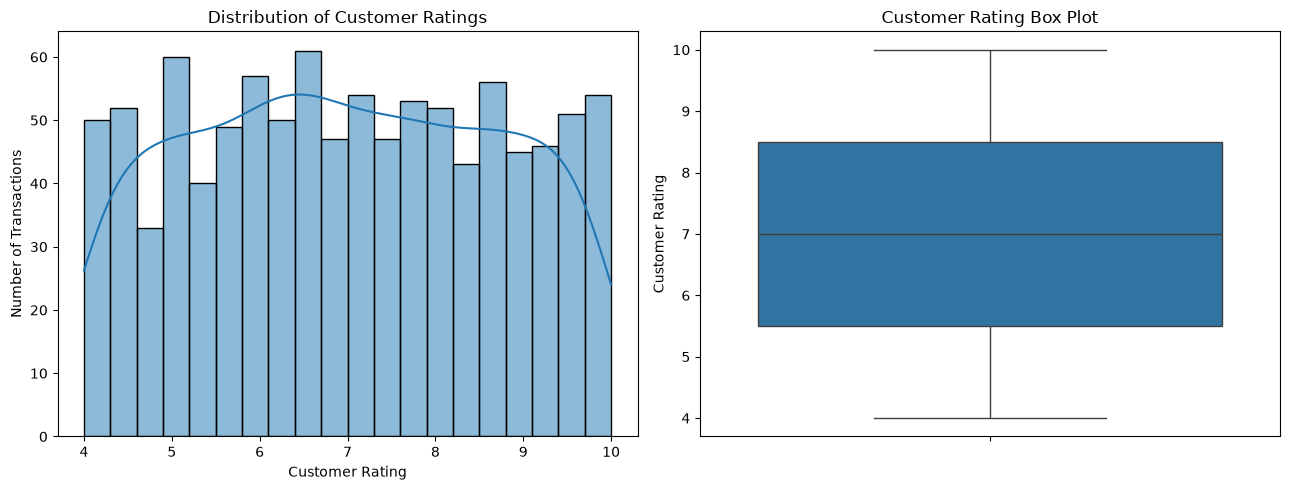

In [70]:
# Calculate customer rating statistics

rating_column = "Customer stratification rating"

print("Customer Rating Statistics:")
display(sales_clean[rating_column].describe())

print(
    "Customer Rating Skewness:",
    round(sales_clean[rating_column].skew(), 3)
)

# Visualize ratings

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=sales_clean,
    x=rating_column,
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Customer Ratings")
axes[0].set_xlabel("Customer Rating")
axes[0].set_ylabel("Number of Transactions")

sns.boxplot(
    data=sales_clean,
    y=rating_column,
    ax=axes[1]
)

axes[1].set_title("Customer Rating Box Plot")
axes[1].set_ylabel("Customer Rating")

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The average customer rating is approximately 6.97, while the median is 7.00.

Ratings range from 4.0 to 10.0, with a standard deviation of approximately 1.72.

The first quartile is 5.5, and the third quartile is 8.5.

The mean and median are almost identical, indicating that the central values of the distribution are similar.

The histogram helps show how frequently different ratings occur.

The ratings are within the expected range, and the earlier data quality assessment did not identify invalid values.

Further analysis will be needed to determine whether customer ratings differ across branches, products, or customer groups.


In [ ]:

### B4.5 Branch Distribution

I examined how the 1,000 transactions are distributed across the three supermarket branches.

Since Branch is a categorical variable, I used a frequency table and bar chart.

This helps determine whether the branches have similar numbers of recorded transactions.


,Transactions,Percentage
Branch,,
A,340,34.0
B,332,33.2
C,328,32.8


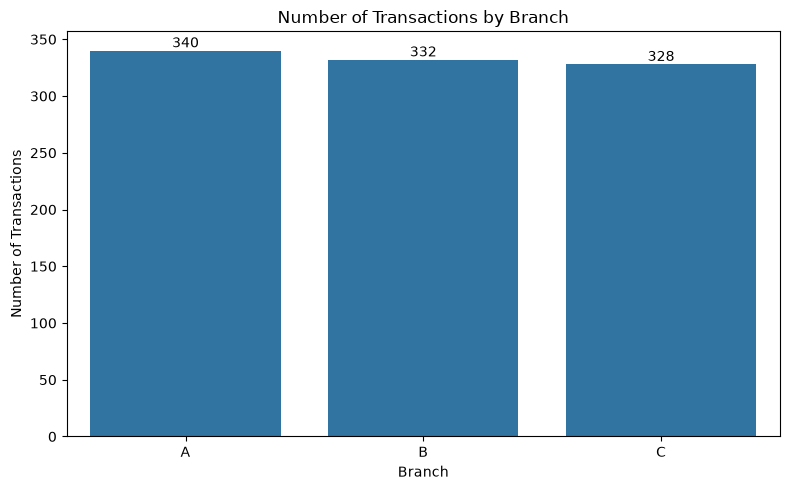

In [71]:
# Calculate branch frequencies

branch_counts = sales_clean["Branch"].value_counts()

branch_summary = pd.DataFrame({
    "Transactions": branch_counts,
    "Percentage": (
        branch_counts / len(sales_clean) * 100
    ).round(2)
})

display(branch_summary)

# Visualize branch distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=sales_clean,
    x="Branch",
    order=["A", "B", "C"]
)

plt.title("Number of Transactions by Branch")
plt.xlabel("Branch")
plt.ylabel("Number of Transactions")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

Branch A recorded the highest number of transactions, with 340 transactions.

Branch B recorded 332 transactions, while Branch C recorded 328.

The difference between the branches is relatively small.

This indicates that the dataset contains a fairly balanced number of transactions from all three branches.

However, transaction counts alone do not indicate which branch generated the highest revenue. This will be examined in the bivariate analysis.


In [ ]:

### B4.6 Product Line Distribution

I examined the Product line column to identify which product categories appear most frequently in the transaction records.

The dataset contains six product categories.

I used a frequency table and horizontal bar chart because these make it easier to compare categories with longer names.

This analysis focuses on transaction frequency rather than the revenue generated by each category.


,Transactions,Percentage
Product line,,
Fashion accessories,178,17.8
Food and beverages,174,17.4
Electronic accessories,170,17.0
Sports and travel,166,16.6
Home and lifestyle,160,16.0
Health and beauty,152,15.2


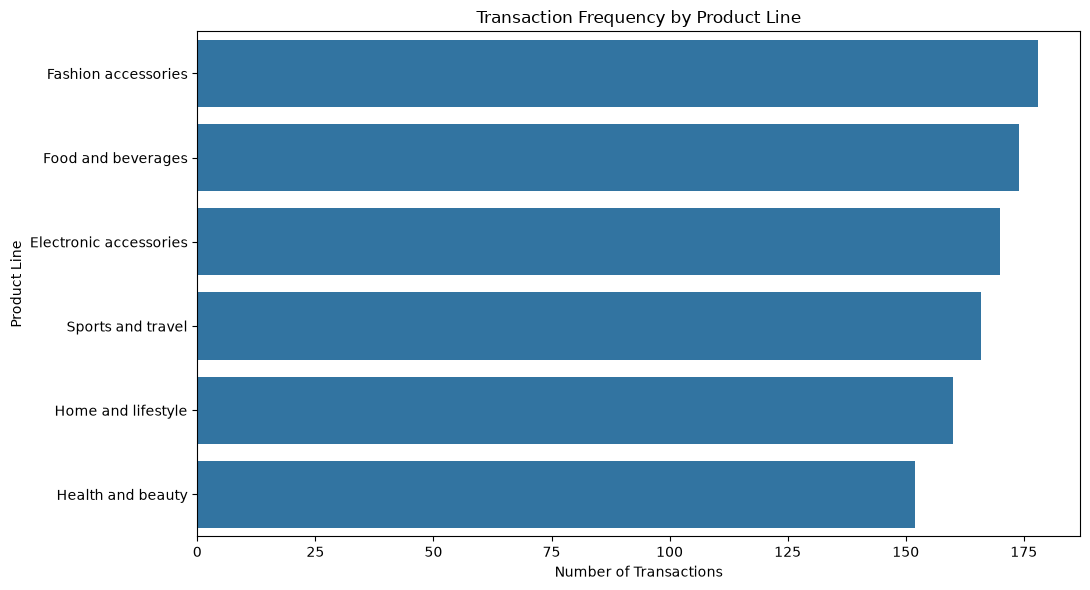

In [72]:
# Count transactions by product category

product_counts = (
    sales_clean["Product line"].value_counts()
)

product_summary = pd.DataFrame({
    "Transactions": product_counts,
    "Percentage": (
        product_counts / len(sales_clean) * 100
    ).round(2)
})

display(product_summary)

# Visualization

plt.figure(figsize=(11, 6))

sns.barplot(
    x=product_counts.values,
    y=product_counts.index
)

plt.title("Transaction Frequency by Product Line")
plt.xlabel("Number of Transactions")
plt.ylabel("Product Line")
plt.tight_layout()
plt.show()

In [ ]:

### B4.7 Customer Type Distribution

I compared the number of transactions recorded for Member and Normal customers.

Since Customer type is categorical, I used a frequency table and count plot.

This helps determine whether one customer group is more heavily represented in the dataset.


,Transactions,Percentage
Customer type,,
Member,501,50.1
Normal,499,49.9


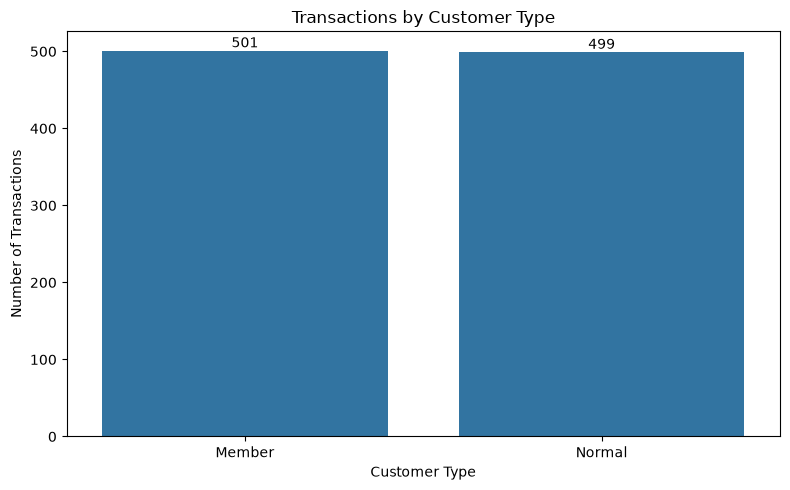

In [73]:
# Calculate customer type frequencies

customer_counts = (
    sales_clean["Customer type"].value_counts()
)

customer_summary = pd.DataFrame({
    "Transactions": customer_counts,
    "Percentage": (
        customer_counts / len(sales_clean) * 100
    ).round(2)
})

display(customer_summary)

# Count plot

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=sales_clean,
    x="Customer type"
)

plt.title("Transactions by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Transactions")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The dataset contains 501 transactions from Member customers and 499 transactions from Normal customers.

Members account for 50.1% of transactions, while Normal customers account for 49.9%.

The difference is very small, indicating that both groups are almost equally represented.

This provides a useful basis for comparing their spending behaviour later because the two groups have similar numbers of transactions.


In [ ]:

### B4.8 Payment Method Distribution

I examined the Payment column to identify the payment methods most frequently used by customers.

The dataset contains three methods: Cash, Credit card, and Ewallet.

I used a frequency table and bar chart to compare how often each method was used.

This provides an overview of payment preferences within the recorded transactions.


,Transactions,Percentage
Payment,,
Ewallet,345,34.5
Cash,344,34.4
Credit card,311,31.1


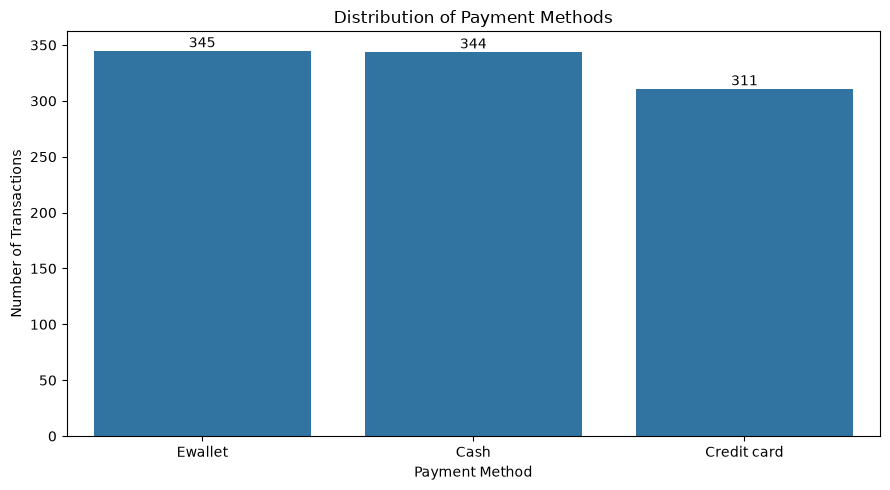

In [74]:
# Calculate payment method frequencies

payment_counts = sales_clean["Payment"].value_counts()

payment_summary = pd.DataFrame({
    "Transactions": payment_counts,
    "Percentage": (
        payment_counts / len(sales_clean) * 100
    ).round(2)
})

display(payment_summary)

# Visualization

plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=sales_clean,
    x="Payment",
    order=payment_counts.index
)

plt.title("Distribution of Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

Ewallet is the most frequently used payment method, appearing in 345 transactions.

Cash is almost equally common, with 344 transactions.

Credit card payments account for 311 transactions.

The distribution is fairly balanced, although Credit card is used slightly less frequently.

The differences in payment frequency do not necessarily mean that the same methods generate the highest revenue.

The relationship between payment method and transaction value will be examined during bivariate analysis.


In [ ]:

### B4 Summary

The univariate analysis helped me understand the distributions of the main numerical and categorical variables.

The average unit price is approximately 55.67, while the average quantity purchased is 5.51 units.

The average transaction value is 322.97, although the higher mean compared with the median suggests a positively skewed distribution.

Customer ratings have an average of approximately 6.97.

The categorical analysis showed that transactions are distributed fairly evenly across the three branches and between Member and Normal customers.

Fashion accessories is the most frequently recorded product category, while Ewallet is the most commonly used payment method.

These results provide a starting point for examining relationships between sales, customer characteristics, product categories, and branches.


In [ ]:

## B5. Bivariate Exploratory Data Analysis

In this section, I examined relationships between pairs of variables in the Supermarket Sales dataset.

I wanted to understand whether factors such as quantity, product category, branch, and customer type are associated with differences in sales.

I used correlation analysis for numerical variables, box plots and grouped summaries for numerical and categorical comparisons, and cross-tabulations for categorical variables.

I also considered whether any relationships were caused by the way certain columns were calculated rather than reflecting an independent pattern in the data.


In [ ]:

### B5.1 Relationship Between Quantity and Total Sales

I first examined whether transactions involving larger quantities also tend to have higher total values.

The two variables used are Quantity and Total.

I used Pearson's correlation coefficient to measure the strength and direction of their linear relationship.

I also used a scatter plot to see how transaction totals vary with the number of units purchased.

Since Total is calculated using both unit price and quantity, I expect these variables to be related. However, quantity alone does not determine the final transaction value.


Pearson Correlation (Quantity vs Total): 0.7055


,count,mean,median,std
Quantity,,,,
1,112,57.52,55.72,28.07
2,91,120.82,125.52,57.01
3,90,178.69,170.05,82.05
4,109,231.63,233.10,102.78
5,102,265.21,247.04,143.86
6,98,351.58,347.26,167.63
7,102,428.08,431.08,187.53
8,85,474.31,486.44,236.80
9,92,530.25,516.82,261.63


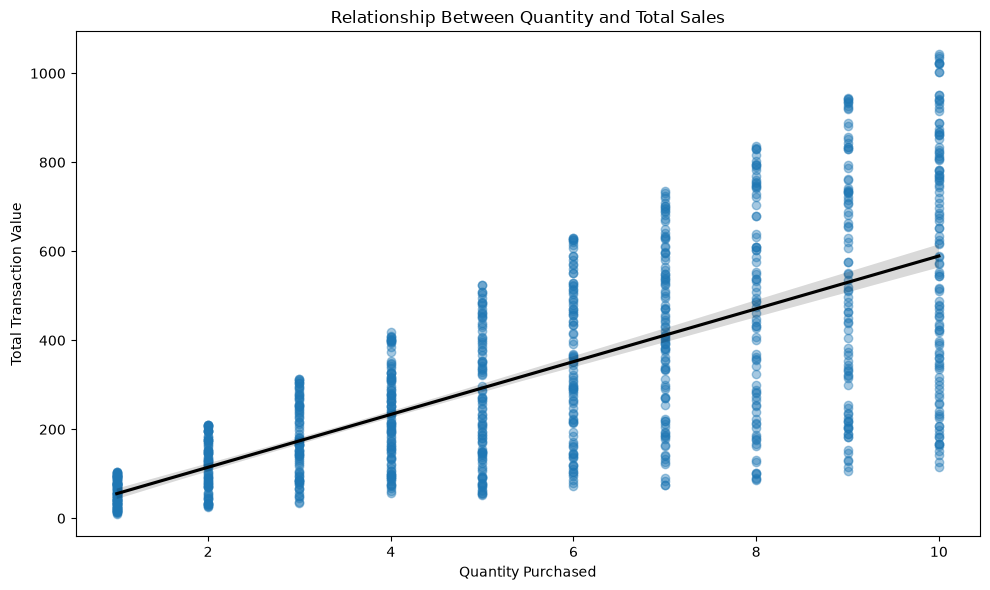

In [75]:
# Calculate Pearson correlation
quantity_total_corr = sales_clean["Quantity"].corr(
    sales_clean["Total"],
    method="pearson"
)

print(
    "Pearson Correlation (Quantity vs Total):",
    round(quantity_total_corr, 4)
)

# Calculate mean sales for each quantity
quantity_summary = (
    sales_clean.groupby("Quantity")["Total"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(quantity_summary)

# Scatter plot
plt.figure(figsize=(10, 6))

sns.regplot(
    data=sales_clean,
    x="Quantity",
    y="Total",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "black"}
)

plt.title("Relationship Between Quantity and Total Sales")
plt.xlabel("Quantity Purchased")
plt.ylabel("Total Transaction Value")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The Pearson correlation coefficient between Quantity and Total is approximately 0.7055.

This indicates a fairly strong positive linear relationship between the two variables.

Transactions involving more units generally tend to have higher total values.

However, the scatter plot also shows variation in total values for transactions with the same quantity. This happens because products have different unit prices.

The relationship is partly mathematical because Total is calculated using Quantity and Unit price.

Therefore, the positive correlation should not be interpreted as evidence that purchasing more units independently causes higher spending.


In [ ]:

### B5.2 Comparison of Transaction Values Across Branches

I examined whether the average transaction value differs between supermarket branches.

The variables used are Branch, which is categorical, and Total, which is numerical.

I calculated the mean, median, and standard deviation of transaction values for each branch.

I also used a box plot to compare their distributions.

A box plot is suitable because it shows how the transaction values vary within each branch rather than focusing only on total revenue.


Sales Statistics by Branch:


,,count,sum,mean,median,std,min,max
Branch,City,,,,,,,
A,Yangon,340,106200.37,312.35,240.83,231.64,12.69,1039.29
B,Mandalay,332,106197.67,319.87,252.88,242.45,18.64,1022.49
C,Naypyitaw,328,110568.71,337.10,271.42,263.16,10.68,1042.65


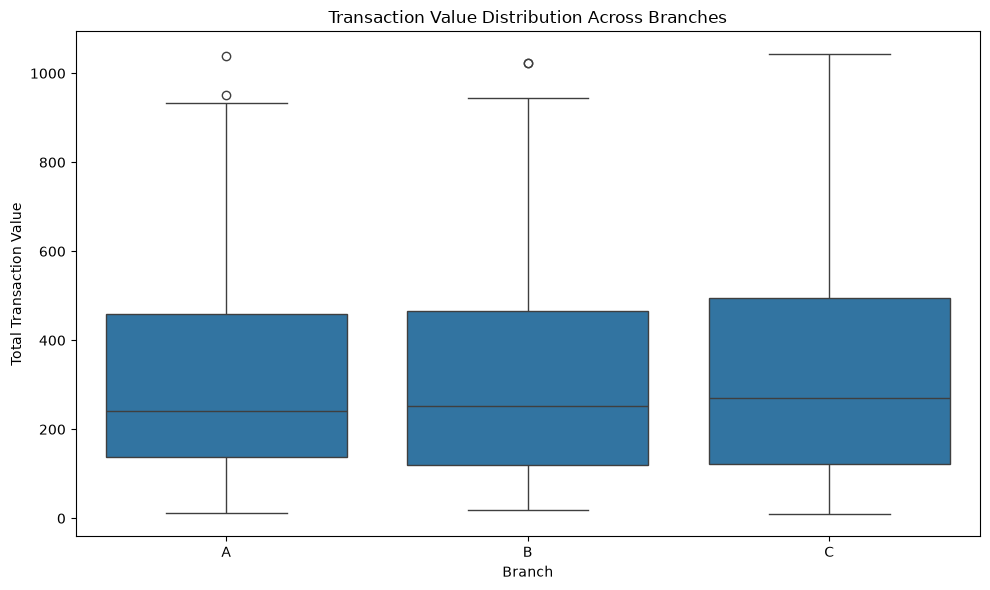

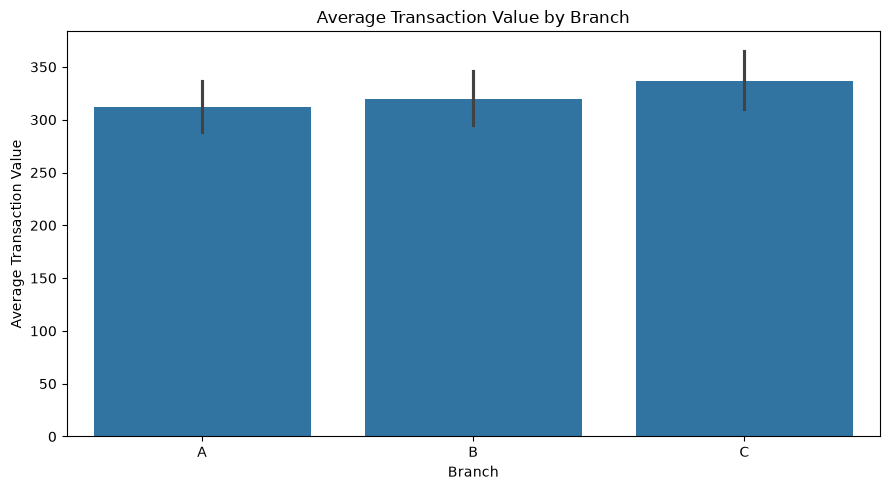

In [76]:
# Calculate transaction statistics for each branch

branch_sales_summary = (
    sales_clean.groupby(["Branch", "City"])["Total"]
    .agg([
        "count",
        "sum",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

print("Sales Statistics by Branch:")
display(branch_sales_summary)

# Box plot
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=sales_clean,
    x="Branch",
    y="Total",
    order=["A", "B", "C"]
)

plt.title("Transaction Value Distribution Across Branches")
plt.xlabel("Branch")
plt.ylabel("Total Transaction Value")
plt.tight_layout()
plt.show()

# Compare average transaction values
plt.figure(figsize=(9, 5))

sns.barplot(
    data=sales_clean,
    x="Branch",
    y="Total",
    order=["A", "B", "C"],
    errorbar=("ci", 95)
)

plt.title("Average Transaction Value by Branch")
plt.xlabel("Branch")
plt.ylabel("Average Transaction Value")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

Branch C in Naypyitaw recorded the highest average transaction value of approximately 337.10.

Branch B in Mandalay had an average transaction value of 319.87, while Branch A in Yangon recorded 312.35.

Although Branch C had the highest average, the differences between the branches were relatively small compared with the variation in transaction values.

The box plots help show whether the distributions overlap and whether some branches contain more unusually large transactions.

This suggests that Branch C performed slightly better in terms of average transaction value, but the descriptive results alone do not establish a statistically significant difference.

Further statistical testing would be needed to determine whether the observed differences are unlikely to be due to sampling variation.


In [ ]:

### B5.3 Sales Performance Across Product Lines

I examined whether transaction values differ between product categories.

I calculated total revenue, average transaction value, transaction count, and average customer rating for each product line.

Total revenue shows which categories contribute the most to overall sales, while average transaction value helps compare spending per transaction.

I used horizontal bar charts because product category names are relatively long.


Product Line Sales Summary:


,Product line,Transactions,Total_Revenue,Average_Transaction,Quantity_Sold,Average_Rating
2,Food and beverages,174,56144.84,322.67,952,7.11
5,Sports and travel,166,55122.83,332.07,920,6.92
0,Electronic accessories,170,54337.53,319.63,971,6.92
1,Fashion accessories,178,54305.90,305.09,902,7.03
4,Home and lifestyle,160,53861.91,336.64,911,6.84
3,Health and beauty,152,49193.74,323.64,854,7.00


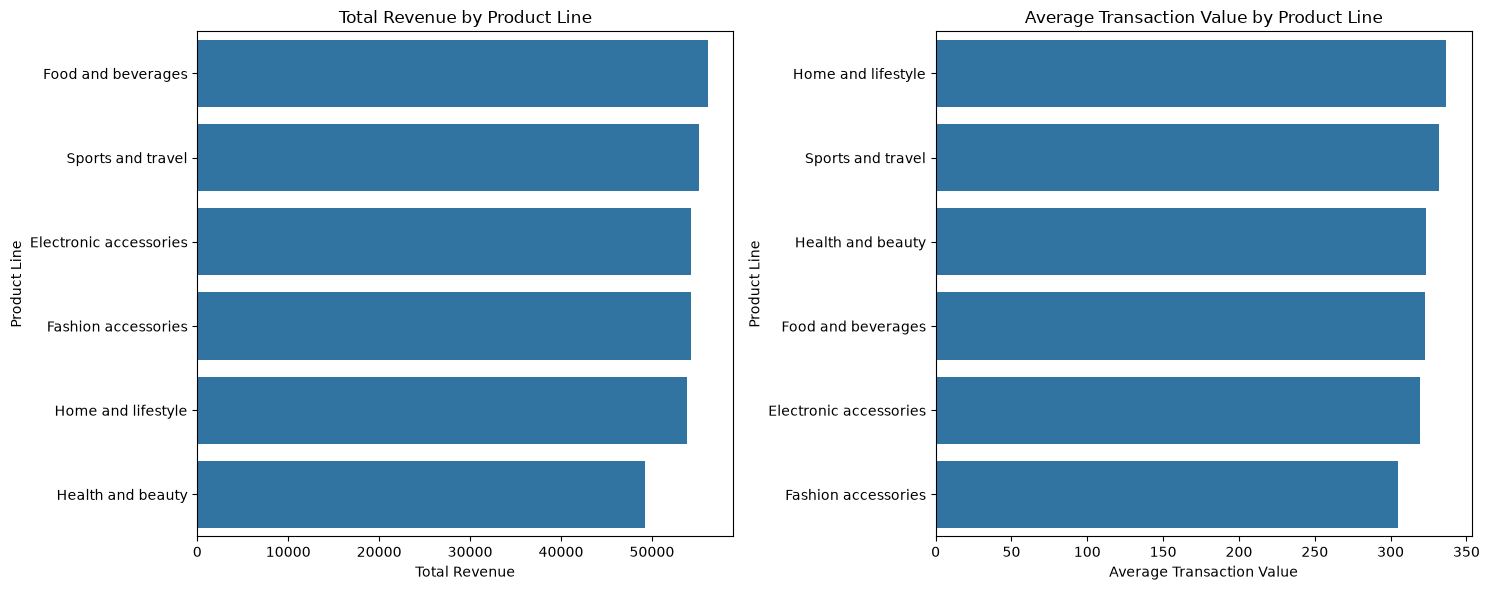


Comparison of Product Line Rankings:


,Product line,Total_Revenue,Average_Transaction,Revenue_Rank,Average_Value_Rank
2,Food and beverages,56144.84,322.67,1,4
5,Sports and travel,55122.83,332.07,2,2
0,Electronic accessories,54337.53,319.63,3,5
1,Fashion accessories,54305.90,305.09,4,6
4,Home and lifestyle,53861.91,336.64,5,1
3,Health and beauty,49193.74,323.64,6,3


In [77]:
# Calculate product-line statistics

product_sales_summary = (
    sales_clean.groupby("Product line")
    .agg(
        Transactions=("Invoice ID", "count"),
        Total_Revenue=("Total", "sum"),
        Average_Transaction=("Total", "mean"),
        Quantity_Sold=("Quantity", "sum"),
        Average_Rating=(
            "Customer stratification rating", "mean"
        )
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

print("Product Line Sales Summary:")
display(product_sales_summary.round(2))

# Compare product revenue and average transaction value

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=product_sales_summary,
    x="Total_Revenue",
    y="Product line",
    ax=axes[0]
)

axes[0].set_title("Total Revenue by Product Line")
axes[0].set_xlabel("Total Revenue")
axes[0].set_ylabel("Product Line")

sns.barplot(
    data=product_sales_summary.sort_values(
        "Average_Transaction", ascending=False
    ),
    x="Average_Transaction",
    y="Product line",
    ax=axes[1]
)

axes[1].set_title("Average Transaction Value by Product Line")
axes[1].set_xlabel("Average Transaction Value")
axes[1].set_ylabel("Product Line")

plt.tight_layout()
plt.show()

# Rank product lines using both measurements

product_sales_summary["Revenue_Rank"] = (
    product_sales_summary["Total_Revenue"]
    .rank(ascending=False, method="min")
    .astype(int)
)

product_sales_summary["Average_Value_Rank"] = (
    product_sales_summary["Average_Transaction"]
    .rank(ascending=False, method="min")
    .astype(int)
)

print("\nComparison of Product Line Rankings:")
display(
    product_sales_summary[
        [
            "Product line",
            "Total_Revenue",
            "Average_Transaction",
            "Revenue_Rank",
            "Average_Value_Rank"
        ]
    ].sort_values("Revenue_Rank").round(2)
)

In [78]:

### Interpretation

Food and beverages generated the highest total revenue of approximately 56,144.84.

Sports and travel ranked second with 55,122.83, followed by Electronic accessories with 54,337.53.

Health and beauty generated the lowest total revenue, at approximately 49,193.74.

However, total revenue depends on both the number of transactions and the amount spent in each transaction.

Comparing average transaction values provides another way of evaluating product-line performance.

A category with fewer transactions may still have a high average transaction value.

The ranking comparison helps identify whether the categories generating the most revenue are also the categories where customers spend the most per transaction.


SyntaxError: invalid syntax (2115560372.py, line 3)

In [ ]:

### B5.4 Relationship Between Customer Type and Payment Method

I examined whether Member and Normal customers use different payment methods.

Both Customer type and Payment are categorical variables, so I used a contingency table to compare their frequencies.

I also calculated percentages within each customer group.

A grouped bar chart was used to make the differences easier to compare.

This analysis helps determine whether payment preferences vary between the two customer types.


Customer Type vs Payment Method:


Payment,Cash,Credit card,Ewallet
Customer type,,,
Member,168,172,161
Normal,176,139,184



Payment Method Percentages by Customer Type:


Payment,Cash,Credit card,Ewallet
Customer type,,,
Member,33.53,34.33,32.14
Normal,35.27,27.86,36.87


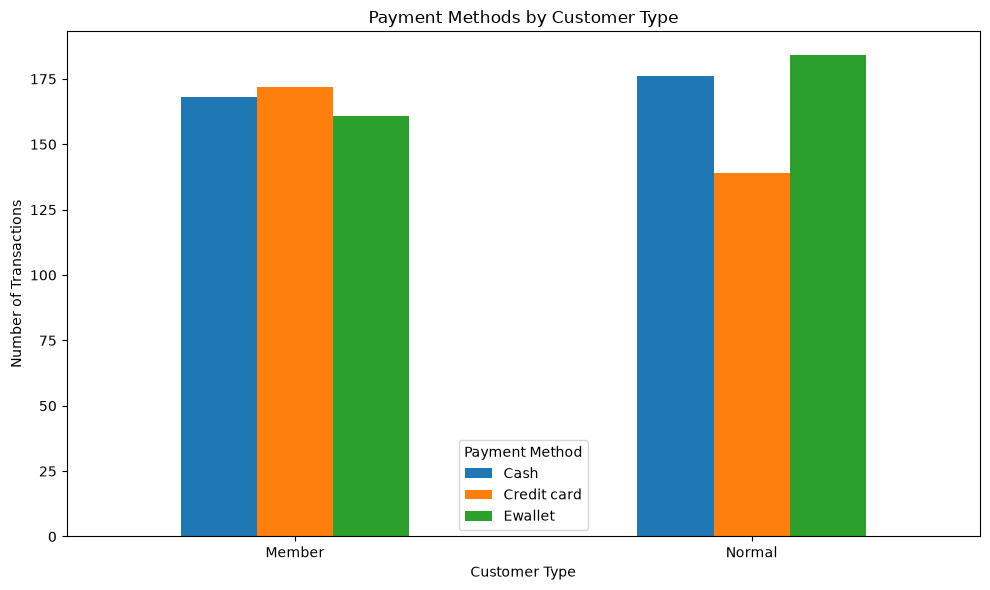

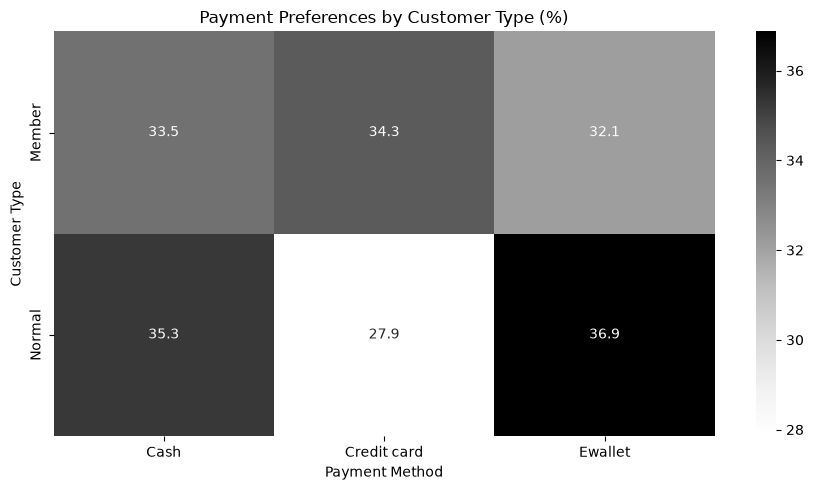

In [79]:
# Create contingency table

customer_payment_table = pd.crosstab(
    sales_clean["Customer type"],
    sales_clean["Payment"]
)

print("Customer Type vs Payment Method:")
display(customer_payment_table)

# Calculate percentages within customer type

customer_payment_percent = pd.crosstab(
    sales_clean["Customer type"],
    sales_clean["Payment"],
    normalize="index"
) * 100

print("\nPayment Method Percentages by Customer Type:")
display(customer_payment_percent.round(2))

# Grouped bar chart

customer_payment_table.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Payment Methods by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(title="Payment Method")
plt.tight_layout()
plt.show()

# Heatmap of percentages

plt.figure(figsize=(9, 5))

sns.heatmap(
    customer_payment_percent,
    annot=True,
    fmt=".1f",
    cmap="Greys"
)

plt.title("Payment Preferences by Customer Type (%)")
plt.xlabel("Payment Method")
plt.ylabel("Customer Type")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The contingency table compares the payment methods used by Member and Normal customers.

The percentages make the comparison fair because they are calculated separately for each customer type.

The analysis helps identify whether one group uses Cash, Credit card, or Ewallet more frequently than the other.

However, differences in the observed percentages do not necessarily establish a strong relationship between customer type and payment preference.

A statistical test such as the Chi-square test could be used to investigate whether the variables are associated.

The comparison describes the payment methods recorded in the dataset and does not explain the reasons behind customer preferences.


In [ ]:

### B5.5 Relationship Between Customer Ratings and Sales

I also examined whether customers who spent more tended to give higher ratings.

The variables used are Total and Customer stratification rating.

I calculated Pearson's correlation coefficient and used a scatter plot to examine their relationship.

This helps determine whether transaction value is associated with the recorded customer rating.


Pearson Correlation (Total vs Rating): -0.0364


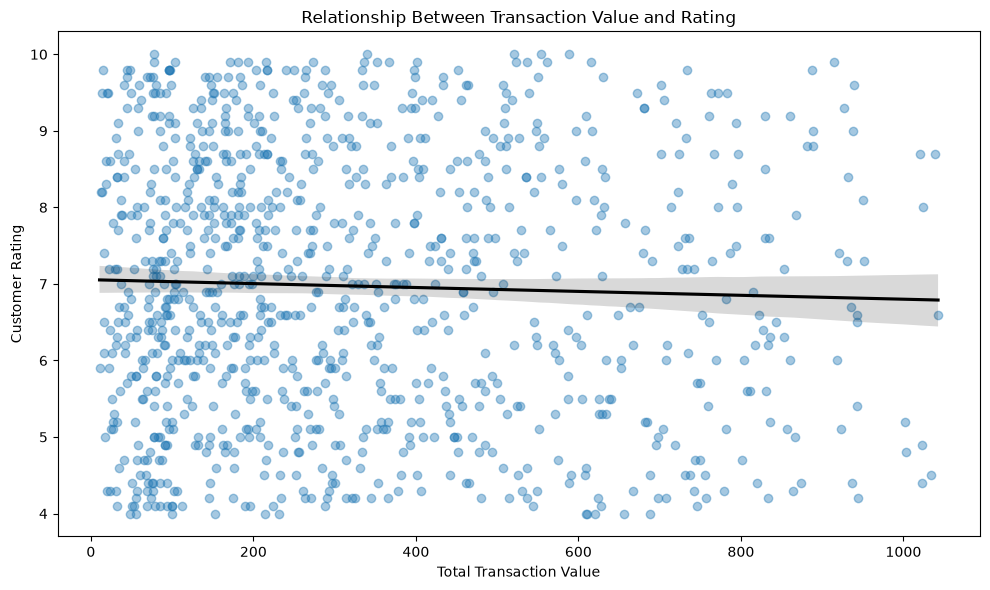

In [80]:
# Calculate correlation between transaction total and rating

rating_sales_corr = sales_clean["Total"].corr(
    sales_clean["Customer stratification rating"],
    method="pearson"
)

print(
    "Pearson Correlation (Total vs Rating):",
    round(rating_sales_corr, 4)
)

# Scatter plot

plt.figure(figsize=(10, 6))

sns.regplot(
    data=sales_clean,
    x="Total",
    y="Customer stratification rating",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "black"}
)

plt.title("Relationship Between Transaction Value and Rating")
plt.xlabel("Total Transaction Value")
plt.ylabel("Customer Rating")
plt.tight_layout()
plt.show()

In [ ]:

### Interpretation

The Pearson correlation between Total and Customer stratification rating is approximately -0.036.

This indicates a negligible negative linear relationship between transaction value and customer rating.

The scatter plot does not suggest a clear pattern in which customers consistently give higher or lower ratings as spending increases.

This means that transaction value alone does not appear to be strongly associated with customer ratings in the available dataset.

However, a weak correlation does not mean that all customers have identical experiences or that other factors are unimportant.

Additional variables, such as product category and branch, may provide further insight into differences in customer ratings.


In [ ]:

### B5 Summary

The bivariate analysis helped me examine relationships between numerical and categorical variables in the Supermarket Sales dataset.

Quantity and Total showed a positive correlation of approximately 0.7055, although this relationship is partly explained by the formula used to calculate transaction totals.

Branch C had the highest average transaction value, while Food and beverages generated the highest total revenue among product categories.

The product-line comparison also showed why total revenue and average transaction value should be considered separately.

I examined payment methods across Member and Normal customers to understand possible differences in payment preferences.

Finally, the relationship between customer rating and transaction value was negligible, with a Pearson correlation of approximately -0.036.

These findings provide a useful starting point for multivariate analysis, where additional variables can be considered together.



B6.1 - Branch, Product Line and Revenue


,Branch,Product line,Transactions,Revenue,Average_Transaction
0,A,Electronic accessories,60,18317.11,305.29
1,A,Fashion accessories,51,16332.51,320.25
2,A,Food and beverages,58,17163.10,295.92
3,A,Health and beauty,47,12597.75,268.04
4,A,Home and lifestyle,65,22417.20,344.88
5,A,Sports and travel,59,19372.70,328.35
6,B,Electronic accessories,55,17051.44,310.03
7,B,Fashion accessories,62,16413.32,264.73
8,B,Food and beverages,50,15214.89,304.30
9,B,Health and beauty,53,19980.66,376.99


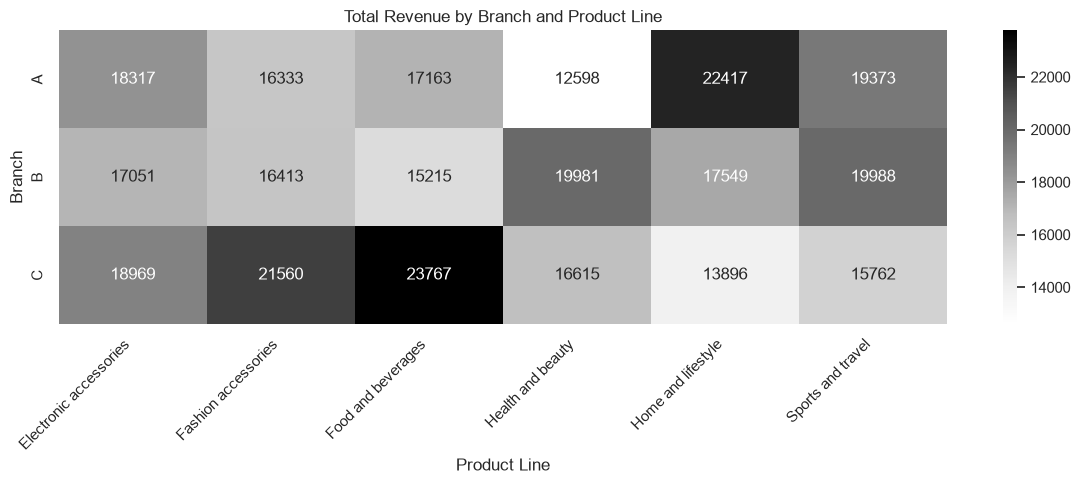

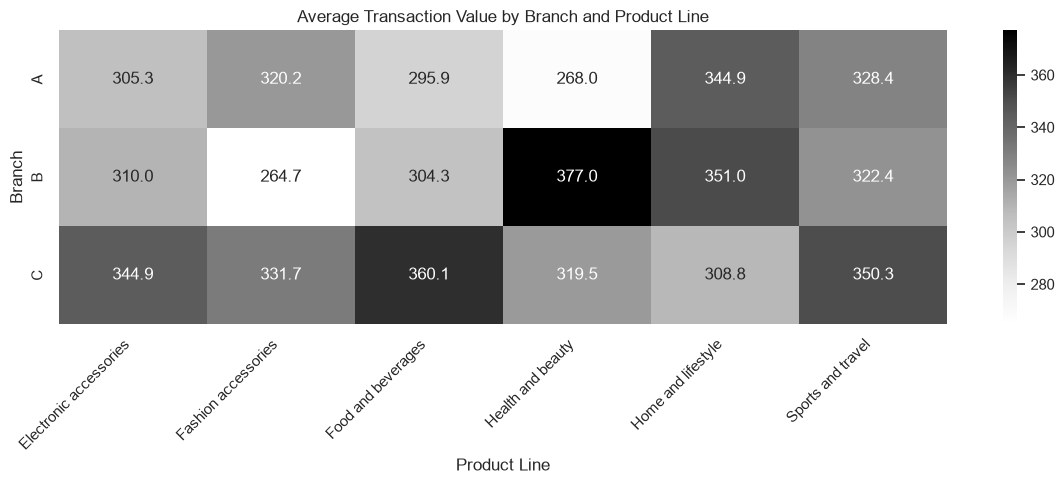


Highest Revenue Product Line in Each Branch:


,Branch,Product line,Revenue,Transactions
4,A,Home and lifestyle,22417.20,65
11,B,Sports and travel,19988.20,62
14,C,Food and beverages,23766.86,66



B6.2 - Customer Type, Payment Method and Spending


,Customer type,Payment,Transactions,Revenue,Average_Transaction,Median_Transaction
0,Member,Cash,168,54661.02,325.36,255.78
1,Member,Credit card,172,57771.47,335.88,275.00
2,Member,Ewallet,161,51790.96,321.68,270.02
3,Normal,Cash,176,57545.55,326.96,270.26
4,Normal,Credit card,139,42995.60,309.32,202.82
5,Normal,Ewallet,184,58202.15,316.32,239.20


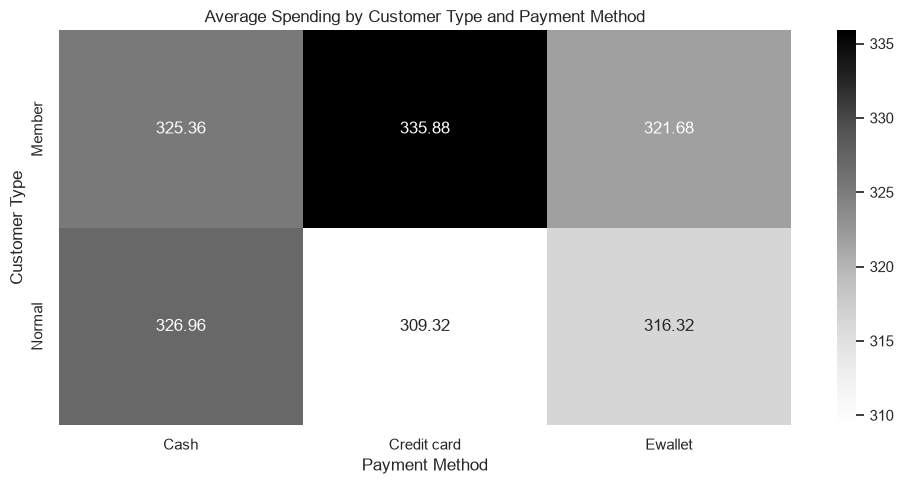

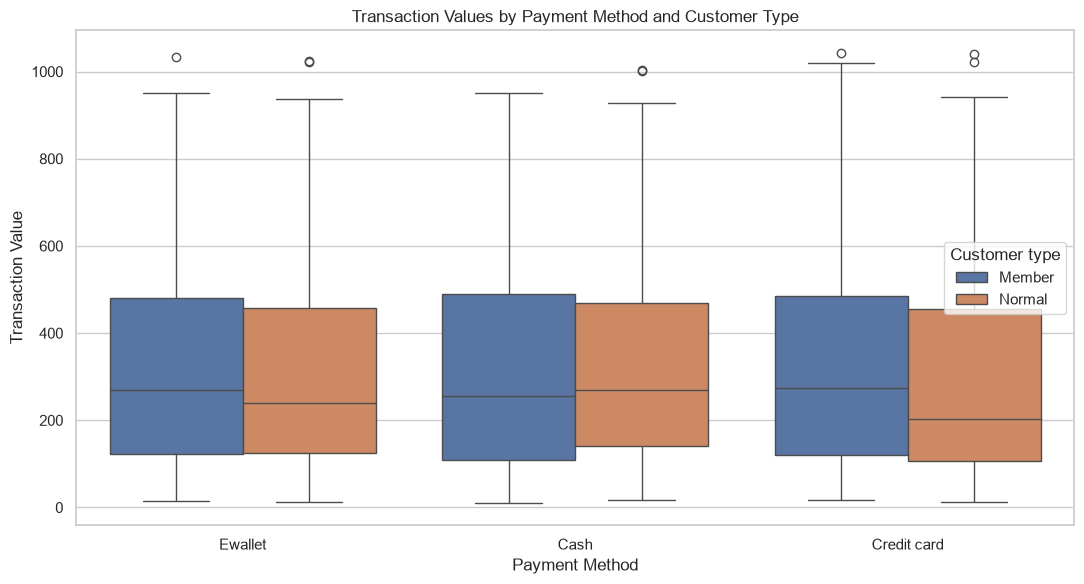


Overall Average Spending by Customer Type:


Customer type
Member    327.79
Normal    318.12
Name: Total, dtype: float64


Member Minus Normal Average Spending by Payment:


Payment
Cash           -1.60
Credit card    26.56
Ewallet         5.37
dtype: float64


B6.3 - Branch, Product Line and Customer Ratings


,Branch,Product line,Average_Rating,Median_Rating,Rating_Std,Transactions
0,A,Electronic accessories,6.91,6.80,1.71,60
1,A,Fashion accessories,6.88,7.20,1.60,51
2,A,Food and beverages,7.25,7.45,1.75,58
3,A,Health and beauty,6.90,6.80,1.80,47
4,A,Home and lifestyle,6.93,7.00,1.84,65
5,A,Sports and travel,7.26,7.40,1.69,59
6,B,Electronic accessories,7.12,7.00,1.54,55
7,B,Fashion accessories,6.72,6.70,1.70,62
8,B,Food and beverages,6.99,6.55,1.69,50
9,B,Health and beauty,7.10,7.70,1.86,53


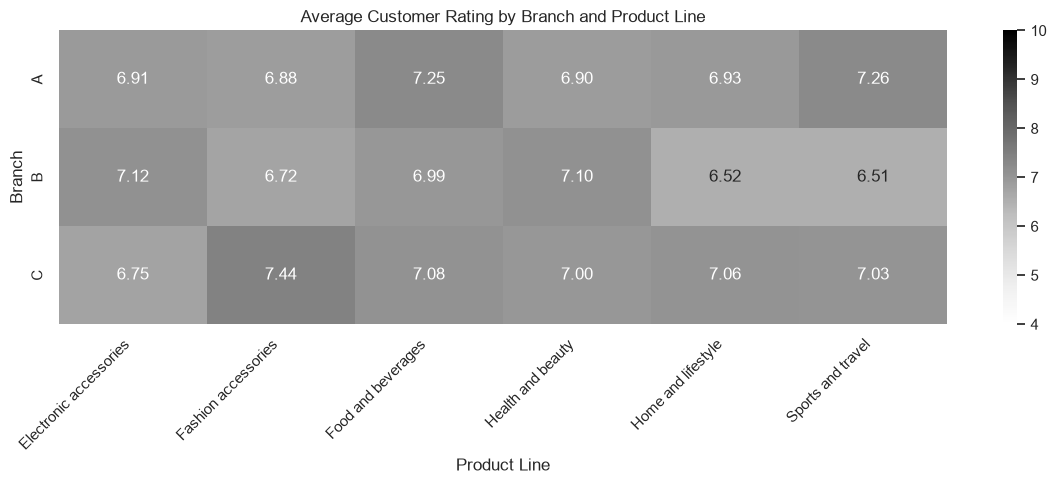


Overall Ratings by Branch:


,count,mean,median,std
Branch,,,,
A,340,7.03,7.1,1.73
B,332,6.82,6.7,1.71
C,328,7.07,7.1,1.70



B7.1 - Product Revenue and Average Transaction Rankings


,Product line,Transactions,Revenue,Average_Transaction,Quantity_Sold,Revenue_Rank,Average_Transaction_Rank
2,Food and beverages,174,56144.84,322.67,952,1,4
5,Sports and travel,166,55122.83,332.07,920,2,2
0,Electronic accessories,170,54337.53,319.63,971,3,5
1,Fashion accessories,178,54305.90,305.09,902,4,6
4,Home and lifestyle,160,53861.91,336.64,911,5,1
3,Health and beauty,152,49193.74,323.64,854,6,3


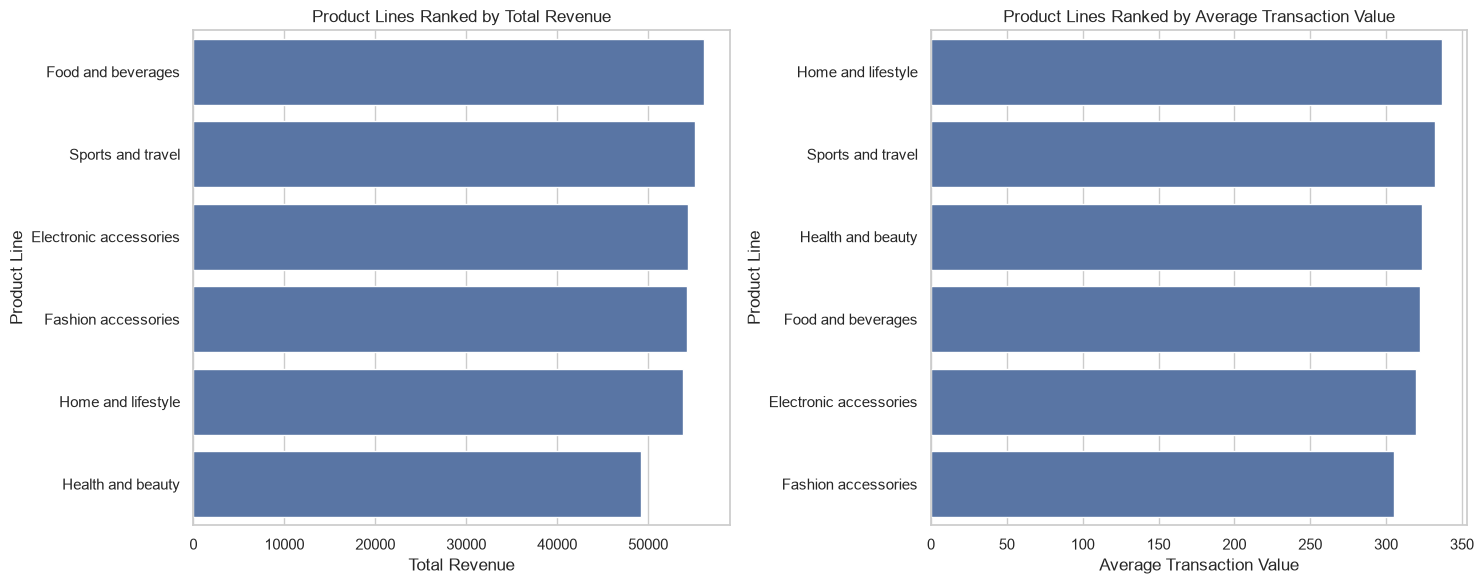

Highest Total Revenue: Food and beverages 56144.84
Highest Average Transaction: Home and lifestyle 336.64

B7.2 - Branch and City Performance


,Branch,City,Transactions,Revenue,Quantity_Sold,Average_Transaction,Transaction_Std,Average_Rating,Rating_Std
0,A,Yangon,340,106200.37,1859,312.35,231.64,7.03,1.73
1,B,Mandalay,332,106197.67,1820,319.87,242.45,6.82,1.71
2,C,Naypyitaw,328,110568.71,1831,337.10,263.16,7.07,1.70



Difference Between Highest and Lowest Average Transaction:
24.75

Average Within-Branch Transaction Standard Deviation:
245.75


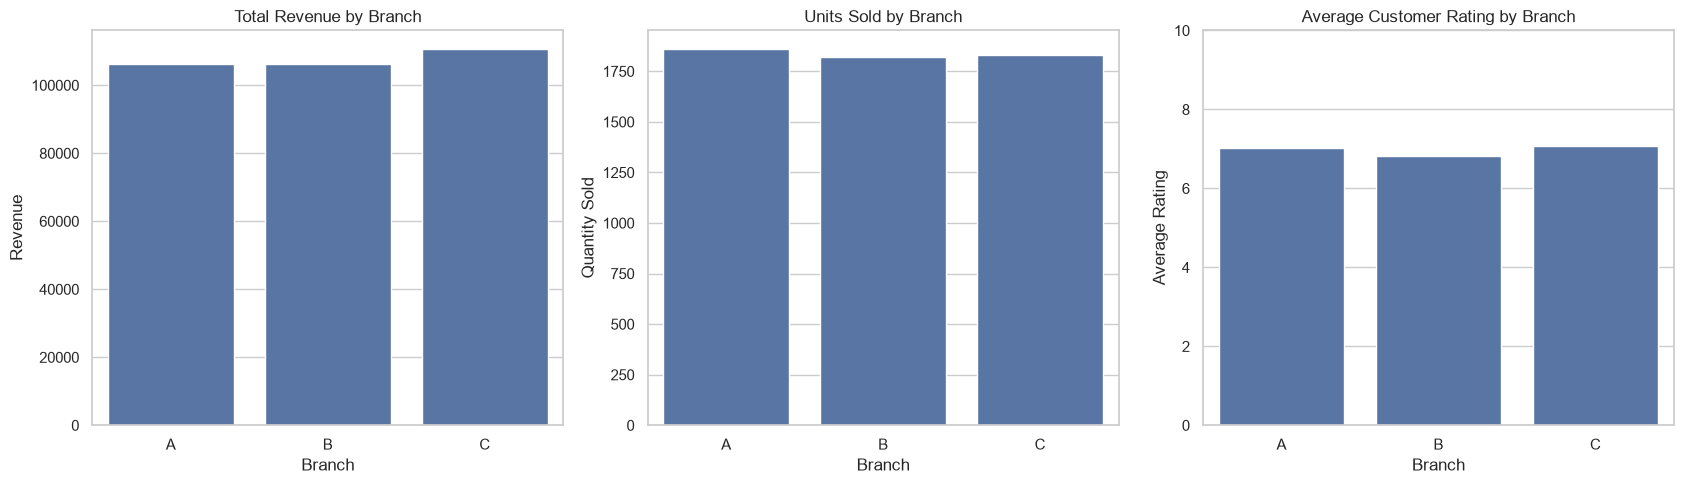


B7.3 - Customer Type and Payment Method Spending

Customer Type Summary:


,Transactions,Revenue,Average_Transaction,Median_Transaction
Customer type,,,,
Member,501,164223.44,327.79,266.03
Normal,499,158743.30,318.12,237.43



Payment Method Summary:


,Transactions,Revenue,Average_Transaction,Median_Transaction
Payment,,,,
Cash,344,112206.57,326.18,262.96
Credit card,311,100767.07,324.01,239.59
Ewallet,345,109993.11,318.82,253.68



Customer Type and Payment Combined:


,Customer type,Payment,Transactions,Revenue,Average_Transaction
0,Member,Cash,168,54661.02,325.36
1,Member,Credit card,172,57771.47,335.88
2,Member,Ewallet,161,51790.96,321.68
3,Normal,Cash,176,57545.55,326.96
4,Normal,Credit card,139,42995.60,309.32
5,Normal,Ewallet,184,58202.15,316.32


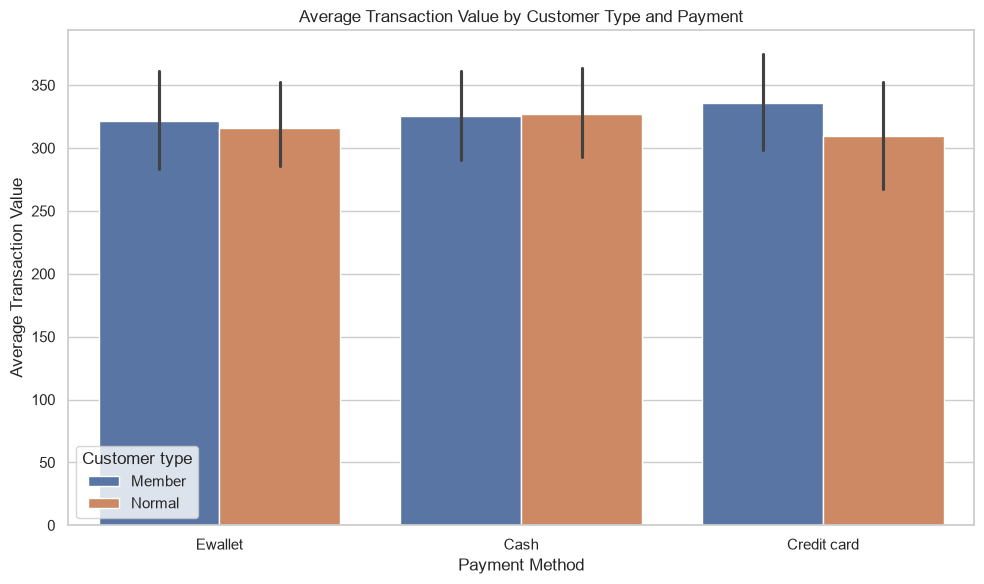


B7.4 - Sales by Month, Weekday and Hour

Monthly Sales:


,Month,Month_Name,Revenue,Transactions,Average_Transaction,Quantity_Sold
0,1,January,116291.87,352,330.37,1965
1,2,February,97219.37,303,320.86,1654
2,3,March,109455.51,345,317.26,1891



Weekday Sales:


,Weekday,Revenue,Transactions,Average_Transaction
0,Monday,37899.08,125,303.19
1,Tuesday,51482.25,158,325.84
2,Wednesday,43731.14,143,305.81
3,Thursday,45349.25,138,328.62
4,Friday,43926.34,139,316.02
5,Saturday,56120.81,164,342.20
6,Sunday,44457.89,133,334.27



Hourly Sales:


,Hour,Revenue,Transactions,Average_Transaction
0,10,31421.48,101,311.10
1,11,30377.33,90,337.53
2,12,26065.88,89,292.88
3,13,34723.23,103,337.12
4,14,30828.40,83,371.43
5,15,31179.51,102,305.68
6,16,25226.32,77,327.61
7,17,24445.22,74,330.34
8,18,26030.34,93,279.90
9,19,39699.51,113,351.32


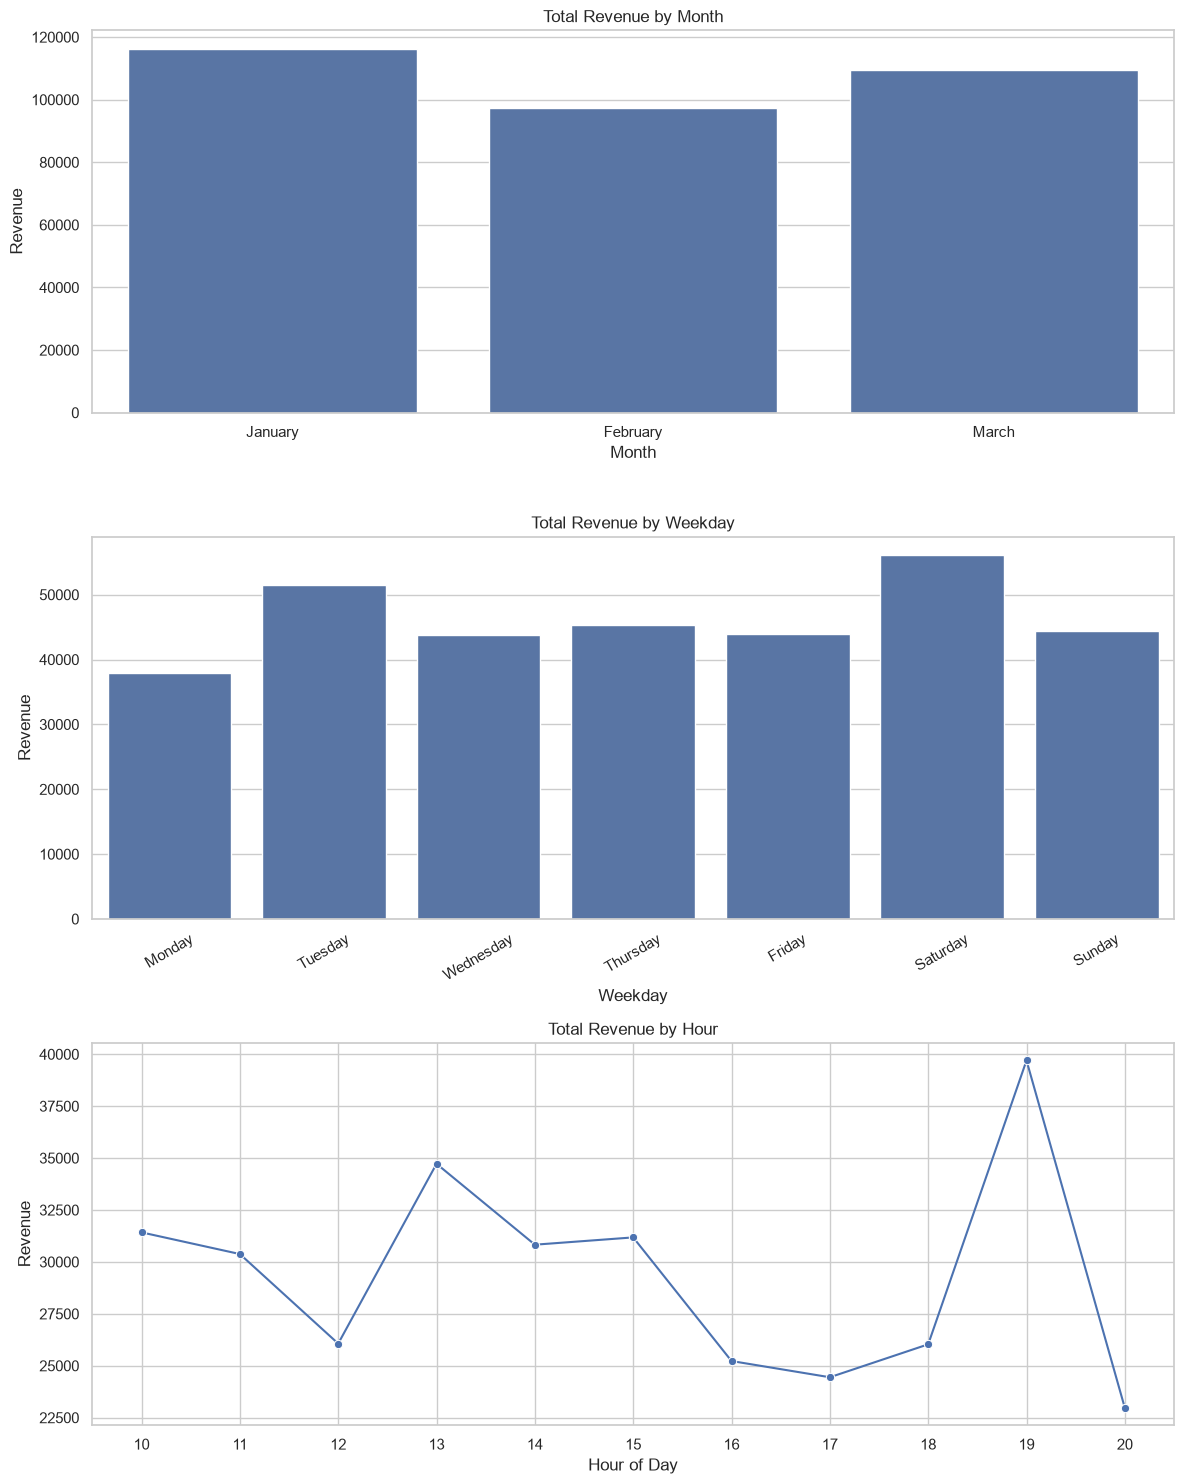


Highest Revenue Month:


,Month,Month_Name,Revenue,Transactions,Average_Transaction,Quantity_Sold
0,1,January,116291.868,352,330.374625,1965



Highest Revenue Weekday:


,Weekday,Revenue,Transactions,Average_Transaction
5,Saturday,56120.8095,164,342.200058



Highest Revenue Hour:


...

Unit price   -0.0088
Quantity     -0.0158
Total        -0.0364
Name: Customer stratification rating, dtype: float64


Ratings by Product Line:


,Product line,Transactions,Average_Rating,Median_Rating,Rating_Std
2,Food and beverages,174,7.11,7.30,1.72
1,Fashion accessories,178,7.03,6.95,1.71
3,Health and beauty,152,7.00,7.20,1.76
0,Electronic accessories,170,6.92,6.70,1.70
5,Sports and travel,166,6.92,6.70,1.71
4,Home and lifestyle,160,6.84,7.00,1.72



Ratings by Branch:


,Branch,Transactions,Average_Rating,Rating_Std
0,A,340,7.03,1.73
1,B,332,6.82,1.71
2,C,328,7.07,1.70


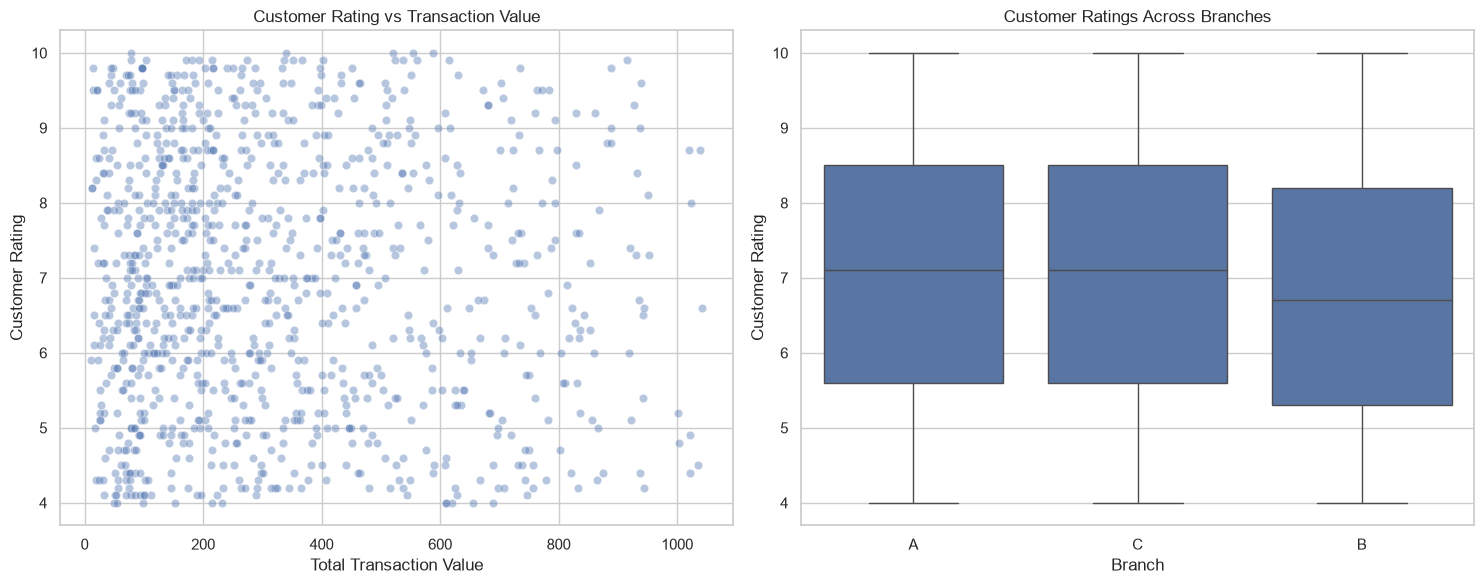

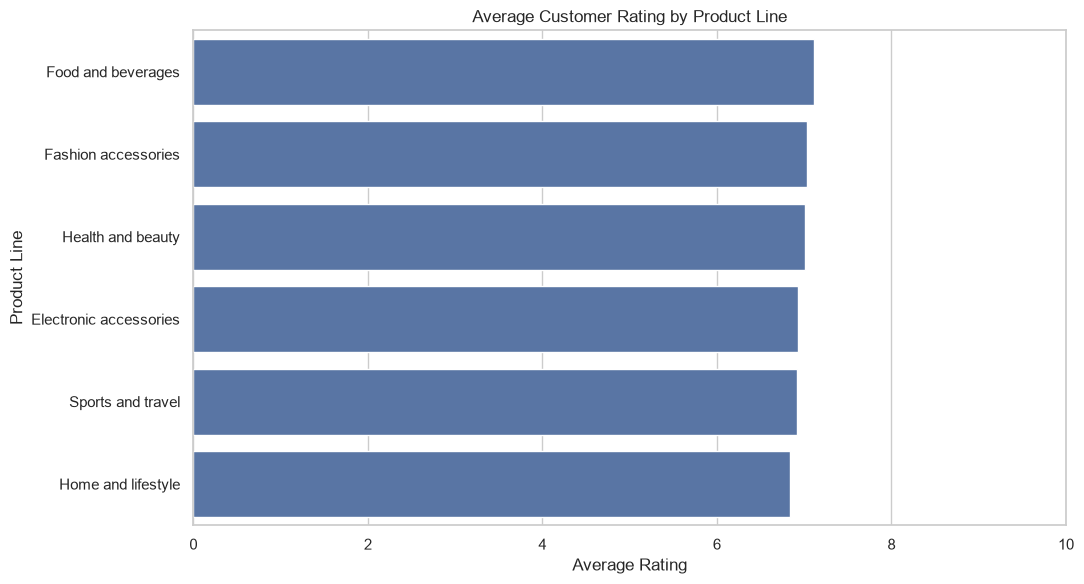


B8.1 - Final Supermarket Summary
Total Transactions: 1000
Total Revenue: 322966.75
Total Quantity Sold: 5510
Average Transaction Value: 322.97
Average Customer Rating: 6.97

Highest Revenue Product Line: Food and beverages
Product Line Revenue: 56144.84

Highest Revenue Branch: C
Branch City: Naypyitaw
Branch Revenue: 110568.71

Highest Revenue Month: January
Month Revenue: 116291.87

Highest Revenue Day: Saturday
Day Revenue: 56120.81

Highest Revenue Hour: 19
Hour Revenue: 39699.51

B8.2 - Five Key Insights
1. Highest-revenue product line: Food and beverages (56144.84).
2. Highest-revenue branch: C in Naypyitaw (110568.71).
3. Average Member spending: 327.79; Average Normal spending: 318.12.
4. Highest-revenue periods: January, Saturday, and 19:00.
5. Transaction Total vs Rating correlation: -0.036.

B8.5 - Final Dataset Verification
Original Shape: (1000, 17)
Cleaned Shape: (1000, 21)
Exported Shape: (1000, 21)
Duplicate Invoice IDs: 0
Missing Values: 0

Final Supermarket Dataset E

In [81]:

# ============================================================
# B6. MULTIVARIATE EXPLORATORY DATA ANALYSIS
# ============================================================

# In this section, I examined relationships between three
# or more variables to understand how supermarket sales
# patterns change when additional factors are considered.
#
# The analysis focuses on:
# 1. Branch, product line, and total revenue.
# 2. Customer type, payment method, and transaction value.
# 3. Branch, product line, and customer ratings.
#
# I used grouped summaries, heatmaps, and box plots to
# compare the different groups.
#
# These comparisons describe patterns in the dataset.
# They do not establish causal relationships.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rating_col = "Customer stratification rating"

# Use a consistent, simple plotting style.
sns.set_theme(style="whitegrid")


# ============================================================
# B6.1 BRANCH, PRODUCT LINE, AND REVENUE
# ============================================================

# Explanation:
# I wanted to examine whether the product categories
# generating the most revenue are the same across branches.
#
# The variables used are Branch, Product line, and Total.
# A heatmap is useful because it compares several categories
# across the three branches at the same time.
#
# I also calculated revenue per transaction so that differences
# in transaction counts do not completely determine the results.

print("\nB6.1 - Branch, Product Line and Revenue")

branch_product_summary = (
    sales_clean
    .groupby(["Branch", "Product line"])
    .agg(
        Transactions=("Invoice ID", "count"),
        Revenue=("Total", "sum"),
        Average_Transaction=("Total", "mean")
    )
    .reset_index()
)

display(branch_product_summary.round(2))

branch_product_revenue = branch_product_summary.pivot(
    index="Branch",
    columns="Product line",
    values="Revenue"
)

plt.figure(figsize=(12, 5))
sns.heatmap(
    branch_product_revenue,
    annot=True,
    fmt=".0f",
    cmap="Greys"
)
plt.title("Total Revenue by Branch and Product Line")
plt.xlabel("Product Line")
plt.ylabel("Branch")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

branch_product_average = branch_product_summary.pivot(
    index="Branch",
    columns="Product line",
    values="Average_Transaction"
)

plt.figure(figsize=(12, 5))
sns.heatmap(
    branch_product_average,
    annot=True,
    fmt=".1f",
    cmap="Greys"
)
plt.title("Average Transaction Value by Branch and Product Line")
plt.xlabel("Product Line")
plt.ylabel("Branch")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nHighest Revenue Product Line in Each Branch:")
top_product_each_branch = (
    branch_product_summary
    .sort_values("Revenue", ascending=False)
    .drop_duplicates("Branch")
    .sort_values("Branch")
)

display(
    top_product_each_branch[
        ["Branch", "Product line", "Revenue", "Transactions"]
    ].round(2)
)

# Interpretation:
# The revenue heatmap shows how sales from each product
# line vary between branches.
#
# The highest-revenue product line can be different for
# different branches, meaning that the overall product
# ranking does not necessarily apply equally everywhere.
#
# The second heatmap shows average spending per transaction
# within each branch and product category.
#
# Comparing the two heatmaps helps distinguish categories
# with high revenue due to frequent transactions from those
# with relatively high spending per transaction.
#
# Use the printed highest-revenue table to identify the
# leading product category for each branch.
#
# These differences may reflect local purchasing patterns,
# but the dataset does not establish their causes.


# ============================================================
# B6.2 CUSTOMER TYPE, PAYMENT METHOD, AND SPENDING
# ============================================================

# Explanation:
# I examined whether spending patterns differ between
# Member and Normal customers when payment method is
# also considered.
#
# The variables are Customer type, Payment, and Total.
#
# I calculated both average transaction value and total
# revenue for each combination.
#
# This allows me to determine whether an apparent difference
# between customer groups changes across payment methods.

print("\nB6.2 - Customer Type, Payment Method and Spending")

customer_payment_summary = (
    sales_clean
    .groupby(["Customer type", "Payment"])
    .agg(
        Transactions=("Invoice ID", "count"),
        Revenue=("Total", "sum"),
        Average_Transaction=("Total", "mean"),
        Median_Transaction=("Total", "median")
    )
    .reset_index()
)

display(customer_payment_summary.round(2))

customer_payment_pivot = customer_payment_summary.pivot(
    index="Customer type",
    columns="Payment",
    values="Average_Transaction"
)

plt.figure(figsize=(10, 5))
sns.heatmap(
    customer_payment_pivot,
    annot=True,
    fmt=".2f",
    cmap="Greys"
)
plt.title("Average Spending by Customer Type and Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Customer Type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=sales_clean,
    x="Payment",
    y="Total",
    hue="Customer type"
)

plt.title("Transaction Values by Payment Method and Customer Type")
plt.xlabel("Payment Method")
plt.ylabel("Transaction Value")
plt.tight_layout()
plt.show()

print("\nOverall Average Spending by Customer Type:")
display(
    sales_clean
    .groupby("Customer type")["Total"]
    .mean()
    .round(2)
)

print("\nMember Minus Normal Average Spending by Payment:")
payment_difference = (
    customer_payment_pivot.loc["Member"]
    - customer_payment_pivot.loc["Normal"]
)
display(payment_difference.round(2))

# Interpretation:
# The analysis compares the spending of Member and Normal
# customers within each payment method.
#
# The overall average may suggest that one customer type
# spends slightly more than the other.
#
# However, the heatmap and box plot help determine whether
# this difference remains similar for Cash, Credit card,
# and Ewallet transactions.
#
# The printed differences show how the Member-Normal gap
# changes across payment methods.
#
# This is why considering the third variable, Payment,
# provides more information than comparing customer types
# using a single overall average.
#
# Differences are descriptive and should not be treated
# as evidence that membership causes higher spending.


# ============================================================
# B6.3 BRANCH, PRODUCT LINE, AND CUSTOMER RATING
# ============================================================

# Explanation:
# I examined whether customer ratings vary across product
# categories and whether these patterns differ by branch.
#
# The three variables are Branch, Product line, and
# Customer stratification rating.
#
# Average ratings were calculated for each group.
# Transaction counts were also included because averages
# from very small groups are less reliable.

print("\nB6.3 - Branch, Product Line and Customer Ratings")

branch_rating_summary = (
    sales_clean
    .groupby(["Branch", "Product line"])
    .agg(
        Average_Rating=(rating_col, "mean"),
        Median_Rating=(rating_col, "median"),
        Rating_Std=(rating_col, "std"),
        Transactions=("Invoice ID", "count")
    )
    .reset_index()
)

display(branch_rating_summary.round(2))

branch_rating_pivot = branch_rating_summary.pivot(
    index="Branch",
    columns="Product line",
    values="Average_Rating"
)

plt.figure(figsize=(12, 5))
sns.heatmap(
    branch_rating_pivot,
    annot=True,
    fmt=".2f",
    cmap="Greys",
    vmin=4,
    vmax=10
)
plt.title("Average Customer Rating by Branch and Product Line")
plt.xlabel("Product Line")
plt.ylabel("Branch")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nOverall Ratings by Branch:")
display(
    sales_clean.groupby("Branch")[rating_col]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

# Interpretation:
# Customer ratings are not necessarily identical across
# product categories or supermarket branches.
#
# The heatmap allows me to compare each product line within
# each branch instead of relying only on overall branch
# averages.
#
# A product category with a relatively high rating in one
# branch may have a different average in another branch.
#
# The grouped transaction counts are important because
# small differences in average ratings may simply reflect
# variation between customers.
#
# This analysis demonstrates how adding Product line changes
# the comparison of ratings across branches.
#
# The results do not prove that a particular branch or
# product category causes higher customer satisfaction.


# ============================================================
# B7. SUPERMARKET-SPECIFIC ANALYTICAL QUESTIONS
# ============================================================

# This section answers the five specific questions required
# for the Supermarket Sales dataset.
#
# Some relationships were also explored in B5 and B6.
# They are summarized here to provide direct answers.


# ============================================================
# B7.1 PRODUCT REVENUE VS AVERAGE TRANSACTION RANKING
# ============================================================

# Question:
# Which product lines generate the most revenue, and does
# this ranking change when average transaction value is used?
#
# Explanation:
# Total revenue measures the contribution of each category
# to overall sales.
#
# Average transaction value measures spending per recorded
# transaction in that category.
#
# Comparing both rankings helps identify whether categories
# are successful due to transaction frequency or the average
# amount spent.

print("\nB7.1 - Product Revenue and Average Transaction Rankings")

product_summary = (
    sales_clean
    .groupby("Product line")
    .agg(
        Transactions=("Invoice ID", "count"),
        Revenue=("Total", "sum"),
        Average_Transaction=("Total", "mean"),
        Quantity_Sold=("Quantity", "sum")
    )
    .reset_index()
)

product_summary["Revenue_Rank"] = (
    product_summary["Revenue"]
    .rank(ascending=False, method="min")
    .astype(int)
)

product_summary["Average_Transaction_Rank"] = (
    product_summary["Average_Transaction"]
    .rank(ascending=False, method="min")
    .astype(int)
)

product_summary = product_summary.sort_values("Revenue_Rank")

display(product_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=product_summary,
    x="Revenue",
    y="Product line",
    ax=axes[0]
)
axes[0].set_title("Product Lines Ranked by Total Revenue")
axes[0].set_xlabel("Total Revenue")
axes[0].set_ylabel("Product Line")

sns.barplot(
    data=product_summary.sort_values(
        "Average_Transaction", ascending=False
    ),
    x="Average_Transaction",
    y="Product line",
    ax=axes[1]
)
axes[1].set_title("Product Lines Ranked by Average Transaction Value")
axes[1].set_xlabel("Average Transaction Value")
axes[1].set_ylabel("Product Line")

plt.tight_layout()
plt.show()

revenue_leader = product_summary.loc[
    product_summary["Revenue"].idxmax()
]

average_leader = product_summary.loc[
    product_summary["Average_Transaction"].idxmax()
]

print(
    "Highest Total Revenue:",
    revenue_leader["Product line"],
    round(revenue_leader["Revenue"], 2)
)

print(
    "Highest Average Transaction:",
    average_leader["Product line"],
    round(average_leader["Average_Transaction"], 2)
)

# Interpretation:
# Food and beverages generates the highest total revenue,
# approximately 56,144.84.
#
# Total revenue should be interpreted alongside the number
# of transactions because a frequently purchased category
# can generate high revenue without having the highest
# average transaction value.
#
# The two rankings show whether the leading category changes
# when average transaction size is considered instead of
# overall revenue.
#
# The printed leaders and rank columns provide the exact
# comparison required by the assignment.


# ============================================================
# B7.2 BRANCH AND CITY PERFORMANCE
# ============================================================

# Question:
# How do branches and cities compare in revenue, quantity,
# and customer ratings?
#
# Are differences in average transaction values large
# compared with the variation within each branch?
#
# Explanation:
# I calculated revenue, quantity, transaction count, average
# transaction value, and customer ratings for each branch.
#
# I also calculated the standard deviation of transaction
# values to compare differences between branch averages
# with variation within individual branches.

print("\nB7.2 - Branch and City Performance")

branch_summary = (
    sales_clean
    .groupby(["Branch", "City"])
    .agg(
        Transactions=("Invoice ID", "count"),
        Revenue=("Total", "sum"),
        Quantity_Sold=("Quantity", "sum"),
        Average_Transaction=("Total", "mean"),
        Transaction_Std=("Total", "std"),
        Average_Rating=(rating_col, "mean"),
        Rating_Std=(rating_col, "std")
    )
    .reset_index()
    .sort_values("Branch")
)

display(branch_summary.round(2))

print(
    "\nDifference Between Highest and Lowest Average Transaction:"
)

mean_difference = (
    branch_summary["Average_Transaction"].max()
    - branch_summary["Average_Transaction"].min()
)

print(round(mean_difference, 2))

print("\nAverage Within-Branch Transaction Standard Deviation:")
print(round(branch_summary["Transaction_Std"].mean(), 2))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(
    data=branch_summary,
    x="Branch",
    y="Revenue",
    ax=axes[0]
)
axes[0].set_title("Total Revenue by Branch")
axes[0].set_xlabel("Branch")
axes[0].set_ylabel("Revenue")

sns.barplot(
    data=branch_summary,
    x="Branch",
    y="Quantity_Sold",
    ax=axes[1]
)
axes[1].set_title("Units Sold by Branch")
axes[1].set_xlabel("Branch")
axes[1].set_ylabel("Quantity Sold")

sns.barplot(
    data=branch_summary,
    x="Branch",
    y="Average_Rating",
    ax=axes[2]
)
axes[2].set_title("Average Customer Rating by Branch")
axes[2].set_xlabel("Branch")
axes[2].set_ylabel("Average Rating")
axes[2].set_ylim(0, 10)

plt.tight_layout()
plt.show()

# Interpretation:
# Branch C in Naypyitaw generates the highest total revenue,
# approximately 110,568.71, and the highest average
# transaction value, approximately 337.10.
#
# Branch A in Yangon records the highest number of units
# sold, with 1,859 units.
#
# The branches have relatively similar transaction counts.
#
# The difference between the highest and lowest average
# transaction values should be compared with the standard
# deviations printed above.
#
# If the difference between branch means is small relative
# to within-branch variation, the observed differences
# should not be overstated.
#
# Branch and City identify the same three locations in this
# dataset, so their effects cannot be separated statistically.
#
# Differences in customer ratings are descriptive and do
# not establish differences in service quality.


# ============================================================
# B7.3 CUSTOMER TYPE, PAYMENT, AND SPENDING
# ============================================================

# Question:
# How does spending differ between Member and Normal
# customers and across different payment methods?
#
# Explanation:
# I compared average spending, median spending, and total
# revenue for both customer types and all payment methods.
#
# I also examined their combinations to see whether the
# patterns remain consistent after considering both variables.

print("\nB7.3 - Customer Type and Payment Method Spending")

customer_summary = (
    sales_clean
    .groupby("Customer type")
    .agg(
        Transactions=("Invoice ID", "count"),
        Revenue=("Total", "sum"),
        Average_Transaction=("Total", "mean"),
        Median_Transaction=("Total", "median")
    )
)

print("\nCustomer Type Summary:")
display(customer_summary.round(2))

payment_summary = (
    sales_clean
    .groupby("Payment")
    .agg(
        Transactions=("Invoice ID", "count"),
        Revenue=("Total", "sum"),
        Average_Transaction=("Total", "mean"),
        Median_Transaction=("Total", "median")
    )
)

print("\nPayment Method Summary:")
display(payment_summary.round(2))

combined_spending = (
    sales_clean
    .groupby(["Customer type", "Payment"])
    .agg(
        Transactions=("Invoice ID", "count"),
        Revenue=("Total", "sum"),
        Average_Transaction=("Total", "mean")
    )
    .reset_index()
)

print("\nCustomer Type and Payment Combined:")
display(combined_spending.round(2))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=sales_clean,
    x="Payment",
    y="Total",
    hue="Customer type",
    errorbar=("ci", 95)
)
plt.title("Average Transaction Value by Customer Type and Payment")
plt.xlabel("Payment Method")
plt.ylabel("Average Transaction Value")
plt.tight_layout()
plt.show()

# Interpretation:
# Member customers account for 501 transactions, with an
# average transaction value of approximately 327.79.
#
# Normal customers account for 499 transactions, with an
# average value of approximately 318.12.
#
# The difference is relatively small.
#
# Ewallet is the most frequently used payment method,
# followed closely by Cash.
#
# However, the most frequently used payment method does
# not necessarily produce the highest average spending.
#
# Considering both customer type and payment method helps
# identify whether spending differences are consistent
# across customer groups.
#
# These results describe associations, not causal effects.


# ============================================================
# B7.4 SALES BY MONTH, WEEKDAY, AND HOUR
# ============================================================

# Question:
# How do sales vary by month, weekday, and hour?
#
# Explanation:
# I used the derived temporal variables created in B3.
#
# Total revenue identifies periods that contribute more
# to overall sales, while transaction counts and average
# transaction values help explain those totals.
#
# The dataset covers a limited time period, so the results
# should not be treated as long-term seasonal patterns.

print("\nB7.4 - Sales by Month, Weekday and Hour")

# Monthly sales

monthly_sales = (
    sales_clean
    .groupby(["Month", "Month_Name"])
    .agg(
        Revenue=("Total", "sum"),
        Transactions=("Invoice ID", "count"),
        Average_Transaction=("Total", "mean"),
        Quantity_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Month")
)

print("\nMonthly Sales:")
display(monthly_sales.round(2))

# Weekday sales

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    sales_clean
    .groupby("Weekday")
    .agg(
        Revenue=("Total", "sum"),
        Transactions=("Invoice ID", "count"),
        Average_Transaction=("Total", "mean")
    )
    .reindex(weekday_order)
    .reset_index()
)

print("\nWeekday Sales:")
display(weekday_sales.round(2))

# Hourly sales

hourly_sales = (
    sales_clean
    .groupby("Hour")
    .agg(
        Revenue=("Total", "sum"),
        Transactions=("Invoice ID", "count"),
        Average_Transaction=("Total", "mean")
    )
    .reset_index()
    .sort_values("Hour")
)

print("\nHourly Sales:")
display(hourly_sales.round(2))

fig, axes = plt.subplots(3, 1, figsize=(12, 15))

sns.barplot(
    data=monthly_sales,
    x="Month_Name",
    y="Revenue",
    ax=axes[0]
)
axes[0].set_title("Total Revenue by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")

sns.barplot(
    data=weekday_sales,
    x="Weekday",
    y="Revenue",
    ax=axes[1]
)
axes[1].set_title("Total Revenue by Weekday")
axes[1].set_xlabel("Weekday")
axes[1].set_ylabel("Revenue")
axes[1].tick_params(axis="x", rotation=30)

sns.lineplot(
    data=hourly_sales,
    x="Hour",
    y="Revenue",
    marker="o",
    ax=axes[2]
)
axes[2].set_title("Total Revenue by Hour")
axes[2].set_xlabel("Hour of Day")
axes[2].set_ylabel("Revenue")
axes[2].set_xticks(hourly_sales["Hour"])

plt.tight_layout()
plt.show()

print("\nHighest Revenue Month:")
display(monthly_sales.nlargest(1, "Revenue"))

print("\nHighest Revenue Weekday:")
display(weekday_sales.nlargest(1, "Revenue"))

print("\nHighest Revenue Hour:")
display(hourly_sales.nlargest(1, "Revenue"))

# Interpretation:
# January generated the highest monthly revenue,
# approximately 116,291.87.
#
# Saturday recorded the highest weekday revenue,
# approximately 56,120.81.
#
# The 19:00 hour generated the highest hourly revenue,
# approximately 39,699.51.
#
# These periods also differ in their transaction counts.
# Therefore, high total revenue may be partly explained
# by a larger number of recorded transactions.
#
# The dataset covers only January to March of a single year,
# so these results should not be generalized into annual
# seasonal trends.
#
# The analysis identifies patterns in the recorded sales,
# not necessarily the supermarket's long-term performance.


# ============================================================
# B7.5 CUSTOMER RATINGS AND SALES CHARACTERISTICS
# ============================================================

# Question:
# How do customer ratings relate to unit price, quantity,
# product line, and branch?
#
# Explanation:
# I calculated correlations between customer ratings and
# the numerical variables Unit price, Quantity, and Total.
#
# I also compared average ratings across product lines
# and branches.
#
# This helps determine whether spending characteristics
# or transaction categories are associated with differences
# in customer ratings.

print("\nB7.5 - Customer Ratings and Sales Characteristics")

rating_variables = [
    "Unit price",
    "Quantity",
    "Total",
    rating_col
]

rating_correlations = (
    sales_clean[rating_variables]
    .corr()
)

print("\nCorrelation Matrix:")
display(rating_correlations.round(3))

print("\nCorrelations with Customer Rating:")
display(
    rating_correlations[rating_col]
    .drop(rating_col)
    .round(4)
)

# Ratings by product line

product_rating = (
    sales_clean
    .groupby("Product line")
    .agg(
        Transactions=("Invoice ID", "count"),
        Average_Rating=(rating_col, "mean"),
        Median_Rating=(rating_col, "median"),
        Rating_Std=(rating_col, "std")
    )
    .reset_index()
    .sort_values("Average_Rating", ascending=False)
)

print("\nRatings by Product Line:")
display(product_rating.round(2))

# Ratings by branch

branch_rating = (
    sales_clean
    .groupby("Branch")
    .agg(
        Transactions=("Invoice ID", "count"),
        Average_Rating=(rating_col, "mean"),
        Rating_Std=(rating_col, "std")
    )
    .reset_index()
)

print("\nRatings by Branch:")
display(branch_rating.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=sales_clean,
    x="Total",
    y=rating_col,
    alpha=0.4,
    ax=axes[0]
)
axes[0].set_title("Customer Rating vs Transaction Value")
axes[0].set_xlabel("Total Transaction Value")
axes[0].set_ylabel("Customer Rating")

sns.boxplot(
    data=sales_clean,
    x="Branch",
    y=rating_col,
    ax=axes[1]
)
axes[1].set_title("Customer Ratings Across Branches")
axes[1].set_xlabel("Branch")
axes[1].set_ylabel("Customer Rating")

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 6))
sns.barplot(
    data=product_rating,
    x="Average_Rating",
    y="Product line"
)
plt.title("Average Customer Rating by Product Line")
plt.xlabel("Average Rating")
plt.ylabel("Product Line")
plt.xlim(0, 10)
plt.tight_layout()
plt.show()

# Interpretation:
# Customer ratings have a very weak linear relationship
# with transaction value.
#
# The Pearson correlation between Total and Rating is
# approximately -0.036.
#
# This means that customers who spend more do not
# consistently provide higher or lower ratings.
#
# The additional correlations help determine whether
# Unit price or Quantity has a stronger association
# with ratings.
#
# Average ratings also vary slightly across product lines
# and branches.
#
# However, differences in group averages should be
# considered alongside the standard deviations.
#
# A weak correlation does not prove that price, quantity,
# or branch has no effect on customer satisfaction.
# It only describes the relationships visible here.


# ============================================================
# B8. INSIGHTS AND ASSIGNMENT 3 HANDOFF
# ============================================================

# In this section, I summarized five findings from the
# Supermarket Sales exploratory analysis.
#
# Each finding is supported by numerical results from
# the dataset.
#
# I also included a short handoff note describing how
# the cleaned data can be reused in Assignment 3.


# ============================================================
# B8.1 FINAL SUMMARY STATISTICS
# ============================================================

print("\nB8.1 - Final Supermarket Summary")

total_transactions = len(sales_clean)
total_revenue = sales_clean["Total"].sum()
total_quantity = sales_clean["Quantity"].sum()
average_transaction = sales_clean["Total"].mean()
average_rating = sales_clean[rating_col].mean()

print("Total Transactions:", total_transactions)
print("Total Revenue:", round(total_revenue, 2))
print("Total Quantity Sold:", total_quantity)
print("Average Transaction Value:", round(average_transaction, 2))
print("Average Customer Rating:", round(average_rating, 2))

top_product = product_summary.loc[
    product_summary["Revenue"].idxmax()
]

top_branch = branch_summary.loc[
    branch_summary["Revenue"].idxmax()
]

top_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmax()
]

top_day = weekday_sales.loc[
    weekday_sales["Revenue"].idxmax()
]

top_hour = hourly_sales.loc[
    hourly_sales["Revenue"].idxmax()
]

print("\nHighest Revenue Product Line:", top_product["Product line"])
print("Product Line Revenue:", round(top_product["Revenue"], 2))

print("\nHighest Revenue Branch:", top_branch["Branch"])
print("Branch City:", top_branch["City"])
print("Branch Revenue:", round(top_branch["Revenue"], 2))

print("\nHighest Revenue Month:", top_month["Month_Name"])
print("Month Revenue:", round(top_month["Revenue"], 2))

print("\nHighest Revenue Day:", top_day["Weekday"])
print("Day Revenue:", round(top_day["Revenue"], 2))

print("\nHighest Revenue Hour:", int(top_hour["Hour"]))
print("Hour Revenue:", round(top_hour["Revenue"], 2))


# ============================================================
# B8.2 FIVE KEY INSIGHTS
# ============================================================

# Insight 1: Food and beverages generates the most revenue.
#
# Observation:
# Food and beverages generated approximately 56,144.84,
# making it the highest-revenue product category.
#
# Interpretation:
# This category makes the largest contribution to total
# revenue in the recorded transactions.
#
# However, this does not necessarily mean it has the
# highest average transaction value.
#
# Revenue rankings should therefore be considered
# alongside transaction counts and average spending.


# Insight 2: Branch C generates the highest revenue.
#
# Observation:
# Branch C in Naypyitaw generated approximately 110,568.71
# in total revenue.
#
# It also had the highest average transaction value,
# approximately 337.10.
#
# Interpretation:
# Branch C slightly outperformed the other branches
# in recorded revenue and average spending.
#
# However, branch averages overlap considerably, and
# the differences should not be interpreted as proof
# that one branch is inherently more successful.


# Insight 3: Member customers spend slightly more on average.
#
# Observation:
# Member customers had an average transaction value of
# approximately 327.79, compared with 318.12 for
# Normal customers.
#
# Interpretation:
# Members spent slightly more per recorded transaction.
#
# The difference is relatively small and does not
# establish that membership itself increases spending.
#
# Other factors could contribute to the observed pattern.


# Insight 4: Sales activity varies across time periods.
#
# Observation:
# January generated approximately 116,291.87 in revenue.
#
# Saturday generated the highest weekday revenue,
# approximately 56,120.81.
#
# The 19:00 hour generated the highest hourly revenue,
# approximately 39,699.51.
#
# Interpretation:
# Sales activity is not distributed equally across
# months, weekdays, and hours.
#
# These differences may be related to the number of
# transactions recorded during each period.
#
# The limited date range means they should not be
# treated as reliable long-term seasonal patterns.


# Insight 5: Spending and customer ratings are weakly related.
#
# Observation:
# The Pearson correlation between transaction value
# and customer rating is approximately -0.036.
#
# Interpretation:
# There is almost no linear relationship between
# total spending and recorded customer ratings.
#
# Customers who spend more do not consistently provide
# higher or lower ratings.
#
# This suggests that transaction value alone is not
# sufficient to explain rating differences.
#
# Other available variables may be considered in
# future analysis, although causality cannot be inferred.


# Print concise evidence-backed insights

print("\nB8.2 - Five Key Insights")

insights = [
    (
        "1. Highest-revenue product line: "
        f"{top_product['Product line']} "
        f"({top_product['Revenue']:.2f})."
    ),
    (
        "2. Highest-revenue branch: "
        f"{top_branch['Branch']} in {top_branch['City']} "
        f"({top_branch['Revenue']:.2f})."
    ),
    (
        "3. Average Member spending: "
        f"{customer_summary.loc['Member', 'Average_Transaction']:.2f}; "
        "Average Normal spending: "
        f"{customer_summary.loc['Normal', 'Average_Transaction']:.2f}."
    ),
    (
        "4. Highest-revenue periods: "
        f"{top_month['Month_Name']}, "
        f"{top_day['Weekday']}, "
        f"and {int(top_hour['Hour'])}:00."
    ),
    (
        "5. Transaction Total vs Rating correlation: "
        f"{rating_sales_corr:.3f}."
    )
]

for insight in insights:
    print(insight)


# ============================================================
# B8.3 ASSIGNMENT 3 HANDOFF NOTE
# ============================================================

# The following note is under 150 words.
#
# Handoff Note:
#
# The cleaned Supermarket Sales dataset contains 1,000
# transactions and includes useful variables such as
# product line, branch, customer type, payment method,
# quantity, transaction total, and customer rating.
#
# Date and Time were converted into suitable formats,
# and Month, Month_Name, Weekday, and Hour were created
# for time-based analysis.
#
# Invoice ID should be treated as an identifier rather
# than a predictive feature. Branch and City are directly
# linked in this dataset, so they provide overlapping
# location information.
#
# Total, Cost of goods sold, Tax 5%, and Gross income
# are mathematically related, which may cause misleading
# correlations or data leakage in predictive modelling.
#
# Gross margin percentage is constant and provides no
# variation for modelling. No transactions were removed,
# and unusual numerical values were retained unless
# evidence showed they were incorrect.


# ============================================================
# B8.4 DATASET PUBLICATION AND VERSIONING
# ============================================================

# Original Source:
# Supermarket Sales dataset supplied by the instructor.
#
# Cleaned Filename:
# 23L_0977_A2_supermarket_cleaned.csv
#
# Planned Version:
# v1.0
#
# Public Dataset URL:
# Add the actual GitHub or Kaggle link after publication.
#
# The public repository should include a README covering
# the original source, cleaning decisions, added variables,
# publication date, and dataset version.
#
# The real public URL and version must also be included
# in the notebook introduction and writeup.pdf.
#
# Do not claim that the dataset has been published until
# the public link is working.


# ============================================================
# B8.5 FINAL DATASET EXPORT AND VERIFICATION
# ============================================================

# Export the final version again to ensure that the required
# CSV exists and contains the latest cleaned data.

sales_clean.to_csv(
    "23L_0977_A2_supermarket_cleaned.csv",
    index=False
)

# Verify saved file
sales_verified = pd.read_csv(
    "23L_0977_A2_supermarket_cleaned.csv"
)

print("\nB8.5 - Final Dataset Verification")

print("Original Shape:", sales_df.shape)
print("Cleaned Shape:", sales_clean.shape)
print("Exported Shape:", sales_verified.shape)

print(
    "Duplicate Invoice IDs:",
    sales_verified["Invoice ID"].duplicated().sum()
)

print(
    "Missing Values:",
    sales_verified.isnull().sum().sum()
)

assert len(sales_verified) == len(sales_df), (
    "The exported dataset has an unexpected row count."
)

assert sales_verified["Invoice ID"].is_unique, (
    "The exported dataset contains duplicate Invoice IDs."
)

print("\nFinal Supermarket Dataset Export Successful.")


# ============================================================
# B8.6 PART B CONCLUSION
# ============================================================

# The Supermarket Sales exploratory analysis helped me
# understand the structure, quality, and main patterns
# of the transaction dataset.
#
# I first examined missing values, duplicate records,
# categorical consistency, numerical validity, and
# financial calculations.
#
# The dataset was generally clean, so the main preprocessing
# work involved converting dates and times and creating
# additional variables for temporal analysis.
#
# The univariate analysis described typical transaction
# values, quantities, customer ratings, and category
# frequencies.
#
# The bivariate and multivariate analyses compared sales
# across branches, product lines, customer types, payment
# methods, and different time periods.
#
# The results showed that Food and beverages generated
# the highest product-line revenue, while Branch C recorded
# the highest branch revenue.
#
# Customer ratings had a negligible linear relationship
# with spending.
#
# Overall, the cleaned dataset and the findings provide
# a suitable foundation for further analysis in Assignment 3.

print("\nPART B COMPLETED: B6, B7 AND B8")
